In [7]:
# ============================================================
# CÉLULA 1: CONFIGURAÇÃO DO NOTEBOOK 03A.04
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Preparar o ambiente para investigar o efeito do volume
# histórico de dados sobre a capacidade preditiva da Iatan
# Unit 2.
#
# PERGUNTA CENTRAL
# ------------------------------------------------------------
#
# A ampliação do histórico de treinamento melhora de forma
# consistente a capacidade de prever emissões futuras de CO2
# da Iatan Unit 2?
#
# PRINCÍPIO EXPERIMENTAL
# ------------------------------------------------------------
#
# Nesta etapa será mantido fixo:
#
#   algoritmo:
#       XGBoost
#
#   cenário:
#       A
#
#   representação:
#       CO2(t) = f(P(t))
#
#   feature:
#       load_current_mw
#
# A variável experimental será:
#
#       quantidade de histórico disponível para treinamento.
#
# Dessa forma, eventuais diferenças de desempenho poderão ser
# associadas ao volume e à abrangência temporal dos dados,
# sem confundir esse efeito com alterações de features ou tuning.
# ============================================================


# ============================================================
# 1. IMPORTAÇÕES
# ============================================================

from google.colab import drive, userdata
from pathlib import Path

import json
import random
import warnings
import requests
import time
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import xgboost as xgb

from xgboost import XGBRegressor

from IPython.display import (
    display,
    Markdown
)


# ============================================================
# 2. REPRODUTIBILIDADE
# ============================================================

warnings.filterwarnings(
    "ignore"
)

SEED = 42

random.seed(
    SEED
)

np.random.seed(
    SEED
)


print(
    "XGBoost:",
    xgb.__version__
)


# ============================================================
# 3. GOOGLE DRIVE
# ============================================================

drive.mount(
    "/content/drive"
)


# ============================================================
# 4. PASTA PRINCIPAL
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/co2-cems-thermal-modeling"
)


DATA = (
    ROOT
    /
    "data"
)


DATA_RAW = (
    DATA
    /
    "raw"
)


DATA_INTERIM = (
    DATA
    /
    "interim"
)


DATA_PROCESSED = (
    DATA
    /
    "processed"
)


OUTPUT = (
    ROOT
    /
    "outputs"
)


REPORTS = (
    OUTPUT
    /
    "reports"
)


FIGURES = (
    OUTPUT
    /
    "figures"
)


TABLES = (
    OUTPUT
    /
    "tables"
)


MODELS = (
    OUTPUT
    /
    "models"
)


PIPELINE_DIR = (
    ROOT
    /
    "pipeline"
)


# ============================================================
# 5. DIRETÓRIO ESPECÍFICO DO EXPERIMENTO MULTIANUAL
# ============================================================
#
# Os arquivos horários históricos poderão ser grandes.
#
# Por isso, criamos uma pasta própria dentro de data/interim.
# ============================================================

MULTIYEAR_DIR = (
    DATA_INTERIM
    /
    "03A04_multiyear"
)


TEMP_DIR = Path(
    "/content/epa_03A04_temp"
)


for folder in [

    REPORTS,
    FIGURES,
    TABLES,
    MODELS,
    MULTIYEAR_DIR,
    TEMP_DIR

]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 6. IDENTIFICAÇÃO DA UNIDADE
# ============================================================

CONFIG_PATH = (
    PIPELINE_DIR
    /
    "selected_unit.json"
)


if not CONFIG_PATH.exists():

    raise FileNotFoundError(
        "selected_unit.json não encontrado."
    )


with open(
    CONFIG_PATH,
    "r",
    encoding="utf-8"
) as f:

    selected_unit = json.load(
        f
    )


FACILITY_ID = str(
    selected_unit[
        "facility_id"
    ]
)


UNIT_ID = str(
    selected_unit[
        "unit_id"
    ]
)


FACILITY_NAME = str(
    selected_unit[
        "facility_name"
    ]
)


STATE = str(
    selected_unit[
        "state"
    ]
).upper()


REFERENCE_YEAR = int(
    selected_unit[
        "year"
    ]
)


# ============================================================
# 7. GARANTIR QUE CONTINUAMOS NA IATAN UNIT 2
# ============================================================

if not (

    FACILITY_ID == "6065"

    and

    UNIT_ID == "2"

):

    raise ValueError(

        "O Notebook 03A.04 foi planejado para "
        "Iatan Unit 2, mas selected_unit.json "
        "aponta para outra unidade."

    )


# ============================================================
# 8. API DA EPA
# ============================================================

EPA_API_KEY = (

    userdata
    .get(
        "EPA_API_KEY"
    )
    .strip()

)


session = requests.Session()


session.headers.update({

    "User-Agent":
        "co2-cems-thermal-modeling"

})


def epa_get(
    url,
    params=None,
    timeout=120
):

    params = (
        {}
        if params is None
        else dict(params)
    )


    params[
        "api_key"
    ] = EPA_API_KEY


    response = session.get(

        url,

        params=params,

        timeout=timeout

    )


    if response.status_code != 200:

        print(
            "STATUS:",
            response.status_code
        )

        print(
            response.text[
                :1000
            ]
        )


    response.raise_for_status()

    return response


# ============================================================
# 9. ENDPOINTS EPA
# ============================================================

CATALOG_URL = (

    "https://api.epa.gov/easey/"
    "camd-services/bulk-files"

)


BULK_URL = (

    "https://api.epa.gov/"
    "easey/bulk-files/"

)


# ============================================================
# 10. CENÁRIO PREDITIVO DE REFERÊNCIA
# ============================================================

TARGET = (
    "CO2 Mass (short tons)"
)


FEATURES_A = [

    "load_current_mw"

]


# ============================================================
# 11. XGBOOST DE REFERÊNCIA
# ============================================================
#
# Reproduzimos a configuração do Notebook 03A.02.
#
# Não haverá tuning neste notebook.
#
# O objetivo não é descobrir novamente o melhor algoritmo,
# mas verificar o efeito de aumentar a quantidade de dados.
# ============================================================

XGB_PARAMS = {

    "objective":
        "reg:squarederror",

    "n_estimators":
        3000,

    "learning_rate":
        0.03,

    "max_depth":
        4,

    "min_child_weight":
        5,

    "subsample":
        0.80,

    "colsample_bytree":
        0.80,

    "reg_alpha":
        0.0,

    "reg_lambda":
        1.0,

    "eval_metric":
        "rmse",

    "early_stopping_rounds":
        50,

    "random_state":
        SEED,

    "n_jobs":
        -1

}


# ============================================================
# 12. FUNÇÕES DE MÉTRICAS
# ============================================================

def regression_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true
    )

    y_pred = np.asarray(
        y_pred
    )


    mae = mean_absolute_error(
        y_true,
        y_pred
    )


    rmse = np.sqrt(

        mean_squared_error(
            y_true,
            y_pred
        )

    )


    r2 = r2_score(
        y_true,
        y_pred
    )


    mean_observed = np.mean(
        y_true
    )


    nmae = (

        100
        *
        mae
        /
        mean_observed

        if mean_observed != 0

        else np.nan

    )


    denominator = np.sum(
        np.abs(
            y_true
        )
    )


    wape = (

        100
        *
        np.sum(
            np.abs(
                y_true
                -
                y_pred
            )
        )
        /
        denominator

        if denominator != 0

        else np.nan

    )


    bias = np.mean(

        y_true
        -
        y_pred

    )


    return {

        "MAE":
            mae,

        "RMSE":
            rmse,

        "R2":
            r2,

        "NMAE_%":
            nmae,

        "WAPE_%":
            wape,

        "Bias":
            bias

    }


def build_xgb():

    return XGBRegressor(
        **XGB_PARAMS
    )


# ============================================================
# 13. RESUMO
# ============================================================

print("=" * 72)

print(
    "NOTEBOOK 03A.04"
)

print(
    "VOLUME DE DADOS E GENERALIZAÇÃO TEMPORAL"
)

print("=" * 72)


print(
    "\nUnidade:"
)

print(
    f"{FACILITY_NAME} — Unit {UNIT_ID}"
)


print(
    "Facility ID:",
    FACILITY_ID
)


print(
    "Estado:",
    STATE
)


print(
    "Ano utilizado nos experimentos anteriores:",
    REFERENCE_YEAR
)


print(
    "\nCenário mantido fixo:"
)

print(
    "A-XGBoost"
)


print(
    "Features:",
    FEATURES_A
)


print(
    "\nPergunta experimental:"
)

print(
    "Mais histórico melhora a previsão temporal da Iatan?"
)

XGBoost: 3.4.1
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NOTEBOOK 03A.04
VOLUME DE DADOS E GENERALIZAÇÃO TEMPORAL

Unidade:
Iatan — Unit 2
Facility ID: 6065
Estado: MO
Ano utilizado nos experimentos anteriores: 2025

Cenário mantido fixo:
A-XGBoost
Features: ['load_current_mw']

Pergunta experimental:
Mais histórico melhora a previsão temporal da Iatan?


In [8]:
# ============================================================
# CÉLULA 2: CATÁLOGO HISTÓRICO DE DADOS HORÁRIOS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Descobrir quais arquivos horários de emissões estão
# efetivamente disponíveis para o estado da unidade selecionada.
#
# Ainda NÃO baixamos os arquivos horários.
#
# Esta célula serve exclusivamente para:
#
#   1. consultar o catálogo EPA;
#   2. identificar os anos disponíveis;
#   3. verificar se 2026 já possui arquivo;
#   4. evitar assumir previamente o intervalo histórico.
# ============================================================


# ============================================================
# 1. CONSULTAR CATÁLOGO
# ============================================================

response = epa_get(

    CATALOG_URL,

    timeout=120

)


catalog = pd.json_normalize(

    response.json()[
        "items"
    ]

)


print(
    "Arquivos no catálogo EPA:",
    f"{len(catalog):,}"
)


# ============================================================
# 2. FILTRAR ARQUIVOS HORÁRIOS DE EMISSÕES
# ============================================================

hourly_catalog = (

    catalog[

        (
            catalog[
                "metadata.dataType"
            ]
            ==
            "Emissions"
        )

        &

        (
            catalog[
                "metadata.dataSubType"
            ]
            ==
            "Hourly"
        )

    ]

    .copy()

)


# ============================================================
# 3. NORMALIZAR ANO E ESTADO
# ============================================================

hourly_catalog[
    "year"
] = pd.to_numeric(

    hourly_catalog[
        "metadata.year"
    ],

    errors="coerce"

)


hourly_catalog[
    "stateCode"
] = (

    hourly_catalog[
        "metadata.stateCode"
    ]

    .astype(str)

    .str.upper()

    .str.strip()

)


# ============================================================
# 4. FILTRAR O ESTADO DA IATAN
# ============================================================

state_hourly_files = (

    hourly_catalog[

        hourly_catalog[
            "stateCode"
        ]

        ==

        STATE

    ]

    .copy()

    .sort_values(
        "year"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 5. SELECIONAR COLUNAS ÚTEIS
# ============================================================

catalog_columns = [

    c

    for c in [

        "year",
        "stateCode",
        "filename",
        "s3Path",
        "metadata.dataType",
        "metadata.dataSubType"

    ]

    if c in state_hourly_files.columns

]


state_hourly_summary = (

    state_hourly_files[
        catalog_columns
    ]

    .copy()

)


# ============================================================
# 6. RESULTADOS
# ============================================================

if state_hourly_files.empty:

    raise ValueError(
        f"Nenhum arquivo horário encontrado para {STATE}."
    )


years_available = (

    state_hourly_files[
        "year"
    ]

    .dropna()

    .astype(int)

    .sort_values()

    .unique()

    .tolist()

)


print("=" * 72)

print(
    "ARQUIVOS HORÁRIOS DISPONÍVEIS PARA",
    STATE
)

print("=" * 72)


print(
    "\nPrimeiro ano disponível:",
    min(
        years_available
    )
)


print(
    "Último ano disponível:",
    max(
        years_available
    )
)


print(
    "Número de anos:",
    len(
        years_available
    )
)


print(
    "\nAnos:"
)

print(
    years_available
)


display(
    state_hourly_summary
)

Arquivos no catálogo EPA: 235,457
ARQUIVOS HORÁRIOS DISPONÍVEIS PARA MO

Primeiro ano disponível: 1995
Último ano disponível: 2025
Número de anos: 31

Anos:
[1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


,year,stateCode,filename,s3Path,metadata.dataType,metadata.dataSubType
0,1995,MO,emissions-hourly-1995-mo.csv,emissions/hourly/state/emissions-hourly-1995-m...,Emissions,Hourly
1,1996,MO,emissions-hourly-1996-mo.csv,emissions/hourly/state/emissions-hourly-1996-m...,Emissions,Hourly
2,1997,MO,emissions-hourly-1997-mo.csv,emissions/hourly/state/emissions-hourly-1997-m...,Emissions,Hourly
3,1998,MO,emissions-hourly-1998-mo.csv,emissions/hourly/state/emissions-hourly-1998-m...,Emissions,Hourly
4,1999,MO,emissions-hourly-1999-mo.csv,emissions/hourly/state/emissions-hourly-1999-m...,Emissions,Hourly
5,2000,MO,emissions-hourly-2000-mo.csv,emissions/hourly/state/emissions-hourly-2000-m...,Emissions,Hourly
6,2001,MO,emissions-hourly-2001-mo.csv,emissions/hourly/state/emissions-hourly-2001-m...,Emissions,Hourly
7,2002,MO,emissions-hourly-2002-mo.csv,emissions/hourly/state/emissions-hourly-2002-m...,Emissions,Hourly
8,2003,MO,emissions-hourly-2003-mo.csv,emissions/hourly/state/emissions-hourly-2003-m...,Emissions,Hourly
9,2004,MO,emissions-hourly-2004-mo.csv,emissions/hourly/state/emissions-hourly-2004-m...,Emissions,Hourly


In [9]:
# ============================================================
# CÉLULA 4: EXTRAÇÃO HISTÓRICA DA IATAN UNIT 2
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Percorrer todos os arquivos horários estaduais disponíveis
# para Missouri e extrair exclusivamente:
#
#     Facility ID = 6065
#     Unit ID     = 2
#
# Esta etapa permitirá descobrir:
#
#   1. em quais anos a Iatan Unit 2 realmente aparece;
#   2. quantidade de registros disponíveis por ano;
#   3. cobertura de carga e CO2;
#   4. período temporal efetivamente utilizável;
#   5. eventuais mudanças de schema entre anos.
#
# IMPORTANTE
# ------------------------------------------------------------
# Ainda NÃO estamos escolhendo o período de treinamento.
#
# Primeiro será construída a série histórica disponível.
#
# Cada ano encontrado será salvo separadamente em:
#
# data/interim/03A04_multiyear/
#
# Os arquivos estaduais completos permanecem apenas
# temporariamente no Colab e são apagados após o processamento.
#
# A célula é reiniciável:
# se o parquet anual já existir, ele será reutilizado.
# ============================================================


# ============================================================
# 1. FUNÇÕES DE NORMALIZAÇÃO
# ============================================================

def norm_facility_id(x):

    if pd.isna(x):
        return None

    try:

        return str(
            int(
                float(x)
            )
        )

    except (ValueError, TypeError):

        return str(
            x
        ).strip()


def norm_unit_id(x):

    if pd.isna(x):
        return None

    x = (
        str(x)
        .strip()
        .upper()
    )

    x = re.sub(
        r"\.0$",
        "",
        x
    )

    if re.fullmatch(
        r"\d+",
        x
    ):

        x = str(
            int(x)
        )

    return x


FACILITY_ID_NORM = norm_facility_id(
    FACILITY_ID
)

UNIT_ID_NORM = norm_unit_id(
    UNIT_ID
)


# ============================================================
# 2. COLUNAS DE INTERESSE
# ============================================================

REQUIRED_COLUMNS = [

    "Facility ID",
    "Unit ID",
    "Date",
    "Hour",
    "Operating Time",
    "Gross Load (MW)",
    "CO2 Mass (short tons)"

]


OPTIONAL_COLUMNS = [

    "CO2 Mass Measure Indicator"

]


# ============================================================
# 3. PREPARAR LISTA DE ARQUIVOS
# ============================================================

files_to_process = (

    state_hourly_files

    .copy()

    .sort_values(
        "year"
    )

    .reset_index(
        drop=True
    )

)


print("=" * 72)

print(
    "EXTRAÇÃO HISTÓRICA DA IATAN UNIT 2"
)

print("=" * 72)


print(
    "\nFacility ID:",
    FACILITY_ID_NORM
)


print(
    "Unit ID:",
    UNIT_ID_NORM
)


print(
    "Estado:",
    STATE
)


print(
    "Arquivos estaduais a verificar:",
    len(
        files_to_process
    )
)


print(
    "Período do catálogo:",
    int(
        files_to_process[
            "year"
        ].min()
    ),
    "→",
    int(
        files_to_process[
            "year"
        ].max()
    )
)


# ============================================================
# 4. RESULTADOS DE AUDITORIA
# ============================================================

audit_results = []


# ============================================================
# 5. PROCESSAR ANO A ANO
# ============================================================

for i, row in enumerate(

    files_to_process.itertuples(
        index=False
    ),

    start=1

):


    year = int(
        row.year
    )


    filename = str(
        row.filename
    )


    s3_path = str(
        row.s3Path
    ).lstrip("/")


    download_url = (

        BULK_URL
        +
        s3_path

    )


    temp_file = (

        TEMP_DIR
        /
        filename

    )


    output_file = (

        MULTIYEAR_DIR
        /
        f"iatan_unit2_{year}.parquet"

    )


    print("\n" + "-" * 72)

    print(
        f"[{i}/{len(files_to_process)}] "
        f"ANO {year}"
    )

    print(
        filename
    )


    # ========================================================
    # 5.1. SE JÁ FOI EXTRAÍDO, REUTILIZAR
    # ========================================================

    if output_file.exists():

        try:

            selected_year = pd.read_parquet(
                output_file
            )


            print(
                "Arquivo anual já existente."
            )

            print(
                "Registros:",
                f"{len(selected_year):,}"
            )


            if len(selected_year) > 0:

                date_min = pd.to_datetime(

                    selected_year[
                        "timestamp"
                    ],

                    errors="coerce"

                ).min()


                date_max = pd.to_datetime(

                    selected_year[
                        "timestamp"
                    ],

                    errors="coerce"

                ).max()


                n_operating = int(

                    (
                        pd.to_numeric(

                            selected_year[
                                "Operating Time"
                            ],

                            errors="coerce"

                        )
                        >
                        0
                    ).sum()

                )


                load_valid = int(

                    pd.to_numeric(

                        selected_year[
                            "Gross Load (MW)"
                        ],

                        errors="coerce"

                    )
                    .notna()
                    .sum()

                )


                co2_valid = int(

                    pd.to_numeric(

                        selected_year[
                            "CO2 Mass (short tons)"
                        ],

                        errors="coerce"

                    )
                    .notna()
                    .sum()

                )


            else:

                date_min = pd.NaT
                date_max = pd.NaT
                n_operating = 0
                load_valid = 0
                co2_valid = 0


            audit_results.append({

                "year":
                    year,

                "status":
                    "cached",

                "n_records":
                    len(
                        selected_year
                    ),

                "n_operating":
                    n_operating,

                "load_valid":
                    load_valid,

                "co2_valid":
                    co2_valid,

                "date_min":
                    date_min,

                "date_max":
                    date_max,

                "file_size_mb":
                    np.nan,

                "missing_columns":
                    ""

            })


            continue


        except Exception as e:

            print(
                "Falha ao ler cache:"
            )

            print(
                str(e)
            )

            print(
                "Arquivo será baixado novamente."
            )


    # ========================================================
    # 5.2. DOWNLOAD COM ATÉ 3 TENTATIVAS
    # ========================================================

    download_ok = False


    for tentativa in range(
        1,
        4
    ):

        try:

            with session.get(

                download_url,

                params={
                    "api_key":
                        EPA_API_KEY
                },

                stream=True,

                timeout=(
                    30,
                    300
                )

            ) as response:


                print(
                    f"Download tentativa "
                    f"{tentativa}: "
                    f"HTTP "
                    f"{response.status_code}"
                )


                response.raise_for_status()


                with open(
                    temp_file,
                    "wb"
                ) as f:


                    for block in response.iter_content(

                        chunk_size=
                            1024
                            *
                            1024

                    ):


                        if block:

                            f.write(
                                block
                            )


            download_ok = True

            break


        except Exception as e:

            print(
                "Falha no download:",
                str(e)
            )


            if tentativa < 3:

                time.sleep(
                    10
                )


    if not download_ok:

        audit_results.append({

            "year":
                year,

            "status":
                "download_error",

            "n_records":
                0,

            "n_operating":
                0,

            "load_valid":
                0,

            "co2_valid":
                0,

            "date_min":
                pd.NaT,

            "date_max":
                pd.NaT,

            "file_size_mb":
                np.nan,

            "missing_columns":
                ""

        })


        continue


    file_size_mb = (

        temp_file.stat().st_size
        /
        1024
        /
        1024

    )


    print(
        "Tamanho:",
        f"{file_size_mb:.2f} MB"
    )


    # ========================================================
    # 5.3. VERIFICAR SCHEMA
    # ========================================================

    try:

        header = pd.read_csv(

            temp_file,

            nrows=0

        )


    except Exception as e:

        print(
            "Erro ao ler cabeçalho:"
        )

        print(
            str(e)
        )


        audit_results.append({

            "year":
                year,

            "status":
                "header_error",

            "n_records":
                0,

            "n_operating":
                0,

            "load_valid":
                0,

            "co2_valid":
                0,

            "date_min":
                pd.NaT,

            "date_max":
                pd.NaT,

            "file_size_mb":
                file_size_mb,

            "missing_columns":
                "header_error"

        })


        if temp_file.exists():

            temp_file.unlink()


        continue


    available_columns = set(
        header.columns
    )


    missing_columns = [

        column

        for column in REQUIRED_COLUMNS

        if column not in available_columns

    ]


    # ========================================================
    # 5.4. SE O SCHEMA FOR DIFERENTE, REGISTRAR
    # ========================================================

    if missing_columns:

        print(
            "Colunas obrigatórias ausentes:"
        )

        print(
            missing_columns
        )


        audit_results.append({

            "year":
                year,

            "status":
                "schema_incompatible",

            "n_records":
                0,

            "n_operating":
                0,

            "load_valid":
                0,

            "co2_valid":
                0,

            "date_min":
                pd.NaT,

            "date_max":
                pd.NaT,

            "file_size_mb":
                file_size_mb,

            "missing_columns":
                "; ".join(
                    missing_columns
                )

        })


        if temp_file.exists():

            temp_file.unlink()


        continue


    usecols = (
        REQUIRED_COLUMNS
        .copy()
    )


    for column in OPTIONAL_COLUMNS:

        if column in available_columns:

            usecols.append(
                column
            )


    # ========================================================
    # 5.5. EXTRAIR SOMENTE IATAN UNIT 2
    # ========================================================

    selected_chunks = []


    for chunk in pd.read_csv(

        temp_file,

        usecols=usecols,

        chunksize=250_000,

        low_memory=False

    ):


        chunk[
            "facilityId_norm"
        ] = (

            chunk[
                "Facility ID"
            ]

            .apply(
                norm_facility_id
            )

        )


        facility_mask = (

            chunk[
                "facilityId_norm"
            ]

            ==

            FACILITY_ID_NORM

        )


        # ---------------------------------------------
        # Otimização:
        # se o chunk nem possui Facility 6065,
        # não há necessidade de normalizar Unit ID.
        # ---------------------------------------------

        if not facility_mask.any():

            continue


        facility_chunk = (

            chunk.loc[
                facility_mask
            ]

            .copy()

        )


        facility_chunk[
            "unitId_norm"
        ] = (

            facility_chunk[
                "Unit ID"
            ]

            .apply(
                norm_unit_id
            )

        )


        selected = (

            facility_chunk.loc[

                facility_chunk[
                    "unitId_norm"
                ]

                ==

                UNIT_ID_NORM

            ]

            .copy()

        )


        if not selected.empty:

            selected_chunks.append(
                selected
            )


    # ========================================================
    # 5.6. UNIDADE NÃO EXISTE NO ANO
    # ========================================================

    if len(
        selected_chunks
    ) == 0:


        print(
            "Iatan Unit 2 não encontrada."
        )


        audit_results.append({

            "year":
                year,

            "status":
                "unit_not_found",

            "n_records":
                0,

            "n_operating":
                0,

            "load_valid":
                0,

            "co2_valid":
                0,

            "date_min":
                pd.NaT,

            "date_max":
                pd.NaT,

            "file_size_mb":
                file_size_mb,

            "missing_columns":
                ""

        })


        if temp_file.exists():

            temp_file.unlink()


        continue


    # ========================================================
    # 5.7. CONCATENAR REGISTROS DO ANO
    # ========================================================

    selected_year = pd.concat(

        selected_chunks,

        ignore_index=True

    )


    # ========================================================
    # 5.8. CRIAR TIMESTAMP
    # ========================================================

    selected_year[
        "Date"
    ] = pd.to_datetime(

        selected_year[
            "Date"
        ],

        errors="coerce"

    )


    selected_year[
        "Hour"
    ] = pd.to_numeric(

        selected_year[
            "Hour"
        ],

        errors="coerce"

    )


    selected_year[
        "timestamp"
    ] = (

        selected_year[
            "Date"
        ]

        +

        pd.to_timedelta(

            selected_year[
                "Hour"
            ],

            unit="h"

        )

    )


    # ========================================================
    # 5.9. NORMALIZAR VARIÁVEIS NUMÉRICAS
    # ========================================================

    numeric_columns = [

        "Operating Time",
        "Gross Load (MW)",
        "CO2 Mass (short tons)"

    ]


    for column in numeric_columns:

        selected_year[
            column
        ] = pd.to_numeric(

            selected_year[
                column
            ],

            errors="coerce"

        )


    # ========================================================
    # 5.10. ADICIONAR ANO DE ORIGEM
    # ========================================================

    selected_year[
        "source_year"
    ] = year


    # ========================================================
    # 5.11. ORDENAR
    # ========================================================

    selected_year = (

        selected_year

        .sort_values(
            "timestamp"
        )

        .reset_index(
            drop=True
        )

    )


    # ========================================================
    # 5.12. MÉTRICAS DE COBERTURA
    # ========================================================

    n_records = len(
        selected_year
    )


    n_operating = int(

        (
            selected_year[
                "Operating Time"
            ]
            >
            0
        ).sum()

    )


    load_valid = int(

        selected_year[
            "Gross Load (MW)"
        ]

        .notna()

        .sum()

    )


    co2_valid = int(

        selected_year[
            "CO2 Mass (short tons)"
        ]

        .notna()

        .sum()

    )


    date_min = (

        selected_year[
            "timestamp"
        ]
        .min()

    )


    date_max = (

        selected_year[
            "timestamp"
        ]
        .max()

    )


    # ========================================================
    # 5.13. SALVAR PARQUET ANUAL
    # ========================================================

    selected_year.to_parquet(

        output_file,

        index=False

    )


    print(
        "Iatan Unit 2 encontrada."
    )


    print(
        "Registros:",
        f"{n_records:,}"
    )


    print(
        "Horas operacionais:",
        f"{n_operating:,}"
    )


    print(
        "Carga válida:",
        f"{load_valid:,}"
    )


    print(
        "CO2 válido:",
        f"{co2_valid:,}"
    )


    print(
        "Período:",
        date_min,
        "→",
        date_max
    )


    # ========================================================
    # 5.14. REGISTRAR AUDITORIA
    # ========================================================

    audit_results.append({

        "year":
            year,

        "status":
            "found",

        "n_records":
            n_records,

        "n_operating":
            n_operating,

        "load_valid":
            load_valid,

        "co2_valid":
            co2_valid,

        "date_min":
            date_min,

        "date_max":
            date_max,

        "file_size_mb":
            file_size_mb,

        "missing_columns":
            ""

    })


    # ========================================================
    # 5.15. APAGAR ARQUIVO ESTADUAL TEMPORÁRIO
    # ========================================================

    if temp_file.exists():

        temp_file.unlink()


# ============================================================
# 6. CONSTRUIR TABELA DE AUDITORIA
# ============================================================

history_audit = pd.DataFrame(
    audit_results
)


history_audit = (

    history_audit

    .sort_values(
        "year"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 7. SALVAR AUDITORIA
# ============================================================

AUDIT_PATH = (

    TABLES
    /
    "03A04_auditoria_historico_iatan.csv"

)


history_audit.to_csv(

    AUDIT_PATH,

    index=False

)


# ============================================================
# 8. MOSTRAR RESULTADO
# ============================================================

print("\n" + "=" * 72)

print(
    "AUDITORIA HISTÓRICA CONCLUÍDA"
)

print("=" * 72)


display(
    history_audit
)


# ============================================================
# 9. ANOS EM QUE A UNIDADE FOI ENCONTRADA
# ============================================================

years_found = (

    history_audit.loc[

        history_audit[
            "n_records"
        ]
        >
        0,

        "year"

    ]

    .astype(int)

    .tolist()

)


print(
    "\nAnos com registros da Iatan Unit 2:"
)

print(
    years_found
)


if years_found:

    print(
        "\nPrimeiro ano encontrado:",
        min(
            years_found
        )
    )


    print(
        "Último ano encontrado:",
        max(
            years_found
        )
    )


    print(
        "Quantidade de anos:",
        len(
            years_found
        )
    )


# ============================================================
# 10. ANOS COM DADOS OPERACIONAIS UTILIZÁVEIS
# ============================================================

usable_history = (

    history_audit[

        (
            history_audit[
                "n_operating"
            ]
            >
            0
        )

        &

        (
            history_audit[
                "load_valid"
            ]
            >
            0
        )

        &

        (
            history_audit[
                "co2_valid"
            ]
            >
            0
        )

    ]

    .copy()

)


usable_years = (

    usable_history[
        "year"
    ]

    .astype(int)

    .tolist()

)


print(
    "\nAnos com carga e CO2 utilizáveis:"
)

print(
    usable_years
)


# ============================================================
# 11. VERIFICAR CONTINUIDADE
# ============================================================

if usable_years:

    expected_usable_years = set(

        range(

            min(
                usable_years
            ),

            max(
                usable_years
            )
            +
            1

        )

    )


    missing_usable_years = sorted(

        expected_usable_years
        -
        set(
            usable_years
        )

    )


    print(
        "\nLacunas entre anos utilizáveis:"
    )


    print(

        missing_usable_years

        if missing_usable_years

        else "Nenhuma"

    )


# ============================================================
# 12. RESUMO FINAL
# ============================================================

print("\n" + "=" * 72)

print(
    "PRÓXIMA DECISÃO EXPERIMENTAL"
)

print("=" * 72)


print(
    """
A série histórica efetivamente disponível da Iatan Unit 2
foi identificada.

Na próxima etapa serão avaliadas:

1. completude de cada ano;
2. consistência das variáveis entre anos;
3. estabilidade da relação carga x CO2;
4. quantidade de histórico disponível antes de cada ano-alvo.

Somente após essa auditoria serão definidas as janelas
crescentes de treinamento.

Nenhum período será escolhido apenas por conveniência.
"""
)


print(
    "\nTabela de auditoria salva em:"
)

print(
    AUDIT_PATH
)

EXTRAÇÃO HISTÓRICA DA IATAN UNIT 2

Facility ID: 6065
Unit ID: 2
Estado: MO
Arquivos estaduais a verificar: 31
Período do catálogo: 1995 → 2025

------------------------------------------------------------------------
[1/31] ANO 1995
emissions-hourly-1995-mo.csv
Download tentativa 1: HTTP 200
Tamanho: 62.48 MB
Iatan Unit 2 não encontrada.

------------------------------------------------------------------------
[2/31] ANO 1996
emissions-hourly-1996-mo.csv
Download tentativa 1: HTTP 200
Tamanho: 61.22 MB
Iatan Unit 2 não encontrada.

------------------------------------------------------------------------
[3/31] ANO 1997
emissions-hourly-1997-mo.csv
Download tentativa 1: HTTP 200
Tamanho: 77.77 MB
Iatan Unit 2 não encontrada.

------------------------------------------------------------------------
[4/31] ANO 1998
emissions-hourly-1998-mo.csv
Download tentativa 1: HTTP 200
Tamanho: 78.58 MB
Iatan Unit 2 não encontrada.

-------------------------------------------------------------------

,year,status,n_records,n_operating,load_valid,co2_valid,date_min,date_max,file_size_mb,missing_columns
0,1995,unit_not_found,0,0,0,0,NaT,NaT,62.476144,
1,1996,unit_not_found,0,0,0,0,NaT,NaT,61.219875,
2,1997,unit_not_found,0,0,0,0,NaT,NaT,77.769763,
3,1998,unit_not_found,0,0,0,0,NaT,NaT,78.579492,
4,1999,unit_not_found,0,0,0,0,NaT,NaT,82.993492,
5,2000,unit_not_found,0,0,0,0,NaT,NaT,91.225499,
6,2001,unit_not_found,0,0,0,0,NaT,NaT,108.734617,
7,2002,unit_not_found,0,0,0,0,NaT,NaT,130.622153,
8,2003,unit_not_found,0,0,0,0,NaT,NaT,142.021562,
9,2004,unit_not_found,0,0,0,0,NaT,NaT,144.900956,



Anos com registros da Iatan Unit 2:
[2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

Primeiro ano encontrado: 2010
Último ano encontrado: 2025
Quantidade de anos: 16

Anos com carga e CO2 utilizáveis:
[2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

Lacunas entre anos utilizáveis:
Nenhuma

PRÓXIMA DECISÃO EXPERIMENTAL

A série histórica efetivamente disponível da Iatan Unit 2
foi identificada.

Na próxima etapa serão avaliadas:

1. completude de cada ano;
2. consistência das variáveis entre anos;
3. estabilidade da relação carga x CO2;
4. quantidade de histórico disponível antes de cada ano-alvo.

Somente após essa auditoria serão definidas as janelas
crescentes de treinamento.

Nenhum período será escolhido apenas por conveniência.


Tabela de auditoria salva em:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A04_auditoria_historico_iatan.csv


In [10]:
# ============================================================
# CÉLULA 5: AUDITORIA MULTIANUAL E PERFIL OPERACIONAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Consolidar os arquivos anuais da Iatan Unit 2 e verificar:
#
#   1. integridade temporal entre 2010 e 2025;
#   2. completude de cada ano;
#   3. disponibilidade de carga e CO2 durante operação;
#   4. proporção anual de horas operacionais;
#   5. startups e shutdowns;
#   6. características anuais de carga e CO2;
#   7. possíveis mudanças no regime de utilização da unidade.
#
# IMPORTANTE
# ------------------------------------------------------------
# Esta célula ainda NÃO treina modelos.
#
# Também NÃO decide ainda qual janela histórica é ideal.
#
# Primeiro queremos compreender se os diferentes anos são
# operacionalmente comparáveis.
# ============================================================


# ============================================================
# 1. LOCALIZAR ARQUIVOS HISTÓRICOS
# ============================================================

annual_files = sorted(

    MULTIYEAR_DIR.glob(
        "iatan_unit2_*.parquet"
    )

)


if not annual_files:

    raise FileNotFoundError(

        "Nenhum arquivo histórico da Iatan foi encontrado."

    )


print(
    "Arquivos históricos encontrados:",
    len(
        annual_files
    )
)


# ============================================================
# 2. CARREGAR E CONSOLIDAR
# ============================================================

annual_dfs = []


for file in annual_files:

    df_year = pd.read_parquet(
        file
    )


    annual_dfs.append(
        df_year
    )


history = pd.concat(

    annual_dfs,

    ignore_index=True

)


history[
    "timestamp"
] = pd.to_datetime(

    history[
        "timestamp"
    ],

    errors="coerce"

)


history = (

    history

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


print(
    "Registros consolidados:",
    f"{len(history):,}"
)


print(
    "Período:",
    history[
        "timestamp"
    ].min(),
    "→",
    history[
        "timestamp"
    ].max()
)


# ============================================================
# 3. GARANTIR VARIÁVEIS NUMÉRICAS
# ============================================================

numeric_columns = [

    "Operating Time",
    "Gross Load (MW)",
    "CO2 Mass (short tons)"

]


for column in numeric_columns:

    history[
        column
    ] = pd.to_numeric(

        history[
            column
        ],

        errors="coerce"

    )


# ============================================================
# 4. VERIFICAR DUPLICIDADES TEMPORAIS
# ============================================================

n_duplicates = int(

    history[
        "timestamp"
    ]

    .duplicated()

    .sum()

)


print(
    "\nTimestamps duplicados:",
    n_duplicates
)


# ============================================================
# 5. VERIFICAR LACUNAS NA SÉRIE CONSOLIDADA
# ============================================================
#
# A série começa em outubro de 2010.
#
# Portanto, verificamos continuidade apenas entre o primeiro
# timestamp efetivamente disponível e o último.
# ============================================================

expected_timestamps = pd.date_range(

    start=
        history[
            "timestamp"
        ].min(),

    end=
        history[
            "timestamp"
        ].max(),

    freq="h"

)


observed_timestamps = pd.DatetimeIndex(

    history[
        "timestamp"
    ]
    .dropna()

)


missing_timestamps = (

    expected_timestamps

    .difference(
        observed_timestamps
    )

)


print(
    "Lacunas horárias na série consolidada:",
    len(
        missing_timestamps
    )
)


if len(
    missing_timestamps
) > 0:

    print(
        "\nPrimeiras lacunas:"
    )

    print(
        missing_timestamps[
            :20
        ]
    )


# ============================================================
# 6. DEFINIR ESTADO OPERACIONAL
# ============================================================

history[
    "is_operating"
] = (

    history[
        "Operating Time"
    ]

    >
    0

)


# ============================================================
# 7. IDENTIFICAR STARTUPS E SHUTDOWNS
# ============================================================
#
# Como agora temos uma série multianual contínua,
# as transições são calculadas entre anos também.
#
# Isso evita contar automaticamente 1º de janeiro como startup.
# ============================================================

previous_operating = (

    history[
        "is_operating"
    ]

    .shift(
        1
    )

)


history[
    "startup"
] = (

    history[
        "is_operating"
    ]

    &

    (
        previous_operating
        ==
        False
    )

)


history[
    "shutdown"
] = (

    (
        history[
            "is_operating"
        ]
        ==
        False
    )

    &

    (
        previous_operating
        ==
        True
    )

)


# ============================================================
# 8. CRIAR ANO CALENDÁRIO
# ============================================================

history[
    "year"
] = (

    history[
        "timestamp"
    ]

    .dt.year

)


# ============================================================
# 9. FUNÇÃO DE RESUMO ANUAL
# ============================================================

annual_summary_rows = []


for year, df_year in history.groupby(
    "year"
):


    year = int(
        year
    )


    n_records = len(
        df_year
    )


    # --------------------------------------------------------
    # Horas esperadas para ano civil completo
    # --------------------------------------------------------

    expected_full_year = (

        8784

        if pd.Timestamp(
            year=year,
            month=12,
            day=31
        ).is_leap_year

        else 8760

    )


    full_calendar_year = (

        n_records
        ==
        expected_full_year

    )


    # --------------------------------------------------------
    # Operação
    # --------------------------------------------------------

    operating = df_year[

        df_year[
            "is_operating"
        ]

    ].copy()


    n_operating = len(
        operating
    )


    operating_pct = (

        100
        *
        n_operating
        /
        n_records

        if n_records > 0

        else np.nan

    )


    # --------------------------------------------------------
    # Dados faltantes durante operação
    # --------------------------------------------------------

    missing_load_operating = int(

        operating[
            "Gross Load (MW)"
        ]

        .isna()

        .sum()

    )


    missing_co2_operating = int(

        operating[
            "CO2 Mass (short tons)"
        ]

        .isna()

        .sum()

    )


    # --------------------------------------------------------
    # Dados utilizáveis
    # --------------------------------------------------------

    usable = operating.dropna(

        subset=[

            "Gross Load (MW)",
            "CO2 Mass (short tons)"

        ]

    ).copy()


    n_usable = len(
        usable
    )


    # --------------------------------------------------------
    # Estatísticas de carga
    # --------------------------------------------------------

    if n_usable > 0:


        load_mean = (

            usable[
                "Gross Load (MW)"
            ]
            .mean()

        )


        load_median = (

            usable[
                "Gross Load (MW)"
            ]
            .median()

        )


        load_p05 = (

            usable[
                "Gross Load (MW)"
            ]
            .quantile(
                0.05
            )

        )


        load_p95 = (

            usable[
                "Gross Load (MW)"
            ]
            .quantile(
                0.95
            )

        )


        load_min = (

            usable[
                "Gross Load (MW)"
            ]
            .min()

        )


        load_max = (

            usable[
                "Gross Load (MW)"
            ]
            .max()

        )


        # ----------------------------------------------------
        # Estatísticas de CO2
        # ----------------------------------------------------

        co2_mean = (

            usable[
                "CO2 Mass (short tons)"
            ]
            .mean()

        )


        co2_median = (

            usable[
                "CO2 Mass (short tons)"
            ]
            .median()

        )


        co2_p05 = (

            usable[
                "CO2 Mass (short tons)"
            ]
            .quantile(
                0.05
            )

        )


        co2_p95 = (

            usable[
                "CO2 Mass (short tons)"
            ]
            .quantile(
                0.95
            )

        )


        # ----------------------------------------------------
        # Correlação carga x CO2
        # ----------------------------------------------------

        load_co2_corr = (

            usable[
                [
                    "Gross Load (MW)",
                    "CO2 Mass (short tons)"
                ]
            ]

            .corr()

            .iloc[
                0,
                1
            ]

        )


    else:


        load_mean = np.nan
        load_median = np.nan
        load_p05 = np.nan
        load_p95 = np.nan
        load_min = np.nan
        load_max = np.nan

        co2_mean = np.nan
        co2_median = np.nan
        co2_p05 = np.nan
        co2_p95 = np.nan

        load_co2_corr = np.nan


    # --------------------------------------------------------
    # Startups e shutdowns
    # --------------------------------------------------------

    n_startups = int(

        df_year[
            "startup"
        ].sum()

    )


    n_shutdowns = int(

        df_year[
            "shutdown"
        ].sum()

    )


    # --------------------------------------------------------
    # Papel metodológico do ano
    # --------------------------------------------------------

    if year == 2010:

        period_role = (
            "commissioning_partial_year"
        )

    else:

        period_role = (
            "full_commercial_year"
            if full_calendar_year
            else
            "partial_year"
        )


    # --------------------------------------------------------
    # Registrar linha
    # --------------------------------------------------------

    annual_summary_rows.append({

        "year":
            year,

        "period_role":
            period_role,

        "n_records":
            n_records,

        "expected_full_year":
            expected_full_year,

        "full_calendar_year":
            full_calendar_year,

        "n_operating":
            n_operating,

        "operating_pct":
            operating_pct,

        "n_usable":
            n_usable,

        "missing_load_operating":
            missing_load_operating,

        "missing_co2_operating":
            missing_co2_operating,

        "n_startups":
            n_startups,

        "n_shutdowns":
            n_shutdowns,

        "load_mean":
            load_mean,

        "load_median":
            load_median,

        "load_p05":
            load_p05,

        "load_p95":
            load_p95,

        "load_min":
            load_min,

        "load_max":
            load_max,

        "co2_mean":
            co2_mean,

        "co2_median":
            co2_median,

        "co2_p05":
            co2_p05,

        "co2_p95":
            co2_p95,

        "load_co2_corr":
            load_co2_corr

    })


# ============================================================
# 10. TABELA DE RESUMO
# ============================================================

annual_summary = pd.DataFrame(

    annual_summary_rows

)


annual_summary = (

    annual_summary

    .sort_values(
        "year"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 11. FLAGS DE QUALIDADE
# ============================================================

annual_summary[
    "quality_flag"
] = "OK"


annual_summary.loc[

    annual_summary[
        "full_calendar_year"
    ]
    ==
    False,

    "quality_flag"

] = "PARTIAL_YEAR"


annual_summary.loc[

    (
        annual_summary[
            "missing_load_operating"
        ]
        >
        0
    )

    |

    (
        annual_summary[
            "missing_co2_operating"
        ]
        >
        0
    ),

    "quality_flag"

] = "MISSING_OPERATIONAL_DATA"


# ============================================================
# 12. 2010 COMO PERÍODO ESPECIAL
# ============================================================

annual_summary.loc[

    annual_summary[
        "year"
    ]
    ==
    2010,

    "quality_flag"

] = "COMMISSIONING_PERIOD"


# ============================================================
# 13. EXIBIR RESUMO PRINCIPAL
# ============================================================

display_columns = [

    "year",
    "period_role",
    "n_records",
    "n_operating",
    "operating_pct",
    "n_startups",
    "n_shutdowns",
    "missing_load_operating",
    "missing_co2_operating",
    "load_mean",
    "load_p05",
    "load_p95",
    "co2_mean",
    "load_co2_corr",
    "quality_flag"

]


print("=" * 72)

print(
    "PERFIL OPERACIONAL MULTIANUAL"
)

print("=" * 72)


display(

    annual_summary[
        display_columns
    ]

    .round(
        3
    )

)


# ============================================================
# 14. SALVAR TABELA
# ============================================================

SUMMARY_PATH = (

    TABLES
    /
    "03A04_resumo_operacional_anual.csv"

)


annual_summary.to_csv(

    SUMMARY_PATH,

    index=False

)


# ============================================================
# 15. SALVAR BASE CONSOLIDADA
# ============================================================

HISTORY_PATH = (

    MULTIYEAR_DIR
    /
    "iatan_unit2_2010_2025_consolidado.parquet"

)


history.to_parquet(

    HISTORY_PATH,

    index=False

)


# ============================================================
# 16. DESTAQUES AUTOMÁTICOS
# ============================================================

full_years = (

    annual_summary.loc[

        annual_summary[
            "full_calendar_year"
        ],

        "year"

    ]

    .astype(int)

    .tolist()

)


best_operating_year = (

    annual_summary.loc[

        annual_summary[
            "operating_pct"
        ]
        .idxmax()

    ]

)


lowest_operating_year = (

    annual_summary.loc[

        annual_summary[
            "year"
        ]
        >
        2010

    ]

    .sort_values(
        "operating_pct"
    )

    .iloc[
        0
    ]

)


print("\n" + "=" * 72)

print(
    "DESTAQUES"
)

print("=" * 72)


print(
    "\nAnos civis completos:"
)

print(
    full_years
)


print(
    "\nAno com maior proporção de operação:"
)

print(

    int(
        best_operating_year[
            "year"
        ]
    ),

    f"({best_operating_year['operating_pct']:.1f}%)"

)


print(
    "\nAno comercial completo com menor proporção de operação:"
)

print(

    int(
        lowest_operating_year[
            "year"
        ]
    ),

    f"({lowest_operating_year['operating_pct']:.1f}%)"

)


print(
    "\nAnos com dados faltantes durante operação:"
)


problem_years = (

    annual_summary.loc[

        (
            annual_summary[
                "missing_load_operating"
            ]
            >
            0
        )

        |

        (
            annual_summary[
                "missing_co2_operating"
            ]
            >
            0
        ),

        [

            "year",
            "missing_load_operating",
            "missing_co2_operating"

        ]

    ]

)


if problem_years.empty:

    print(
        "Nenhum."
    )

else:

    display(
        problem_years
    )


# ============================================================
# 17. RESUMO METODOLÓGICO
# ============================================================

print("\n" + "=" * 72)

print(
    "DECISÃO PROVISÓRIA"
)

print("=" * 72)


print(
    """
2010 será preservado na base histórica, mas tratado
separadamente por representar apenas outubro a dezembro e
coincidir com o período de entrada em operação da unidade.

Os anos de 2011 a 2025 constituem o conjunto principal
candidato para análise de estabilidade e generalização temporal.

Antes da definição das janelas de treinamento, a próxima etapa
deverá comparar explicitamente a relação carga x CO2 entre os
anos, procurando sinais de drift operacional ou instrumental.
"""
)


print(
    "\nResumo anual salvo em:"
)

print(
    SUMMARY_PATH
)


print(
    "\nBase histórica consolidada salva em:"
)

print(
    HISTORY_PATH
)

Arquivos históricos encontrados: 17
Registros consolidados: 267,408
Período: 2010-10-01 00:00:00 → 2025-12-31 23:00:00

Timestamps duplicados: 133704
Lacunas horárias na série consolidada: 0
PERFIL OPERACIONAL MULTIANUAL


,year,period_role,n_records,n_operating,operating_pct,n_startups,n_shutdowns,missing_load_operating,missing_co2_operating,load_mean,load_p05,load_p95,co2_mean,load_co2_corr,quality_flag
0,2010,commissioning_partial_year,4416,3762,85.190,5,5,0,0,709.031,72.00,935.0,643.813,0.992,COMMISSIONING_PERIOD
1,2011,partial_year,17520,15090,86.130,8,8,0,0,767.200,550.00,901.0,702.255,0.964,PARTIAL_YEAR
2,2012,partial_year,17568,16372,93.192,8,8,0,0,854.226,651.00,930.0,797.624,0.981,PARTIAL_YEAR
3,2013,partial_year,17520,15274,87.180,3,3,0,0,840.740,632.65,901.0,773.974,0.966,PARTIAL_YEAR
4,2014,partial_year,17520,11858,67.683,13,13,0,0,826.959,652.00,911.0,758.127,0.972,PARTIAL_YEAR
5,2015,partial_year,17520,14828,84.635,15,15,0,0,824.370,659.35,931.0,756.087,0.992,PARTIAL_YEAR
6,2016,partial_year,17568,12164,69.240,19,19,0,0,827.160,700.00,901.0,770.425,0.995,PARTIAL_YEAR
7,2017,partial_year,17520,17010,97.089,5,5,0,0,833.457,701.00,900.0,748.109,0.978,PARTIAL_YEAR
8,2018,partial_year,17520,10574,60.354,15,15,0,0,813.185,700.00,900.0,714.869,0.991,PARTIAL_YEAR
9,2019,partial_year,17520,15404,87.922,6,6,2,0,825.902,652.00,930.0,730.763,0.990,MISSING_OPERATIONAL_DATA



DESTAQUES

Anos civis completos:
[]

Ano com maior proporção de operação:
2017 (97.1%)

Ano comercial completo com menor proporção de operação:
2023 (49.3%)

Anos com dados faltantes durante operação:


,year,missing_load_operating,missing_co2_operating
9,2019,2,0



DECISÃO PROVISÓRIA

2010 será preservado na base histórica, mas tratado
separadamente por representar apenas outubro a dezembro e
coincidir com o período de entrada em operação da unidade.

Os anos de 2011 a 2025 constituem o conjunto principal
candidato para análise de estabilidade e generalização temporal.

Antes da definição das janelas de treinamento, a próxima etapa
deverá comparar explicitamente a relação carga x CO2 entre os
anos, procurando sinais de drift operacional ou instrumental.


Resumo anual salvo em:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A04_resumo_operacional_anual.csv

Base histórica consolidada salva em:
/content/drive/MyDrive/co2-cems-thermal-modeling/data/interim/03A04_multiyear/iatan_unit2_2010_2025_consolidado.parquet


DIAGNÓSTICO DE DRIFT DO CENÁRIO A

Período principal: 2011 → 2025
Registros: 262,992

Horas operacionais: 197,598
Horas válidas para Cenário A: 197,596

CARGA ZERO E BAIXA CARGA DURANTE OPERAÇÃO


,year,n_operating,n_zero_load,zero_load_pct,n_low_load_1_50,n_positive_load,n_missing_load
0,2011,15090,126,0.835,32,14964,0
1,2012,16372,166,1.014,24,16206,0
2,2013,15274,70,0.458,10,15204,0
3,2014,11858,250,2.108,40,11608,0
4,2015,14828,312,2.104,32,14516,0
5,2016,12164,288,2.368,30,11876,0
6,2017,17010,0,0.000,60,17010,0
7,2018,10574,64,0.605,216,10510,0
8,2019,15404,100,0.649,18,15302,2
9,2020,13132,262,1.995,30,12870,0



RESUMO DO DRIFT ANUAL


,year,n_scenario_A,operating_pct,n_startups,load_mean,load_p05,load_p95,co2_mean,corr_load_co2_all,corr_load_co2_positive,linear_slope,linear_r2,intensity_median,curve_nmae_vs_2025_pct
0,2011,15090,86.1301,8,767.1997,550.00,901.0,702.2554,0.9636,0.9573,0.8972,0.9164,0.9159,4.3980
1,2012,16372,93.1922,8,854.2261,651.00,930.0,797.6235,0.9810,0.9654,0.8842,0.9320,0.9371,6.8059
2,2013,15274,87.1804,3,840.7397,632.65,901.0,773.9745,0.9663,0.9536,0.8948,0.9094,0.9232,5.5230
3,2014,11858,67.6826,13,826.9588,652.00,911.0,758.1272,0.9723,0.9593,0.8524,0.9203,0.9196,4.9657
4,2015,14828,84.6347,15,824.3698,659.35,931.0,756.0865,0.9917,0.9822,0.8703,0.9648,0.9166,5.5807
5,2016,12164,69.2395,19,827.1603,700.00,901.0,770.4249,0.9954,0.9885,0.8812,0.9772,0.9292,6.2975
6,2017,17010,97.0890,5,833.4570,701.00,900.0,748.1089,0.9784,0.9784,0.8968,0.9573,0.8963,3.7433
7,2018,10574,60.3539,15,813.1846,700.00,900.0,714.8693,0.9915,0.9904,0.8340,0.9808,0.8784,1.5874
8,2019,15402,87.9224,6,825.9018,652.00,930.0,730.7634,0.9902,0.9865,0.8358,0.9732,0.8856,3.0561
9,2020,13132,74.7495,18,805.3632,651.00,930.0,717.1150,0.9956,0.9926,0.8380,0.9853,0.8889,3.1969



ANOS MAIS SEMELHANTES A 2025
Considerando apenas a curva empírica carga x CO2


,year,curve_nmae_vs_2025_pct,corr_load_co2_all,operating_pct,n_startups,load_mean
0,2018,1.5874,0.9915,60.3539,15,813.1846
1,2019,3.0561,0.9902,87.9224,6,825.9018
2,2020,3.1969,0.9956,74.7495,18,805.3632
3,2017,3.7433,0.9784,97.0890,5,833.4570
4,2011,4.3980,0.9636,86.1301,8,767.1997
5,2014,4.9657,0.9723,67.6826,13,826.9588
6,2013,5.5230,0.9663,87.1804,3,840.7397
7,2015,5.5807,0.9917,84.6347,15,824.3698
8,2021,6.0193,0.9932,76.5183,25,760.5950
9,2016,6.2975,0.9954,69.2395,19,827.1603


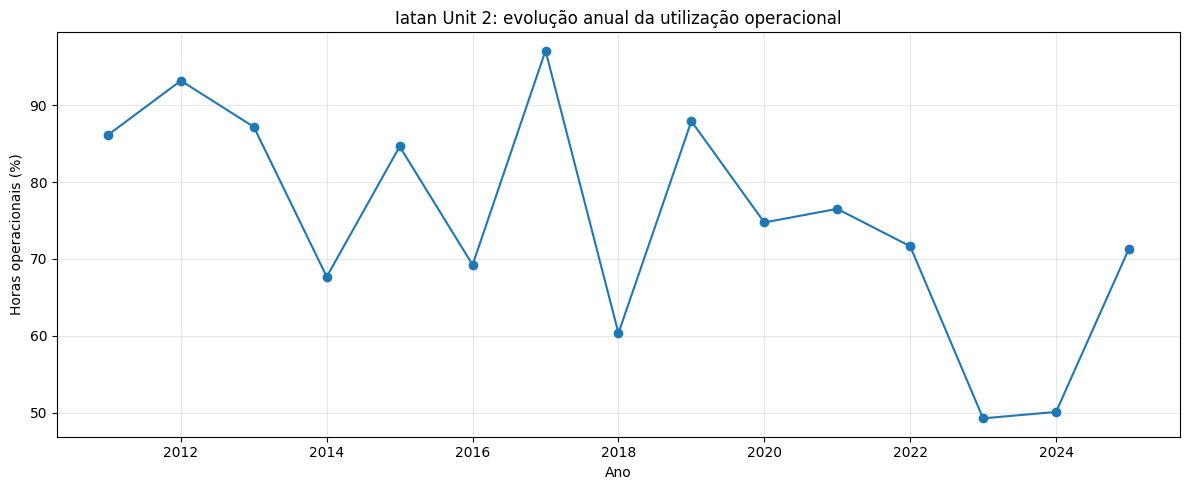

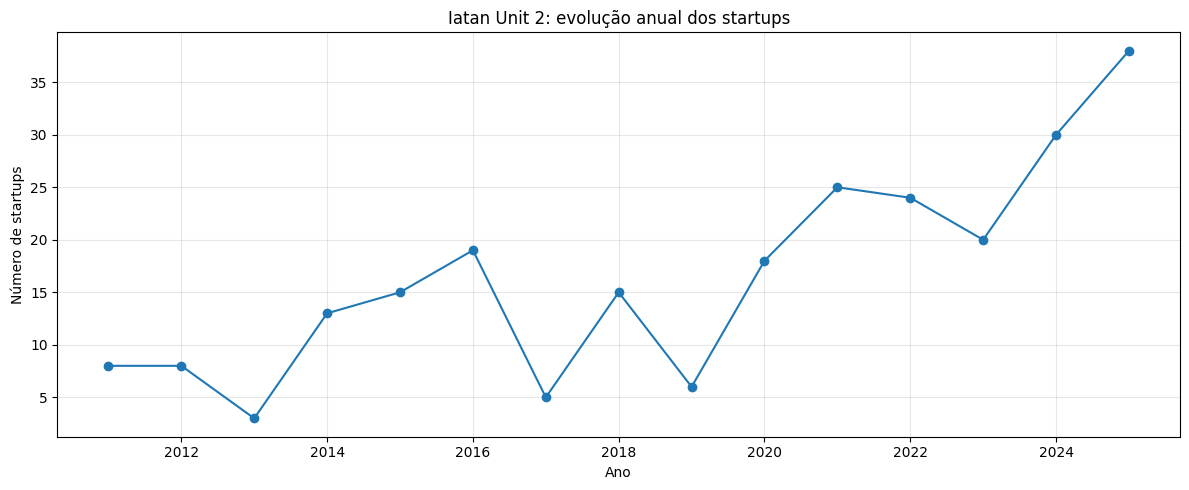

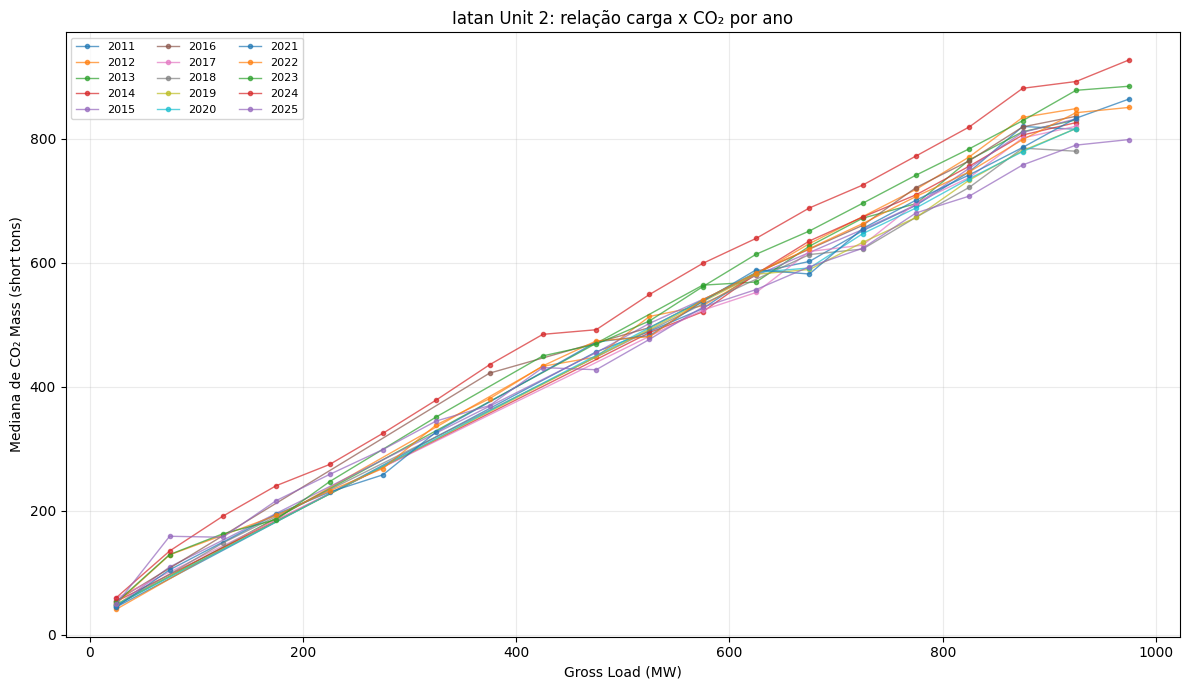

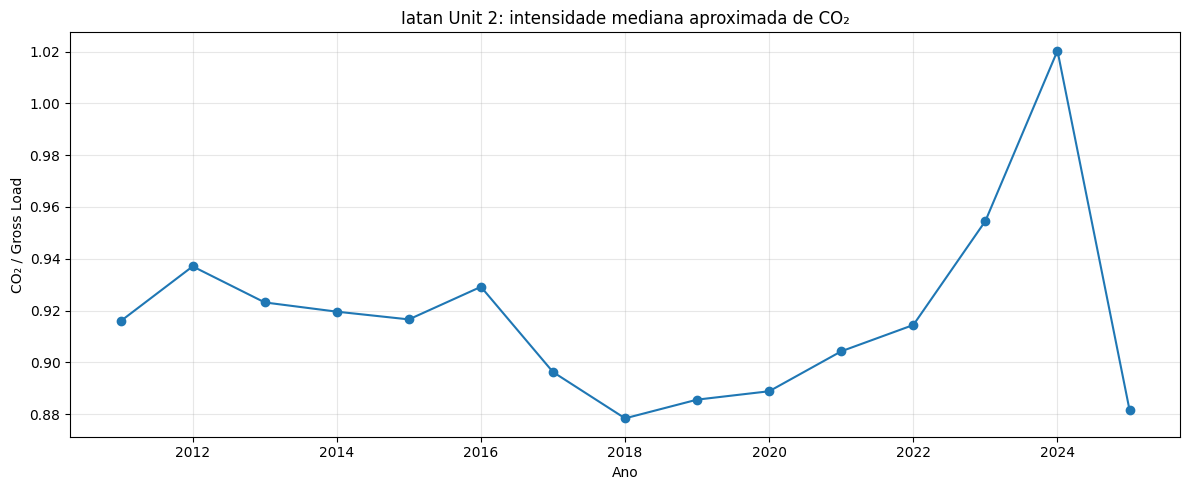

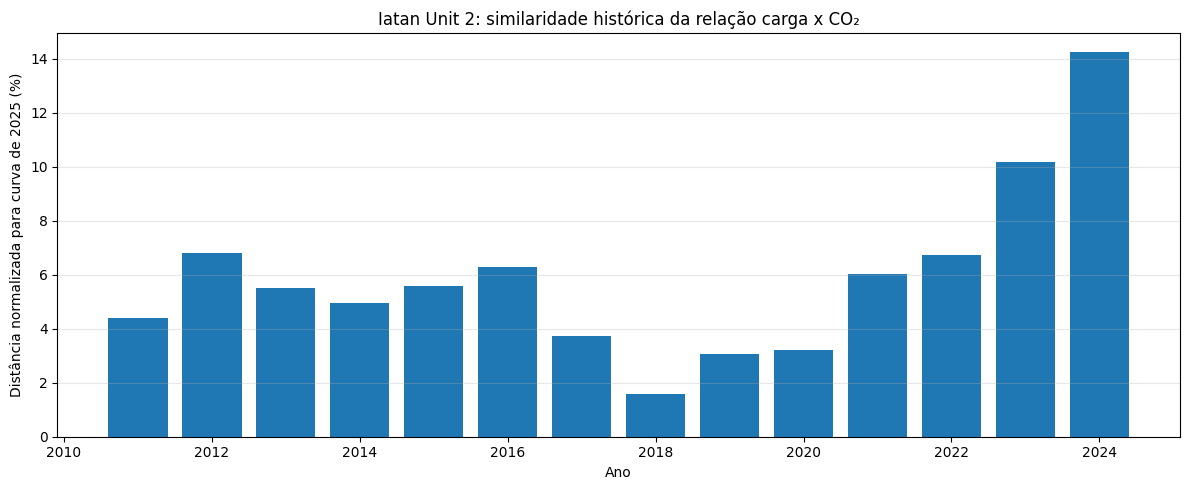


DIAGNÓSTICOS AUTOMÁTICOS

Anos com Gross Load = 0 durante Operating Time > 0:


,year,n_zero_load,zero_load_pct
0,2011,126,0.835
1,2012,166,1.014
2,2013,70,0.458
3,2014,250,2.108
4,2015,312,2.104
5,2016,288,2.368
7,2018,64,0.605
8,2019,100,0.649
9,2020,262,1.995
10,2021,428,3.193



Menor correlação carga x CO2:
2011 0.9636

Maior correlação carga x CO2:
2023 0.9971

Cinco anos com curva carga x CO2 mais semelhante a 2025:


,year,curve_nmae_vs_2025_pct,corr_load_co2_all,operating_pct,n_startups,load_mean
0,2018,1.5874,0.9915,60.3539,15,813.1846
1,2019,3.0561,0.9902,87.9224,6,825.9018
2,2020,3.1969,0.9956,74.7495,18,805.3632
3,2017,3.7433,0.9784,97.0890,5,833.4570
4,2011,4.3980,0.9636,86.1301,8,767.1997



Cinco anos com curva carga x CO2 menos semelhante a 2025:


,year,curve_nmae_vs_2025_pct,corr_load_co2_all,operating_pct,n_startups,load_mean
13,2024,14.2441,0.9918,50.1025,30,626.5476
12,2023,10.1579,0.9971,49.2694,20,691.3380
11,2012,6.8059,0.9810,93.1922,8,854.2261
10,2022,6.7463,0.9907,71.6553,24,706.6825
9,2016,6.2975,0.9954,69.2395,19,827.1603



INTERPRETAÇÃO METODOLÓGICA

Esta etapa separa duas dimensões diferentes:

1. PROCESS DRIFT

   Mudanças na frequência de operação, partidas, paradas e
   distribuição de carga.

2. DRIFT DA RELAÇÃO PREDITIVA

   Mudanças na relação empírica entre Gross Load e CO2.

A existência de process drift não implica necessariamente que
a relação carga x CO2 tenha mudado na mesma intensidade.

Os resultados desta célula serão utilizados para definir:

a) janelas crescentes de treinamento;
b) experimentos de recência;
c) comparação entre quantidade e similaridade dos dados;
d) estratégia de generalização temporal do Cenário A.

Nenhum ano completo será excluído apenas por apresentar
comportamento operacional diferente.


Arquivos gerados:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A04_drift_anual_cenario_A.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A04_carga_zero_baixa_operacao.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03

In [11]:
# ============================================================
# CÉLULA 6: DIAGNÓSTICO DE DRIFT DO CENÁRIO A
# ============================================================
#
# PONTO DE PARTIDA METODOLÓGICO
# ------------------------------------------------------------
# O experimento do Notebook 03A.04 permanece restrito ao
# CENÁRIO A:
#
#       CO2(t) = f(P(t))
#
# ou seja, a previsão utiliza apenas a carga instantânea
# Gross Load (MW), sem incorporar variáveis de trajetória
# operacional como lags, rampas, tempo desde startup ou outras
# features dos Cenários B e C.
#
# O objetivo principal deste notebook é isolar o efeito do
# HISTÓRICO DISPONÍVEL sobre a capacidade de generalização
# temporal do modelo.
#
# Por isso, nesta etapa:
#
#   - o algoritmo permanece fixo;
#   - o conjunto de features permanece fixo;
#   - o alvo permanece fixo;
#   - não haverá novo tuning;
#   - a quantidade, recência e similaridade temporal dos dados
#     serão as dimensões analisadas.
#
# Entretanto, a análise anterior mostrou que os anos da Iatan
# não apresentam exatamente o mesmo regime operacional.
#
# Em particular:
#
#   - 2017 apresentou operação quase contínua;
#   - 2023 e 2024 apresentaram aproximadamente metade das
#     horas do ano em operação;
#   - anos recentes apresentam maior frequência de startups;
#   - 2025 voltou a operar mais horas, mas apresentou número
#     elevado de partidas.
#
# Essas diferenças NÃO constituem motivo para excluir 2023 e
# 2024 da amostra.
#
# Ao contrário, esses anos podem representar um regime
# operacional mais recente e diferente do comportamento
# historicamente predominante de base load.
#
# Assim, serão investigadas duas dimensões distintas:
#
# 1. PROCESS DRIFT
#
#    Mudanças na forma como a unidade é utilizada, incluindo:
#
#       - proporção de horas operacionais;
#       - frequência de startups e shutdowns;
#       - distribuição da carga;
#       - maior ou menor comportamento cíclico.
#
#    Essas variáveis são utilizadas apenas como CONTEXTO
#    explicativo e NÃO como features do Cenário A.
#
# 2. DRIFT DA RELAÇÃO PREDITIVA
#
#    Mudanças na relação física e estatística:
#
#       Gross Load (MW) -> CO2 Mass (short tons)
#
#    Essa é a dimensão diretamente relevante para o
#    Cenário A.
#
# A existência de process drift não implica necessariamente
# alteração equivalente da relação carga x CO2.
#
# É possível, por exemplo, que a Iatan passe a operar menos
# horas e com mais partidas, mas mantenha relativamente estável
# a relação física entre potência gerada e emissão de CO2
# durante as horas de operação.
#
# CONCEITO ESTATÍSTICO RELACIONADO: POSSÍVEL CONCEPT DRIFT
# ------------------------------------------------------------
# Em aprendizado supervisionado, concept drift designa mudanças
# temporais na distribuição condicional P(Y | X). Neste estudo:
#
#     Y = CO2 Mass (short tons)
#     X = Gross Load (MW)
#
# Assim, diferenças temporais na relação carga x CO2 são
# compatíveis com a hipótese de concept drift. A comparação de
# curvas por ano e faixas de carga produz evidências DESCRITIVAS,
# mas não constitui teste formal de detecção de concept drift.
# Não se deve confundir essa possibilidade com process drift,
# que descreve mudanças no modo de operação da unidade.
# Mudanças nas frequências ou faixas de carga, por sua vez, não
# bastam para demonstrar mudança em P(CO2 | Gross Load).
# ============================================================
#
# DECISÕES ADOTADAS
# ------------------------------------------------------------
#
#   1. 2010 permanece fora da comparação principal,
#      pois representa um período parcial associado à entrada
#      em operação da Unit 2.
#
#   2. Todos os anos completos de 2011 a 2025 serão
#      considerados, inclusive 2023 e 2024.
#
#   3. O único registro operacional de 2019 sem Gross Load
#      será excluído automaticamente apenas das análises que
#      exigem simultaneamente carga e CO2.
#
#   4. Horas com Operating Time > 0 e Gross Load = 0 não serão
#      removidas automaticamente. Elas serão primeiro
#      identificadas e quantificadas, pois podem representar
#      estados de startup, shutdown, sincronização ou outras
#      condições transitórias relevantes.
#
#   5. O ano de 2025 será utilizado nesta célula como
#      REFERÊNCIA DE REGIME RECENTE para comparar curvas
#      históricas carga x CO2.
#
#      A distância em relação à curva de 2025 NÃO representa
#      erro preditivo e NÃO será utilizada como métrica de
#      desempenho de modelo.
#
#   6. Nenhum ano será excluído simplesmente por apresentar
#      comportamento operacional diferente.
#
# OBJETIVO DA CÉLULA
# ------------------------------------------------------------
# Investigar se a relação:
#
#       Gross Load (MW) -> CO2 Mass (short tons)
#
# permaneceu estável entre 2011 e 2025 e fornecer evidências
# para definir posteriormente:
#
#   - janelas crescentes de treinamento;
#   - experimentos de recência;
#   - comparação entre quantidade e similaridade dos dados;
#   - estratégia de generalização temporal do Cenário A.
#
# IMPORTANTE
# ------------------------------------------------------------
# Esta célula ainda NÃO treina XGBoost.
#
# Primeiro queremos compreender se os dados históricos são
# estatisticamente e operacionalmente transferíveis entre anos.
# ============================================================


# ============================================================
# 1. CONFIGURAÇÕES
# ============================================================

MAIN_START_YEAR = 2011

REFERENCE_YEAR_DRIFT = 2025

LOAD_BIN_WIDTH = 50

MIN_BIN_OBSERVATIONS = 20

MIN_LOAD_INTENSITY_MW = 50


# ============================================================
# 2. BASE PRINCIPAL
# ============================================================

history_main = (

    history[

        history[
            "year"
        ]
        >=
        MAIN_START_YEAR

    ]

    .copy()

)


print("=" * 72)

print(
    "DIAGNÓSTICO DE DRIFT DO CENÁRIO A"
)

print("=" * 72)


print(
    "\nPeríodo principal:",
    history_main["year"].min(),
    "→",
    history_main["year"].max()
)


print(
    "Registros:",
    f"{len(history_main):,}"
)


# ============================================================
# 3. BASE OPERACIONAL
# ============================================================

operating = (

    history_main[

        history_main[
            "Operating Time"
        ]
        >
        0

    ]

    .copy()

)


# ============================================================
# 4. BASE VÁLIDA DO CENÁRIO A
# ============================================================
#
# Isso remove automaticamente a única observação de 2019
# sem Gross Load.
#
# Gross Load = 0 permanece nesta etapa.
# ============================================================

scenario_A = (

    operating

    .dropna(

        subset=[

            "Gross Load (MW)",
            "CO2 Mass (short tons)"

        ]

    )

    .copy()

)


print(
    "\nHoras operacionais:",
    f"{len(operating):,}"
)


print(
    "Horas válidas para Cenário A:",
    f"{len(scenario_A):,}"
)


# ============================================================
# 5. AUDITORIA DE CARGA ZERO E BAIXA CARGA
# ============================================================

zero_low_rows = []


for year, df_year in operating.groupby(
    "year"
):

    year = int(year)

    n_operating = len(
        df_year
    )


    n_zero_load = int(

        (
            df_year[
                "Gross Load (MW)"
            ]
            ==
            0
        )
        .sum()

    )


    n_positive_load = int(

        (
            df_year[
                "Gross Load (MW)"
            ]
            >
            0
        )
        .sum()

    )


    n_low_load_50 = int(

        (
            (
                df_year[
                    "Gross Load (MW)"
                ]
                >
                0
            )

            &

            (
                df_year[
                    "Gross Load (MW)"
                ]
                <=
                50
            )
        )
        .sum()

    )


    n_missing_load = int(

        df_year[
            "Gross Load (MW)"
        ]

        .isna()

        .sum()

    )


    zero_load_pct = (

        100
        *
        n_zero_load
        /
        n_operating

        if n_operating > 0

        else np.nan

    )


    zero_low_rows.append({

        "year":
            year,

        "n_operating":
            n_operating,

        "n_zero_load":
            n_zero_load,

        "zero_load_pct":
            zero_load_pct,

        "n_low_load_1_50":
            n_low_load_50,

        "n_positive_load":
            n_positive_load,

        "n_missing_load":
            n_missing_load

    })


zero_low_summary = pd.DataFrame(
    zero_low_rows
)


print("\n" + "=" * 72)

print(
    "CARGA ZERO E BAIXA CARGA DURANTE OPERAÇÃO"
)

print("=" * 72)


display(

    zero_low_summary

    .round(
        3
    )

)


# ============================================================
# 6. RESUMO ANUAL DA RELAÇÃO CARGA X CO2
# ============================================================

drift_rows = []


for year, df_year in scenario_A.groupby(
    "year"
):

    year = int(
        year
    )


    # --------------------------------------------------------
    # Todos os dados válidos
    # --------------------------------------------------------

    x_all = (

        df_year[
            "Gross Load (MW)"
        ]

        .to_numpy(
            dtype=float
        )

    )


    y_all = (

        df_year[
            "CO2 Mass (short tons)"
        ]

        .to_numpy(
            dtype=float
        )

    )


    corr_all = (

        np.corrcoef(
            x_all,
            y_all
        )[0, 1]

        if len(x_all) > 1

        else np.nan

    )


    # --------------------------------------------------------
    # Apenas carga positiva
    # --------------------------------------------------------

    positive = (

        df_year[

            df_year[
                "Gross Load (MW)"
            ]
            >
            0

        ]

        .copy()

    )


    x_positive = (

        positive[
            "Gross Load (MW)"
        ]

        .to_numpy(
            dtype=float
        )

    )


    y_positive = (

        positive[
            "CO2 Mass (short tons)"
        ]

        .to_numpy(
            dtype=float
        )

    )


    if len(
        positive
    ) >= 2:


        corr_positive = np.corrcoef(

            x_positive,
            y_positive

        )[0, 1]


        slope, intercept = np.polyfit(

            x_positive,
            y_positive,
            1

        )


        y_linear_pred = (

            intercept
            +
            slope
            *
            x_positive

        )


        ss_res = np.sum(

            (
                y_positive
                -
                y_linear_pred
            )
            ** 2

        )


        ss_tot = np.sum(

            (
                y_positive
                -
                np.mean(
                    y_positive
                )
            )
            ** 2

        )


        linear_r2 = (

            1
            -
            ss_res
            /
            ss_tot

            if ss_tot > 0

            else np.nan

        )


    else:

        corr_positive = np.nan

        slope = np.nan

        intercept = np.nan

        linear_r2 = np.nan


    # --------------------------------------------------------
    # Intensidade aproximada de CO2
    # --------------------------------------------------------
    #
    # Usamos:
    #
    # Operating Time ~ 1 hora
    # Gross Load > 50 MW
    #
    # A razão funciona como indicador diagnóstico aproximado:
    #
    #     short tons CO2 / MWh
    #
    # Não será utilizada como alvo do modelo.
    # --------------------------------------------------------

    intensity_base = (

        df_year[

            (
                df_year[
                    "Operating Time"
                ]
                >=
                0.999
            )

            &

            (
                df_year[
                    "Gross Load (MW)"
                ]
                >
                MIN_LOAD_INTENSITY_MW
            )

        ]

        .copy()

    )


    intensity_base[
        "co2_per_mwh_proxy"
    ] = (

        intensity_base[
            "CO2 Mass (short tons)"
        ]

        /

        intensity_base[
            "Gross Load (MW)"
        ]

    )


    intensity_mean = (

        intensity_base[
            "co2_per_mwh_proxy"
        ]
        .mean()

        if len(intensity_base) > 0

        else np.nan

    )


    intensity_median = (

        intensity_base[
            "co2_per_mwh_proxy"
        ]
        .median()

        if len(intensity_base) > 0

        else np.nan

    )


    intensity_p05 = (

        intensity_base[
            "co2_per_mwh_proxy"
        ]
        .quantile(
            0.05
        )

        if len(intensity_base) > 0

        else np.nan

    )


    intensity_p95 = (

        intensity_base[
            "co2_per_mwh_proxy"
        ]
        .quantile(
            0.95
        )

        if len(intensity_base) > 0

        else np.nan

    )


    # --------------------------------------------------------
    # Informações operacionais utilizadas somente como contexto
    # --------------------------------------------------------

    annual_context = (

        annual_summary[

            annual_summary[
                "year"
            ]
            ==
            year

        ]

    )


    if len(
        annual_context
    ) == 1:


        operating_pct = float(

            annual_context[
                "operating_pct"
            ].iloc[0]

        )


        n_startups = int(

            annual_context[
                "n_startups"
            ].iloc[0]

        )


        n_shutdowns = int(

            annual_context[
                "n_shutdowns"
            ].iloc[0]

        )


    else:

        operating_pct = np.nan

        n_startups = np.nan

        n_shutdowns = np.nan


    drift_rows.append({

        "year":
            year,

        "n_scenario_A":
            len(df_year),

        "n_positive_load":
            len(positive),

        "operating_pct":
            operating_pct,

        "n_startups":
            n_startups,

        "n_shutdowns":
            n_shutdowns,

        "load_mean":
            df_year[
                "Gross Load (MW)"
            ].mean(),

        "load_median":
            df_year[
                "Gross Load (MW)"
            ].median(),

        "load_p05":
            df_year[
                "Gross Load (MW)"
            ].quantile(
                0.05
            ),

        "load_p95":
            df_year[
                "Gross Load (MW)"
            ].quantile(
                0.95
            ),

        "co2_mean":
            df_year[
                "CO2 Mass (short tons)"
            ].mean(),

        "co2_median":
            df_year[
                "CO2 Mass (short tons)"
            ].median(),

        "corr_load_co2_all":
            corr_all,

        "corr_load_co2_positive":
            corr_positive,

        "linear_slope":
            slope,

        "linear_intercept":
            intercept,

        "linear_r2":
            linear_r2,

        "intensity_n":
            len(
                intensity_base
            ),

        "intensity_mean":
            intensity_mean,

        "intensity_median":
            intensity_median,

        "intensity_p05":
            intensity_p05,

        "intensity_p95":
            intensity_p95

    })


drift_summary = pd.DataFrame(
    drift_rows
)


# ============================================================
# 7. CRIAR FAIXAS COMUNS DE CARGA
# ============================================================

max_load = float(

    scenario_A[
        "Gross Load (MW)"
    ]

    .max()

)


max_bin_edge = float(

    np.ceil(
        max_load
        /
        LOAD_BIN_WIDTH
    )

    *
    LOAD_BIN_WIDTH

)


load_bins = np.arange(

    0,

    max_bin_edge
    +
    LOAD_BIN_WIDTH,

    LOAD_BIN_WIDTH,

    dtype=float

)


scenario_A[
    "load_bin"
] = pd.cut(

    scenario_A[
        "Gross Load (MW)"
    ],

    bins=load_bins,

    include_lowest=True,

    right=False

)


# ============================================================
# 8. CURVA CARGA X CO2 POR FAIXA
# ============================================================

curve_by_year = (

    scenario_A

    .groupby(

        [
            "year",
            "load_bin"
        ],

        observed=True

    )

    .agg(

        n=(
            "CO2 Mass (short tons)",
            "size"
        ),

        load_mean=(
            "Gross Load (MW)",
            "mean"
        ),

        co2_mean=(
            "CO2 Mass (short tons)",
            "mean"
        ),

        co2_median=(
            "CO2 Mass (short tons)",
            "median"
        ),

        co2_std=(
            "CO2 Mass (short tons)",
            "std"
        )

    )

    .reset_index()

)


# ============================================================
# 9. CENTRO NUMÉRICO DAS FAIXAS DE CARGA
# ============================================================
#
# CORREÇÃO:
#
# pd.cut() cria uma variável Categorical contendo intervalos.
#
# Na versão anterior, o Pandas preservava o dtype Categorical
# depois da extração do limite esquerdo e impedia a soma com
# LOAD_BIN_WIDTH / 2.
#
# Aqui os limites são explicitamente convertidos para float.
# ============================================================

curve_by_year[
    "load_bin_left"
] = [

    float(
        interval.left
    )

    for interval in curve_by_year[
        "load_bin"
    ]

]


curve_by_year[
    "load_bin_right"
] = [

    float(
        interval.right
    )

    for interval in curve_by_year[
        "load_bin"
    ]

]


curve_by_year[
    "load_bin_center"
] = (

    curve_by_year[
        "load_bin_left"
    ]
    .astype(float)

    +

    curve_by_year[
        "load_bin_right"
    ]
    .astype(float)

) / 2


# ============================================================
# 10. COMPARAR CADA ANO COM 2025
# ============================================================
#
# Isso NÃO representa erro de previsão.
#
# É apenas uma medida de distância entre:
#
#       curva carga x CO2 do ano histórico
#
# e
#
#       curva carga x CO2 observada em 2025
#
# A distribuição de carga de 2025 determina os pesos.
# ============================================================

reference_curve = (

    curve_by_year[

        curve_by_year[
            "year"
        ]
        ==
        REFERENCE_YEAR_DRIFT

    ]

    .copy()

)


reference_curve = (

    reference_curve[

        reference_curve[
            "n"
        ]
        >=
        MIN_BIN_OBSERVATIONS

    ]

    .copy()

)


curve_distance_rows = []


for year in sorted(

    curve_by_year[
        "year"
    ].unique()

):

    year = int(
        year
    )


    year_curve = (

        curve_by_year[

            (
                curve_by_year[
                    "year"
                ]
                ==
                year
            )

            &

            (
                curve_by_year[
                    "n"
                ]
                >=
                MIN_BIN_OBSERVATIONS
            )

        ]

        .copy()

    )


    comparison = pd.merge(

        reference_curve[
            [
                "load_bin_left",
                "n",
                "co2_median"
            ]
        ],

        year_curve[
            [
                "load_bin_left",
                "n",
                "co2_median"
            ]
        ],

        on="load_bin_left",

        how="inner",

        suffixes=(

            "_2025",
            "_year"

        )

    )


    if comparison.empty:


        curve_distance_rows.append({

            "year":
                year,

            "n_common_bins":
                0,

            "reference_observations":
                0,

            "curve_mae_vs_2025":
                np.nan,

            "curve_nmae_vs_2025_pct":
                np.nan

        })


        continue


    weights = (

        comparison[
            "n_2025"
        ]

        .to_numpy(
            dtype=float
        )

    )


    weights = (

        weights

        /
        weights.sum()

    )


    absolute_difference = np.abs(

        comparison[
            "co2_median_year"
        ].to_numpy(
            dtype=float
        )

        -

        comparison[
            "co2_median_2025"
        ].to_numpy(
            dtype=float
        )

    )


    curve_mae = float(

        np.sum(

            weights

            *

            absolute_difference

        )

    )


    reference_weighted_mean = float(

        np.sum(

            weights

            *

            comparison[
                "co2_median_2025"
            ]
            .to_numpy(
                dtype=float
            )

        )

    )


    curve_nmae = (

        100
        *
        curve_mae
        /
        reference_weighted_mean

        if reference_weighted_mean != 0

        else np.nan

    )


    curve_distance_rows.append({

        "year":
            year,

        "n_common_bins":
            len(
                comparison
            ),

        "reference_observations":
            int(
                comparison[
                    "n_2025"
                ].sum()
            ),

        "curve_mae_vs_2025":
            curve_mae,

        "curve_nmae_vs_2025_pct":
            curve_nmae

    })


curve_distance = pd.DataFrame(

    curve_distance_rows

)


# ============================================================
# 11. JUNTAR DISTÂNCIA AO RESUMO DE DRIFT
# ============================================================

drift_summary = pd.merge(

    drift_summary,

    curve_distance,

    on="year",

    how="left"

)


# ============================================================
# 12. EXIBIR RESUMO
# ============================================================

display_columns = [

    "year",
    "n_scenario_A",
    "operating_pct",
    "n_startups",
    "load_mean",
    "load_p05",
    "load_p95",
    "co2_mean",
    "corr_load_co2_all",
    "corr_load_co2_positive",
    "linear_slope",
    "linear_r2",
    "intensity_median",
    "curve_nmae_vs_2025_pct"

]


print("\n" + "=" * 72)

print(
    "RESUMO DO DRIFT ANUAL"
)

print("=" * 72)


display(

    drift_summary[
        display_columns
    ]

    .round(
        4
    )

)


# ============================================================
# 13. RANKING DE SIMILARIDADE COM 2025
# ============================================================

similarity_ranking = (

    drift_summary[

        drift_summary[
            "year"
        ]
        !=
        REFERENCE_YEAR_DRIFT

    ]

    .sort_values(
        "curve_nmae_vs_2025_pct"
    )

    [
        [
            "year",
            "curve_nmae_vs_2025_pct",
            "corr_load_co2_all",
            "operating_pct",
            "n_startups",
            "load_mean"
        ]
    ]

    .reset_index(
        drop=True
    )

)


print("\n" + "=" * 72)

print(
    "ANOS MAIS SEMELHANTES A 2025"
)

print(
    "Considerando apenas a curva empírica carga x CO2"
)

print("=" * 72)


display(

    similarity_ranking

    .round(
        4
    )

)


# ============================================================
# 14. SALVAR TABELAS
# ============================================================

DRIFT_PATH = (

    TABLES
    /
    "03A04_drift_anual_cenario_A.csv"

)


ZERO_LOAD_PATH = (

    TABLES
    /
    "03A04_carga_zero_baixa_operacao.csv"

)


CURVES_PATH = (

    TABLES
    /
    "03A04_curvas_carga_co2_por_ano.csv"

)


SIMILARITY_PATH = (

    TABLES
    /
    "03A04_similaridade_curva_vs_2025.csv"

)


drift_summary.to_csv(

    DRIFT_PATH,

    index=False

)


zero_low_summary.to_csv(

    ZERO_LOAD_PATH,

    index=False

)


curve_by_year.to_csv(

    CURVES_PATH,

    index=False

)


similarity_ranking.to_csv(

    SIMILARITY_PATH,

    index=False

)


# ============================================================
# 15. FIGURA 1
# EVOLUÇÃO DA PROPORÇÃO DE HORAS OPERACIONAIS
# ============================================================

fig, ax = plt.subplots(

    figsize=(
        12,
        5
    )

)


ax.plot(

    drift_summary[
        "year"
    ],

    drift_summary[
        "operating_pct"
    ],

    marker="o"

)


ax.set_xlabel(
    "Ano"
)


ax.set_ylabel(
    "Horas operacionais (%)"
)


ax.set_title(

    "Iatan Unit 2: evolução anual da utilização operacional"

)


ax.grid(

    alpha=0.3

)


plt.tight_layout()


OPERATING_FIG_PATH = (

    FIGURES
    /
    "03A04_operating_pct_anual.png"

)


plt.savefig(

    OPERATING_FIG_PATH,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 16. FIGURA 2
# EVOLUÇÃO DOS STARTUPS
# ============================================================

fig, ax = plt.subplots(

    figsize=(
        12,
        5
    )

)


ax.plot(

    drift_summary[
        "year"
    ],

    drift_summary[
        "n_startups"
    ],

    marker="o"

)


ax.set_xlabel(
    "Ano"
)


ax.set_ylabel(
    "Número de startups"
)


ax.set_title(

    "Iatan Unit 2: evolução anual dos startups"

)


ax.grid(

    alpha=0.3

)


plt.tight_layout()


STARTUPS_FIG_PATH = (

    FIGURES
    /
    "03A04_startups_anual.png"

)


plt.savefig(

    STARTUPS_FIG_PATH,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 17. FIGURA 3
# CURVAS MEDIANAS CARGA X CO2 POR ANO
# ============================================================

fig, ax = plt.subplots(

    figsize=(
        12,
        7
    )

)


for year in sorted(

    curve_by_year[
        "year"
    ].unique()

):


    df_plot = (

        curve_by_year[

            (
                curve_by_year[
                    "year"
                ]
                ==
                year
            )

            &

            (
                curve_by_year[
                    "n"
                ]
                >=
                MIN_BIN_OBSERVATIONS
            )

        ]

        .sort_values(
            "load_bin_center"
        )

    )


    ax.plot(

        df_plot[
            "load_bin_center"
        ].astype(float),

        df_plot[
            "co2_median"
        ].astype(float),

        marker="o",

        markersize=3,

        linewidth=1,

        alpha=0.7,

        label=str(
            int(year)
        )

    )


ax.set_xlabel(
    "Gross Load (MW)"
)


ax.set_ylabel(
    "Mediana de CO₂ Mass (short tons)"
)


ax.set_title(

    "Iatan Unit 2: relação carga x CO₂ por ano"

)


ax.grid(

    alpha=0.25

)


ax.legend(

    ncol=3,

    fontsize=8

)


plt.tight_layout()


CURVE_FIG_PATH = (

    FIGURES
    /
    "03A04_curvas_carga_co2_anuais.png"

)


plt.savefig(

    CURVE_FIG_PATH,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 18. FIGURA 4
# INTENSIDADE APROXIMADA DE CO2
# ============================================================

fig, ax = plt.subplots(

    figsize=(
        12,
        5
    )

)


ax.plot(

    drift_summary[
        "year"
    ],

    drift_summary[
        "intensity_median"
    ],

    marker="o"

)


ax.set_xlabel(
    "Ano"
)


ax.set_ylabel(
    "CO₂ / Gross Load"
)


ax.set_title(

    "Iatan Unit 2: intensidade mediana aproximada de CO₂"

)


ax.grid(

    alpha=0.3

)


plt.tight_layout()


INTENSITY_FIG_PATH = (

    FIGURES
    /
    "03A04_intensidade_co2_anual.png"

)


plt.savefig(

    INTENSITY_FIG_PATH,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 19. FIGURA 5
# DISTÂNCIA DA CURVA ANUAL PARA 2025
# ============================================================

distance_plot = (

    drift_summary[

        drift_summary[
            "year"
        ]
        !=
        REFERENCE_YEAR_DRIFT

    ]

    .copy()

)


fig, ax = plt.subplots(

    figsize=(
        12,
        5
    )

)


ax.bar(

    distance_plot[
        "year"
    ],

    distance_plot[
        "curve_nmae_vs_2025_pct"
    ]

)


ax.set_xlabel(
    "Ano"
)


ax.set_ylabel(
    "Distância normalizada para curva de 2025 (%)"
)


ax.set_title(

    "Iatan Unit 2: similaridade histórica da relação carga x CO₂"

)


ax.grid(

    axis="y",

    alpha=0.3

)


plt.tight_layout()


DISTANCE_FIG_PATH = (

    FIGURES
    /
    "03A04_distancia_curva_vs_2025.png"

)


plt.savefig(

    DISTANCE_FIG_PATH,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 20. DIAGNÓSTICOS AUTOMÁTICOS
# ============================================================

print("\n" + "=" * 72)

print(
    "DIAGNÓSTICOS AUTOMÁTICOS"
)

print("=" * 72)


# ------------------------------------------------------------
# Carga zero
# ------------------------------------------------------------

years_zero_load = (

    zero_low_summary.loc[

        zero_low_summary[
            "n_zero_load"
        ]
        >
        0,

        [
            "year",
            "n_zero_load",
            "zero_load_pct"
        ]

    ]

)


print(
    "\nAnos com Gross Load = 0 durante Operating Time > 0:"
)


if years_zero_load.empty:

    print(
        "Nenhum."
    )

else:

    display(

        years_zero_load

        .round(
            3
        )

    )


# ------------------------------------------------------------
# Correlação mínima e máxima
# ------------------------------------------------------------

min_corr_row = (

    drift_summary.loc[

        drift_summary[
            "corr_load_co2_all"
        ]
        .idxmin()

    ]

)


max_corr_row = (

    drift_summary.loc[

        drift_summary[
            "corr_load_co2_all"
        ]
        .idxmax()

    ]

)


print(
    "\nMenor correlação carga x CO2:"
)


print(

    int(
        min_corr_row[
            "year"
        ]
    ),

    f"{min_corr_row['corr_load_co2_all']:.4f}"

)


print(
    "\nMaior correlação carga x CO2:"
)


print(

    int(
        max_corr_row[
            "year"
        ]
    ),

    f"{max_corr_row['corr_load_co2_all']:.4f}"

)


# ------------------------------------------------------------
# Anos mais semelhantes
# ------------------------------------------------------------

print(
    "\nCinco anos com curva carga x CO2 mais semelhante a 2025:"
)


display(

    similarity_ranking

    .head(
        5
    )

    .round(
        4
    )

)


# ------------------------------------------------------------
# Anos menos semelhantes
# ------------------------------------------------------------

print(
    "\nCinco anos com curva carga x CO2 menos semelhante a 2025:"
)


display(

    similarity_ranking

    .tail(
        5
    )

    .sort_values(
        "curve_nmae_vs_2025_pct",
        ascending=False
    )

    .round(
        4
    )

)


# ============================================================
# 21. RESUMO METODOLÓGICO
# ============================================================

print("\n" + "=" * 72)

print(
    "INTERPRETAÇÃO METODOLÓGICA"
)

print("=" * 72)


print(
    """
Esta etapa separa duas dimensões diferentes:

1. PROCESS DRIFT

   Mudanças na frequência de operação, partidas, paradas e
   distribuição de carga.

2. DRIFT DA RELAÇÃO PREDITIVA

   Mudanças na relação empírica entre Gross Load e CO2.

A existência de process drift não implica necessariamente que
a relação carga x CO2 tenha mudado na mesma intensidade.

Os resultados desta célula serão utilizados para definir:

a) janelas crescentes de treinamento;
b) experimentos de recência;
c) comparação entre quantidade e similaridade dos dados;
d) estratégia de generalização temporal do Cenário A.

Nenhum ano completo será excluído apenas por apresentar
comportamento operacional diferente.
"""
)


# ============================================================
# 22. CAMINHOS SALVOS
# ============================================================

print(
    "\nArquivos gerados:"
)


for path in [

    DRIFT_PATH,
    ZERO_LOAD_PATH,
    CURVES_PATH,
    SIMILARITY_PATH,
    OPERATING_FIG_PATH,
    STARTUPS_FIG_PATH,
    CURVE_FIG_PATH,
    INTENSITY_FIG_PATH,
    DISTANCE_FIG_PATH

]:

    print(
        path
    )

BACKTEST MULTIANUAL DO VOLUME HISTÓRICO

Registros disponíveis: 197,596
Período: 2011-01-01 00:00:00 → 2025-12-31 23:00:00

Anos-alvo: [2021, 2022, 2023, 2024, 2025]
Janelas históricas: [1, 2, 3, 5, 10]

ANO-ALVO: 2021
Janela  1 anos | n_train=10,948 | trees= 255 | MAE=30.702 | NMAE=4.46% | R²=0.9447
Janela  2 anos | n_train=26,350 | trees= 178 | MAE=41.478 | NMAE=6.03% | R²=0.8607
Janela  3 anos | n_train=36,924 | trees= 220 | MAE=22.794 | NMAE=3.31% | R²=0.9759
Janela  5 anos | n_train=66,098 | trees= 267 | MAE=32.729 | NMAE=4.76% | R²=0.9212
Janela 10 anos | n_train=139,520 | trees= 171 | MAE=18.564 | NMAE=2.70% | R²=0.9837

ANO-ALVO: 2022
Janela  1 anos | n_train=10,514 | trees= 142 | MAE=15.696 | NMAE=2.43% | R²=0.9775
Janela  2 anos | n_train=23,646 | trees= 146 | MAE=15.859 | NMAE=2.45% | R²=0.9779
Janela  3 anos | n_train=39,048 | trees= 162 | MAE=16.582 | NMAE=2.56% | R²=0.9763
Janela  5 anos | n_train=66,632 | trees= 158 | MAE=18.108 | NMAE=2.80% | R²=0.9727
Janela 10 anos | 

,target_year,history_years,n_train,n_validation,n_test,best_iteration,MAE,RMSE,R2,NMAE_pct,Bias
0,2021,1,10948,2184,13406,255,30.7016,44.4787,0.9447,4.4632,19.2692
1,2021,2,26350,2184,13406,178,41.4783,70.5814,0.8607,6.0298,29.6907
2,2021,3,36924,2184,13406,220,22.7945,29.3381,0.9759,3.3137,11.9999
3,2021,5,66098,2184,13406,267,32.7290,53.1118,0.9212,4.7579,17.0582
4,2021,10,139520,2184,13406,171,18.5637,24.1816,0.9837,2.6987,-1.5471
5,2022,1,10514,2892,12554,142,15.6960,28.2704,0.9775,2.4268,4.2928
6,2022,2,23646,2892,12554,146,15.8587,28.0480,0.9779,2.4520,5.1628
7,2022,3,39048,2892,12554,162,16.5825,28.9869,0.9763,2.5639,7.0169
8,2022,5,66632,2892,12554,158,18.1080,31.1153,0.9727,2.7998,8.3623
9,2022,10,137128,2892,12554,420,17.7627,31.4399,0.9722,2.7464,-0.5478



DESEMPENHO MÉDIO POR VOLUME HISTÓRICO


,history_years,n_targets,MAE_mean,MAE_std,RMSE_mean,R2_mean,NMAE_mean,NMAE_std,Bias_mean,best_iteration_mean,n_train_mean
0,1,5,40.7652,31.1830,51.5792,0.9160,6.5751,5.5747,-3.3859,171.0,9311.2
1,2,5,42.6019,23.6158,57.0622,0.9075,6.7884,4.2434,5.1640,152.0,21936.4
2,3,5,38.1453,20.7484,48.4887,0.9367,6.0945,3.7227,6.0162,177.4,34950.0
3,5,5,39.2190,17.2411,52.7158,0.9290,6.2267,3.1319,8.8737,188.4,62511.2
4,10,5,36.8628,19.0993,47.5071,0.9413,5.8801,3.3877,4.1444,217.2,132804.0



MELHOR VOLUME HISTÓRICO EM CADA ANO-ALVO


...

,history_years,n_wins
0,1,3
1,10,2



Matriz MAE:


history_years,1,2,3,5,10
target_year,,,,,
2021,30.702,41.478,22.794,32.729,18.564
2022,15.696,15.859,16.582,18.108,17.763
2023,28.084,33.288,36.983,33.959,38.981
2024,34.210,42.003,45.035,47.475,46.361
2025,95.134,80.381,69.331,63.824,62.646



Matriz NMAE (%):


history_years,1,2,3,5,10
target_year,,,,,
2021,4.463,6.030,3.314,4.758,2.699
2022,2.427,2.452,2.564,2.800,2.746
2023,4.238,5.023,5.580,5.124,5.882
2024,5.387,6.614,7.091,7.475,7.300
2025,16.361,13.824,11.923,10.976,10.774


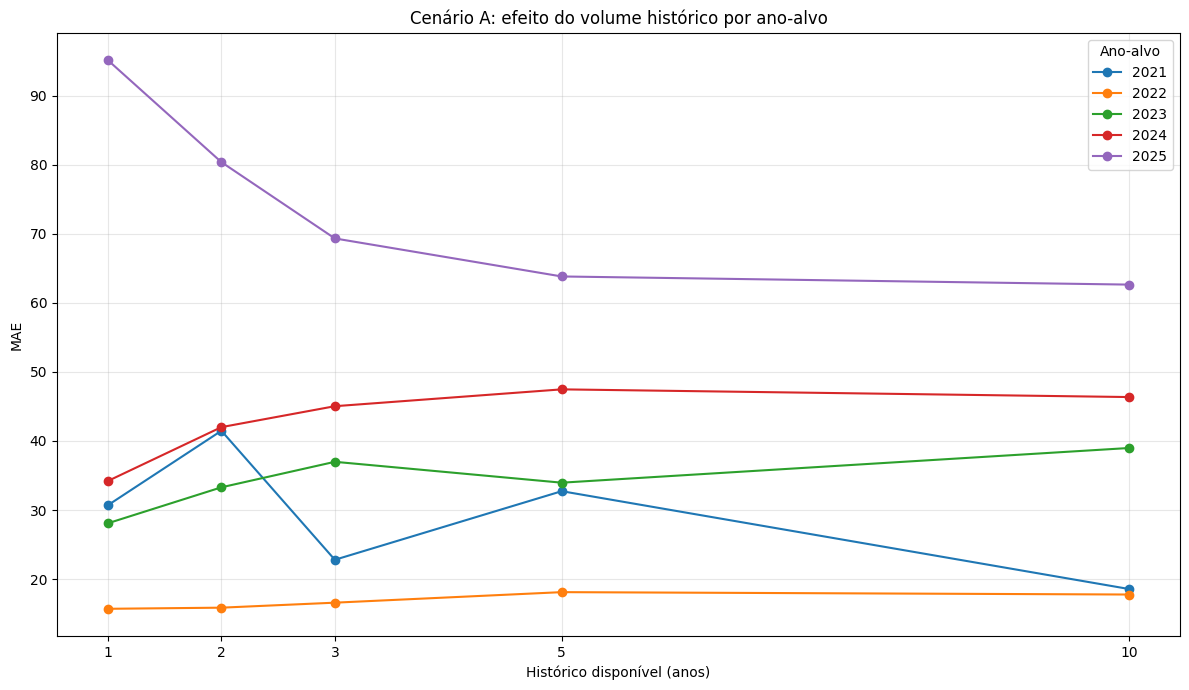

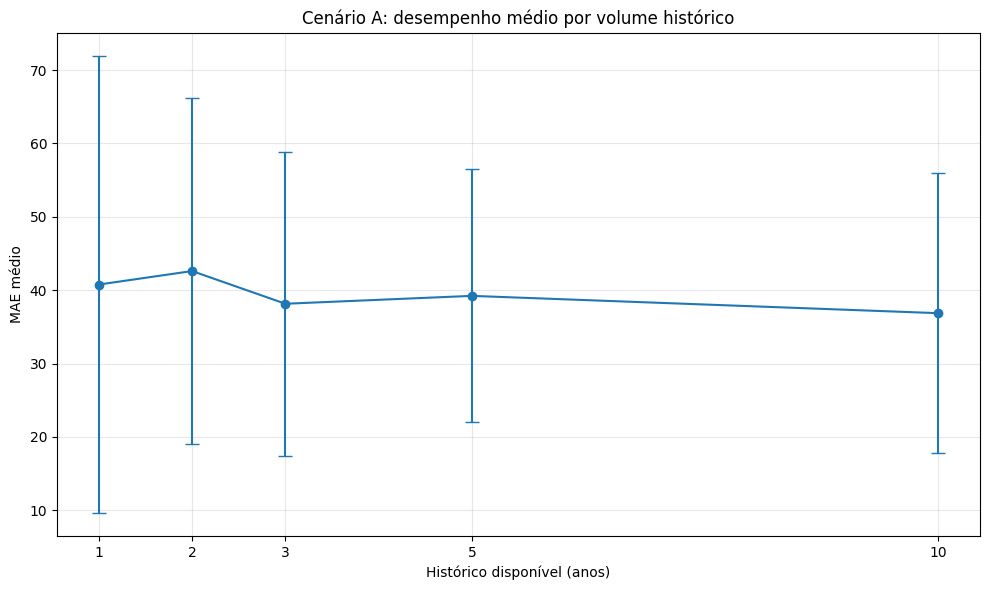

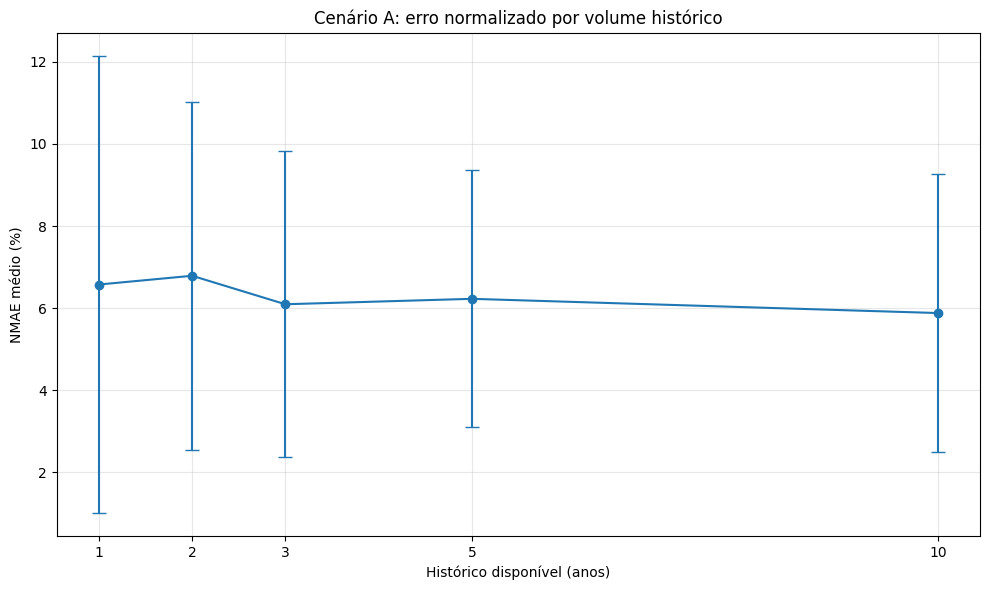


DIAGNÓSTICO DO VOLUME HISTÓRICO

Melhor janela em MAE médio:
10 anos | MAE médio = 36.863

Pior janela em MAE médio:
2 anos | MAE médio = 42.602

MAE médio diminui monotonamente com mais histórico: False

INTERPRETAÇÃO METODOLÓGICA

Este experimento responde exclusivamente ao efeito do VOLUME
DE HISTÓRICO no Cenário A.

Cada volume histórico foi avaliado nos mesmos cinco anos-alvo:

    2021
    2022
    2023
    2024
    2025

Portanto, diferenças entre as médias das janelas não são
decorrentes da utilização de anos de teste diferentes.

Uma redução consistente de MAE com janelas maiores sustentaria
a hipótese de que mais histórico melhora a generalização.

Caso o desempenho estabilize ou piore com janelas maiores,
isso indicará que dados antigos possuem utilidade limitada ou
que existe drift suficiente para reduzir sua transferibilidade.

Esta célula NÃO testa ainda se dados recentes são melhores que
dados antigos com o mesmo tamanho de amostra.

Essa será uma análise separada de RE

In [12]:
# ============================================================
# CÉLULA 7: BACKTEST MULTIANUAL DO VOLUME DE HISTÓRICO
# CENÁRIO A
# ============================================================
#
# PERGUNTA EXPERIMENTAL
# ------------------------------------------------------------
#
# A ampliação do histórico de treinamento melhora de forma
# consistente a capacidade de prever emissões futuras de CO2
# da Iatan Unit 2?
#
#
# CENÁRIO MANTIDO FIXO
# ------------------------------------------------------------
#
#       CO2(t) = f(P(t))
#
# Feature:
#
#       Gross Load (MW)
#
# Modelo:
#
#       XGBoost
#
# com a mesma configuração de referência utilizada no
# Notebook 03A.02.
#
#
# PRINCÍPIO DO EXPERIMENTO
# ------------------------------------------------------------
#
# Para isolar o efeito do VOLUME HISTÓRICO:
#
#   - algoritmo permanece fixo;
#   - hiperparâmetros permanecem fixos;
#   - feature permanece fixa;
#   - alvo permanece fixo;
#   - ano de teste permanece igual entre as janelas
#     comparadas;
#   - somente o início da janela de treinamento muda.
#
#
# IMPORTANTE
# ------------------------------------------------------------
#
# O ano de 2025 já foi examinado em experimentos anteriores e
# NÃO representa mais um teste completamente cego.
#
# Por isso, a conclusão sobre volume histórico NÃO será baseada
# somente em 2025.
#
# Serão utilizados múltiplos anos-alvo:
#
#       2021
#       2022
#       2023
#       2024
#       2025
#
# Isso permite verificar se o efeito de adicionar histórico é
# consistente em diferentes regimes temporais.
#
#
# JANELAS TESTADAS
# ------------------------------------------------------------
#
#       1 ano
#       2 anos
#       3 anos
#       5 anos
#       10 anos
#
#
# DESENHO DE AVALIAÇÃO: ROLLING-ORIGIN TEMPORAL BACKTESTING
# ------------------------------------------------------------
# Rolling-origin evaluation (backtesting com origem temporal
# móvel) avalia previsões em sucessivos períodos futuros.
# A origem avança de um ano-alvo para o seguinte, de 2021 a
# 2025, preservando a ordem cronológica treino -> validação
# -> teste. Em cada origem são comparadas cinco extensões
# alternativas do histórico: 1, 2, 3, 5 e 10 anos.
#
# Essa estratégia pode ser descrita como:
# rolling-origin temporal backtesting with multiple
# training-window lengths.
#
# Atenção à distinção terminológica: as janelas avaliadas
# têm durações históricas predefinidas. Não se pressupõe uma
# única expanding window que acumula automaticamente todos
# os dados desde o primeiro ano disponível.
#
# Dentro de cada combinação de ano-alvo e duração histórica,
# o trimestre final de Y-1 é reservado à seleção do número
# de árvores por early stopping; o ano Y permanece para teste.
# A rotina de backtest usa o melhor estágio da própria rodada,
# sem o procedimento separado de final refit empregado adiante.
# ============================================================
#
# VALIDAÇÃO INTERNA
# ------------------------------------------------------------
#
# Para cada ano-alvo Y:
#
#       validação = outubro a dezembro de Y-1
#
# Essa validação é usada SOMENTE para early stopping.
#
# O período de teste continua sendo todo o ano Y.
#
#
# EXEMPLO PARA TESTE = 2025
# ------------------------------------------------------------
#
# Janela 1:
#
#       treino: 2024-01-01 a 2024-09-30
#       validação: 2024-10-01 a 2024-12-31
#       teste: 2025
#
# Janela 5:
#
#       treino: 2020-01-01 a 2024-09-30
#       validação: 2024-10-01 a 2024-12-31
#       teste: 2025
#
# Dessa forma, o período de validação e o período de teste
# permanecem exatamente iguais entre as janelas.
# ============================================================


# ============================================================
# 1. CONFIGURAÇÃO EXPERIMENTAL
# ============================================================

TARGET_YEARS = [

    2021,
    2022,
    2023,
    2024,
    2025

]


HISTORY_WINDOWS = [

    1,
    2,
    3,
    5,
    10

]


FEATURE_A = [

    "Gross Load (MW)"

]


TARGET_A = (

    "CO2 Mass (short tons)"

)


VALIDATION_START_MONTH = 10


# ============================================================
# 2. BASE EXPERIMENTAL
# ============================================================
#
# Mantemos:
#
#   Operating Time > 0
#   carga disponível
#   CO2 disponível
#
# Carga igual a zero permanece.
#
# Isso mantém coerência com a decisão da Célula 6.
# ============================================================

experiment_A = (

    history[

        (
            history[
                "year"
            ]
            >=
            2011
        )

        &

        (
            history[
                "Operating Time"
            ]
            >
            0
        )

    ]

    .dropna(

        subset=[

            "Gross Load (MW)",
            TARGET_A

        ]

    )

    .copy()

)


experiment_A = (

    experiment_A

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


print("=" * 72)

print(
    "BACKTEST MULTIANUAL DO VOLUME HISTÓRICO"
)

print("=" * 72)


print(
    "\nRegistros disponíveis:",
    f"{len(experiment_A):,}"
)


print(
    "Período:",
    experiment_A[
        "timestamp"
    ].min(),
    "→",
    experiment_A[
        "timestamp"
    ].max()
)


print(
    "\nAnos-alvo:",
    TARGET_YEARS
)


print(
    "Janelas históricas:",
    HISTORY_WINDOWS
)


# ============================================================
# 3. FUNÇÃO DE MÉTRICAS
# ============================================================

def metrics_03A04(
    y_true,
    y_pred
):


    y_true = np.asarray(
        y_true,
        dtype=float
    )


    y_pred = np.asarray(
        y_pred,
        dtype=float
    )


    mae = mean_absolute_error(

        y_true,
        y_pred

    )


    rmse = np.sqrt(

        mean_squared_error(

            y_true,
            y_pred

        )

    )


    r2 = r2_score(

        y_true,
        y_pred

    )


    mean_y = np.mean(
        y_true
    )


    nmae = (

        100
        *
        mae
        /
        mean_y

        if mean_y != 0

        else np.nan

    )


    bias = np.mean(

        y_true
        -
        y_pred

    )


    return {

        "MAE":
            mae,

        "RMSE":
            rmse,

        "R2":
            r2,

        "NMAE_pct":
            nmae,

        "Bias":
            bias

    }


# ============================================================
# 4. FUNÇÃO PARA CRIAR MODELO
# ============================================================
#
# Utilizamos exatamente a configuração de referência do
# Notebook 03A.02.
# ============================================================

def build_xgb_03A04():


    return XGBRegressor(

        objective=
            "reg:squarederror",

        n_estimators=
            3000,

        learning_rate=
            0.03,

        max_depth=
            4,

        min_child_weight=
            5,

        subsample=
            0.80,

        colsample_bytree=
            0.80,

        reg_alpha=
            0.0,

        reg_lambda=
            1.0,

        eval_metric=
            "rmse",

        early_stopping_rounds=
            50,

        random_state=
            SEED,

        n_jobs=
            -1

    )


# ============================================================
# 5. ESTRUTURAS DE RESULTADOS
# ============================================================

backtest_rows = []

prediction_frames = []


# ============================================================
# 6. LOOP DOS ANOS-ALVO
# ============================================================

for target_year in TARGET_YEARS:


    print("\n" + "=" * 72)

    print(
        f"ANO-ALVO: {target_year}"
    )

    print("=" * 72)


    # ========================================================
    # 6.1. TESTE
    # ========================================================

    test_start = pd.Timestamp(

        year=
            target_year,

        month=
            1,

        day=
            1

    )


    test_end = pd.Timestamp(

        year=
            target_year,

        month=
            12,

        day=
            31,

        hour=
            23

    )


    test_data = (

        experiment_A[

            (
                experiment_A[
                    "timestamp"
                ]
                >=
                test_start
            )

            &

            (
                experiment_A[
                    "timestamp"
                ]
                <=
                test_end
            )

        ]

        .copy()

    )


    if test_data.empty:

        raise ValueError(

            f"Sem dados de teste para {target_year}."

        )


    # ========================================================
    # 6.2. VALIDAÇÃO FIXA
    # ========================================================
    #
    # Outubro a dezembro do ano imediatamente anterior.
    # ========================================================

    validation_year = (

        target_year
        -
        1

    )


    validation_start = pd.Timestamp(

        year=
            validation_year,

        month=
            VALIDATION_START_MONTH,

        day=
            1

    )


    validation_end = pd.Timestamp(

        year=
            validation_year,

        month=
            12,

        day=
            31,

        hour=
            23

    )


    validation_data = (

        experiment_A[

            (
                experiment_A[
                    "timestamp"
                ]
                >=
                validation_start
            )

            &

            (
                experiment_A[
                    "timestamp"
                ]
                <=
                validation_end
            )

        ]

        .copy()

    )


    if validation_data.empty:

        raise ValueError(

            f"Sem validação para {target_year}."

        )


    # ========================================================
    # 6.3. LOOP DAS JANELAS HISTÓRICAS
    # ========================================================

    for history_years in HISTORY_WINDOWS:


        # ----------------------------------------------------
        # Ano inicial da janela
        # ----------------------------------------------------

        first_train_year = (

            target_year
            -
            history_years

        )


        train_start = pd.Timestamp(

            year=
                first_train_year,

            month=
                1,

            day=
                1

        )


        # ----------------------------------------------------
        # Treino termina imediatamente antes da validação
        # ----------------------------------------------------

        train_end = (

            validation_start
            -
            pd.Timedelta(
                hours=1
            )

        )


        # ----------------------------------------------------
        # Selecionar treino
        # ----------------------------------------------------

        train_data = (

            experiment_A[

                (
                    experiment_A[
                        "timestamp"
                    ]
                    >=
                    train_start
                )

                &

                (
                    experiment_A[
                        "timestamp"
                    ]
                    <=
                    train_end
                )

            ]

            .copy()

        )


        # ----------------------------------------------------
        # Sanity checks temporais
        # ----------------------------------------------------

        if train_data.empty:

            raise ValueError(

                f"Treino vazio: "
                f"target={target_year}, "
                f"janela={history_years}"

            )


        if not (

            train_data[
                "timestamp"
            ].max()

            <

            validation_data[
                "timestamp"
            ].min()

            <

            test_data[
                "timestamp"
            ].min()

        ):

            raise ValueError(

                "Falha na ordem temporal."

            )


        # ----------------------------------------------------
        # Matrizes
        # ----------------------------------------------------

        X_train = (

            train_data[
                FEATURE_A
            ]

        )


        y_train = (

            train_data[
                TARGET_A
            ]

        )


        X_val = (

            validation_data[
                FEATURE_A
            ]

        )


        y_val = (

            validation_data[
                TARGET_A
            ]

        )


        X_test = (

            test_data[
                FEATURE_A
            ]

        )


        y_test = (

            test_data[
                TARGET_A
            ]

        )


        # ----------------------------------------------------
        # Modelo
        # ----------------------------------------------------

        model = build_xgb_03A04()


        model.fit(

            X_train,

            y_train,

            eval_set=[

                (
                    X_val,
                    y_val
                )

            ],

            verbose=False

        )


        # ----------------------------------------------------
        # Previsão
        # ----------------------------------------------------

        y_pred = model.predict(

            X_test

        )


        # ----------------------------------------------------
        # Métricas
        # ----------------------------------------------------

        metrics = metrics_03A04(

            y_test,
            y_pred

        )


        # ----------------------------------------------------
        # Melhor iteração
        # ----------------------------------------------------

        best_iteration = (

            int(
                model.best_iteration
            )
            +
            1

        )


        # ----------------------------------------------------
        # Resumo do treinamento
        # ----------------------------------------------------

        train_years_observed = sorted(

            train_data[
                "year"
            ]
            .unique()
            .astype(int)
            .tolist()

        )


        # ----------------------------------------------------
        # Registrar resultados
        # ----------------------------------------------------

        backtest_rows.append({

            "target_year":
                target_year,

            "history_years":
                history_years,

            "train_start":
                train_data[
                    "timestamp"
                ].min(),

            "train_end":
                train_data[
                    "timestamp"
                ].max(),

            "validation_start":
                validation_data[
                    "timestamp"
                ].min(),

            "validation_end":
                validation_data[
                    "timestamp"
                ].max(),

            "test_start":
                test_data[
                    "timestamp"
                ].min(),

            "test_end":
                test_data[
                    "timestamp"
                ].max(),

            "n_train":
                len(
                    train_data
                ),

            "n_validation":
                len(
                    validation_data
                ),

            "n_test":
                len(
                    test_data
                ),

            "n_train_calendar_years":
                len(
                    train_years_observed
                ),

            "first_train_year":
                min(
                    train_years_observed
                ),

            "last_train_year":
                max(
                    train_years_observed
                ),

            "best_iteration":
                best_iteration,

            **metrics

        })


        # ----------------------------------------------------
        # Guardar previsões
        # ----------------------------------------------------

        pred_df = pd.DataFrame({

            "timestamp":
                test_data[
                    "timestamp"
                ].to_numpy(),

            "target_year":
                target_year,

            "history_years":
                history_years,

            "Gross Load (MW)":
                test_data[
                    "Gross Load (MW)"
                ].to_numpy(),

            "CO2_observed":
                y_test.to_numpy(),

            "CO2_predicted":
                y_pred

        })


        pred_df[
            "residual"
        ] = (

            pred_df[
                "CO2_observed"
            ]

            -

            pred_df[
                "CO2_predicted"
            ]

        )


        prediction_frames.append(

            pred_df

        )


        # ----------------------------------------------------
        # Mostrar progresso
        # ----------------------------------------------------

        print(

            f"Janela {history_years:>2} anos | "
            f"n_train={len(train_data):>6,} | "
            f"trees={best_iteration:>4} | "
            f"MAE={metrics['MAE']:.3f} | "
            f"NMAE={metrics['NMAE_pct']:.2f}% | "
            f"R²={metrics['R2']:.4f}"

        )


# ============================================================
# 7. CONSOLIDAR RESULTADOS
# ============================================================

backtest_results = pd.DataFrame(

    backtest_rows

)


backtest_results = (

    backtest_results

    .sort_values(

        [
            "target_year",
            "history_years"
        ]

    )

    .reset_index(
        drop=True
    )

)


predictions_backtest = pd.concat(

    prediction_frames,

    ignore_index=True

)


# ============================================================
# 8. EXIBIR RESULTADOS COMPLETOS
# ============================================================

print("\n" + "=" * 72)

print(
    "RESULTADOS DO BACKTEST"
)

print("=" * 72)


display(

    backtest_results[

        [
            "target_year",
            "history_years",
            "n_train",
            "n_validation",
            "n_test",
            "best_iteration",
            "MAE",
            "RMSE",
            "R2",
            "NMAE_pct",
            "Bias"
        ]

    ]

    .round(
        4
    )

)


# ============================================================
# 9. RESUMO POR VOLUME DE HISTÓRICO
# ============================================================
#
# Como todos os volumes foram testados nos MESMOS cinco
# anos-alvo, as médias podem ser comparadas diretamente.
# ============================================================

window_summary = (

    backtest_results

    .groupby(
        "history_years"
    )

    .agg(

        n_targets=(
            "target_year",
            "nunique"
        ),

        MAE_mean=(
            "MAE",
            "mean"
        ),

        MAE_std=(
            "MAE",
            "std"
        ),

        RMSE_mean=(
            "RMSE",
            "mean"
        ),

        R2_mean=(
            "R2",
            "mean"
        ),

        NMAE_mean=(
            "NMAE_pct",
            "mean"
        ),

        NMAE_std=(
            "NMAE_pct",
            "std"
        ),

        Bias_mean=(
            "Bias",
            "mean"
        ),

        best_iteration_mean=(
            "best_iteration",
            "mean"
        ),

        n_train_mean=(
            "n_train",
            "mean"
        )

    )

    .reset_index()

)


print("\n" + "=" * 72)

print(
    "DESEMPENHO MÉDIO POR VOLUME HISTÓRICO"
)

print("=" * 72)


display(

    window_summary

    .round(
        4
    )

)


# ============================================================
# 10. MELHOR JANELA EM CADA ANO-ALVO
# ============================================================

best_by_target = (

    backtest_results.loc[

        backtest_results

        .groupby(
            "target_year"
        )

        [
            "MAE"
        ]

        .idxmin()

    ]

    [
        [
            "target_year",
            "history_years",
            "MAE",
            "RMSE",
            "R2",
            "NMAE_pct",
            "Bias",
            "n_train"
        ]
    ]

    .sort_values(
        "target_year"
    )

    .reset_index(
        drop=True
    )

)


print("\n" + "=" * 72)

print(
    "MELHOR VOLUME HISTÓRICO EM CADA ANO-ALVO"
)

print("=" * 72)


display(

    best_by_target

    .round(
        4
    )

)


# ============================================================
# 11. GANHO EM RELAÇÃO À JANELA DE 1 ANO
# ============================================================

baseline_1y = (

    backtest_results[

        backtest_results[
            "history_years"
        ]
        ==
        1

    ]

    [
        [
            "target_year",
            "MAE"
        ]
    ]

    .rename(

        columns={

            "MAE":
                "MAE_1y"

        }

    )

)


volume_gain = pd.merge(

    backtest_results,

    baseline_1y,

    on="target_year",

    how="left"

)


volume_gain[
    "gain_vs_1y_pct"
] = (

    100

    *

    (

        volume_gain[
            "MAE_1y"
        ]

        -

        volume_gain[
            "MAE"
        ]

    )

    /

    volume_gain[
        "MAE_1y"
    ]

)


print("\n" + "=" * 72)

print(
    "GANHO DE MAE EM RELAÇÃO A 1 ANO DE HISTÓRICO"
)

print("=" * 72)


gain_pivot = (

    volume_gain

    .pivot(

        index=
            "target_year",

        columns=
            "history_years",

        values=
            "gain_vs_1y_pct"

    )

)


display(

    gain_pivot

    .round(
        3
    )

)


# ============================================================
# 12. CONTAGEM DE VITÓRIAS POR JANELA
# ============================================================

window_wins = (

    best_by_target[
        "history_years"
    ]

    .value_counts()

    .sort_index()

    .rename_axis(
        "history_years"
    )

    .reset_index(
        name="n_wins"
    )

)


print("\n" + "=" * 72)

print(
    "QUANTAS VEZES CADA JANELA FOI A MELHOR"
)

print("=" * 72)


display(
    window_wins
)


# ============================================================
# 13. MATRIZ DE MAE
# ============================================================

mae_matrix = (

    backtest_results

    .pivot(

        index=
            "target_year",

        columns=
            "history_years",

        values=
            "MAE"

    )

)


print("\nMatriz MAE:")


display(

    mae_matrix

    .round(
        3
    )

)


# ============================================================
# 14. MATRIZ DE NMAE
# ============================================================

nmae_matrix = (

    backtest_results

    .pivot(

        index=
            "target_year",

        columns=
            "history_years",

        values=
            "NMAE_pct"

    )

)


print("\nMatriz NMAE (%):")


display(

    nmae_matrix

    .round(
        3
    )

)


# ============================================================
# 15. FIGURA
# MAE POR VOLUME HISTÓRICO EM CADA ANO-ALVO
# ============================================================

fig, ax = plt.subplots(

    figsize=(
        12,
        7
    )

)


for target_year in TARGET_YEARS:


    df_plot = (

        backtest_results[

            backtest_results[
                "target_year"
            ]
            ==
            target_year

        ]

        .sort_values(
            "history_years"
        )

    )


    ax.plot(

        df_plot[
            "history_years"
        ],

        df_plot[
            "MAE"
        ],

        marker="o",

        label=str(
            target_year
        )

    )


ax.set_xlabel(
    "Histórico disponível (anos)"
)


ax.set_ylabel(
    "MAE"
)


ax.set_title(

    "Cenário A: efeito do volume histórico por ano-alvo"

)


ax.set_xticks(
    HISTORY_WINDOWS
)


ax.grid(
    alpha=0.3
)


ax.legend(
    title="Ano-alvo"
)


plt.tight_layout()


FIG_VOLUME_TARGETS = (

    FIGURES
    /
    "03A04_mae_volume_por_ano_alvo.png"

)


plt.savefig(

    FIG_VOLUME_TARGETS,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 16. FIGURA
# MÉDIA E DISPERSÃO DO MAE POR VOLUME
# ============================================================

fig, ax = plt.subplots(

    figsize=(
        10,
        6
    )

)


ax.errorbar(

    window_summary[
        "history_years"
    ],

    window_summary[
        "MAE_mean"
    ],

    yerr=
        window_summary[
            "MAE_std"
        ],

    marker="o",

    capsize=5

)


ax.set_xlabel(
    "Histórico disponível (anos)"
)


ax.set_ylabel(
    "MAE médio"
)


ax.set_title(

    "Cenário A: desempenho médio por volume histórico"

)


ax.set_xticks(
    HISTORY_WINDOWS
)


ax.grid(
    alpha=0.3
)


plt.tight_layout()


FIG_VOLUME_MEAN = (

    FIGURES
    /
    "03A04_mae_medio_volume_historico.png"

)


plt.savefig(

    FIG_VOLUME_MEAN,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 17. FIGURA
# NMAE POR VOLUME HISTÓRICO
# ============================================================

fig, ax = plt.subplots(

    figsize=(
        10,
        6
    )

)


ax.errorbar(

    window_summary[
        "history_years"
    ],

    window_summary[
        "NMAE_mean"
    ],

    yerr=
        window_summary[
            "NMAE_std"
        ],

    marker="o",

    capsize=5

)


ax.set_xlabel(
    "Histórico disponível (anos)"
)


ax.set_ylabel(
    "NMAE médio (%)"
)


ax.set_title(

    "Cenário A: erro normalizado por volume histórico"

)


ax.set_xticks(
    HISTORY_WINDOWS
)


ax.grid(
    alpha=0.3
)


plt.tight_layout()


FIG_NMAE_MEAN = (

    FIGURES
    /
    "03A04_nmae_medio_volume_historico.png"

)


plt.savefig(

    FIG_NMAE_MEAN,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 18. SALVAR RESULTADOS
# ============================================================

BACKTEST_PATH = (

    TABLES
    /
    "03A04_backtest_volume_historico_A.csv"

)


WINDOW_SUMMARY_PATH = (

    TABLES
    /
    "03A04_resumo_volume_historico_A.csv"

)


BEST_TARGET_PATH = (

    TABLES
    /
    "03A04_melhor_janela_por_ano_alvo.csv"

)


VOLUME_GAIN_PATH = (

    TABLES
    /
    "03A04_ganho_vs_1ano_A.csv"

)


PREDICTIONS_PATH = (

    MULTIYEAR_DIR
    /
    "03A04_previsoes_backtest_volume_A.parquet"

)


backtest_results.to_csv(

    BACKTEST_PATH,

    index=False

)


window_summary.to_csv(

    WINDOW_SUMMARY_PATH,

    index=False

)


best_by_target.to_csv(

    BEST_TARGET_PATH,

    index=False

)


volume_gain.to_csv(

    VOLUME_GAIN_PATH,

    index=False

)


predictions_backtest.to_parquet(

    PREDICTIONS_PATH,

    index=False

)


# ============================================================
# 19. DIAGNÓSTICO AUTOMÁTICO
# ============================================================

best_mean_window = (

    window_summary.loc[

        window_summary[
            "MAE_mean"
        ]
        .idxmin()

    ]

)


worst_mean_window = (

    window_summary.loc[

        window_summary[
            "MAE_mean"
        ]
        .idxmax()

    ]

)


print("\n" + "=" * 72)

print(
    "DIAGNÓSTICO DO VOLUME HISTÓRICO"
)

print("=" * 72)


print(
    "\nMelhor janela em MAE médio:"
)


print(

    f"{int(best_mean_window['history_years'])} anos",

    f"| MAE médio = "
    f"{best_mean_window['MAE_mean']:.3f}"

)


print(
    "\nPior janela em MAE médio:"
)


print(

    f"{int(worst_mean_window['history_years'])} anos",

    f"| MAE médio = "
    f"{worst_mean_window['MAE_mean']:.3f}"

)


# ============================================================
# 20. VERIFICAR MONOTONICIDADE
# ============================================================
#
# Pergunta:
#
# O erro cai continuamente conforme adicionamos histórico?
# ============================================================

ordered_summary = (

    window_summary

    .sort_values(
        "history_years"
    )

)


mae_values = (

    ordered_summary[
        "MAE_mean"
    ]

    .to_numpy()

)


monotonic_improvement = bool(

    np.all(

        np.diff(
            mae_values
        )

        <=
        0

    )

)


print(
    "\nMAE médio diminui monotonamente com mais histórico:",
    monotonic_improvement
)


# ============================================================
# 21. INTERPRETAÇÃO METODOLÓGICA
# ============================================================

print("\n" + "=" * 72)

print(
    "INTERPRETAÇÃO METODOLÓGICA"
)

print("=" * 72)


print(
    """
Este experimento responde exclusivamente ao efeito do VOLUME
DE HISTÓRICO no Cenário A.

Cada volume histórico foi avaliado nos mesmos cinco anos-alvo:

    2021
    2022
    2023
    2024
    2025

Portanto, diferenças entre as médias das janelas não são
decorrentes da utilização de anos de teste diferentes.

Uma redução consistente de MAE com janelas maiores sustentaria
a hipótese de que mais histórico melhora a generalização.

Caso o desempenho estabilize ou piore com janelas maiores,
isso indicará que dados antigos possuem utilidade limitada ou
que existe drift suficiente para reduzir sua transferibilidade.

Esta célula NÃO testa ainda se dados recentes são melhores que
dados antigos com o mesmo tamanho de amostra.

Essa será uma análise separada de RECÊNCIA E SIMILARIDADE,
necessária para distinguir:

    efeito da quantidade

de:

    efeito da proximidade temporal e do regime operacional.
"""
)


# ============================================================
# 22. CAMINHOS GERADOS
# ============================================================

print(
    "\nArquivos gerados:"
)


for path in [

    BACKTEST_PATH,
    WINDOW_SUMMARY_PATH,
    BEST_TARGET_PATH,
    VOLUME_GAIN_PATH,
    PREDICTIONS_PATH,
    FIG_VOLUME_TARGETS,
    FIG_VOLUME_MEAN,
    FIG_NMAE_MEAN

]:

    print(
        path
    )

In [13]:
# ============================================================
# CÉLULA 8: DELIMITAÇÃO DA AMOSTRA PRINCIPAL
# E JUSTIFICATIVA DA RETIRADA DE 2023 E 2024
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Formalizar, antes do experimento principal de generalização,
# quais anos serão utilizados para representar o histórico
# operacional de referência da Iatan Unit 2.
#
#
# CONTEXTO
# ------------------------------------------------------------
# As análises multianuais anteriores mostraram que a série
# histórica não é operacionalmente homogênea.
#
# Em particular, 2023 e 2024 apresentam características que
# os diferenciam do período histórico anterior:
#
#   - redução acentuada da proporção anual de horas em operação;
#   - aumento da presença de horas classificadas como
#     operacionais com Gross Load = 0;
#   - expansão da operação em faixas de carga muito baixa;
#   - redução da carga média;
#   - aumento da ciclagem operacional, especialmente em 2024.
#
# Essas alterações são coerentes com a hipótese de mudança no
# regime de utilização/despacho da unidade já discutida no
# relatório técnico da Iatan.
#
#
# PRINCÍPIO METODOLÓGICO
# ------------------------------------------------------------
# O objetivo do experimento seguinte NÃO é modelar todos os
# regimes possíveis da Iatan.
#
# O objetivo é responder:
#
#   "O histórico operacional consolidado da unidade é capaz de
#    produzir um modelo que generalize para um período futuro?"
#
# Para responder essa pergunta de forma interpretável, é
# necessário primeiro definir um período histórico de referência
# relativamente comparável.
#
#
# PERÍODO HISTÓRICO PRINCIPAL
# ------------------------------------------------------------
#
#       2011 a 2022
#
# 2010 permanece excluído porque corresponde a um ano parcial
# associado ao commissioning e à entrada em operação comercial.
#
#
# PERÍODO OPERACIONAL DISTINTO
# ------------------------------------------------------------
#
#       2023 e 2024
#
# Esses anos NÃO serão tratados como:
#
#   - dados inválidos;
#   - erros de medição;
#   - outliers a serem apagados;
#   - anos de baixo desempenho preditivo.
#
# Eles serão classificados como:
#
#       REGIME OPERACIONAL DISTINTO
#
# e retirados apenas da AMOSTRA PRINCIPAL de treinamento do
# experimento de generalização.
#
#
# IMPORTANTE
# ------------------------------------------------------------
# A decisão de retirar 2023 e 2024 da amostra principal é
# baseada exclusivamente na caracterização operacional.
#
# Nenhuma métrica de MAE, RMSE ou R² obtida nos experimentos
# preditivos é utilizada como critério de exclusão.
#
# Isso evita selecionar anos com base no desempenho posterior
# do modelo.
#
#
# PAPEL DE 2023 E 2024 NA PESQUISA
# ------------------------------------------------------------
# Os dados permanecem preservados.
#
# Posteriormente poderão ser utilizados para:
#
#   - análise de sensibilidade;
#   - análise de process drift;
#   - Process Mining;
#   - comparação entre regimes operacionais;
#   - investigação do efeito de mudanças de despacho.
#
#
# ANO-ALVO
# ------------------------------------------------------------
#
#       2025
#
# O ano de 2025 será mantido como período futuro de teste.
#
# Portanto, o próximo experimento será:
#
#       2011–2022  ->  2025
#
# sem utilizar 2023 ou 2024 no treinamento ou validação.
# ============================================================


# ============================================================
# FUNDAMENTO DA DELIMITAÇÃO TEMPORAL
# ------------------------------------------------------------
# A segmentação do histórico considera indicadores operacionais
# antes da comparação do erro preditivo. Ela documenta regimes
# distintos sem afirmar que tenha ocorrido uma quebra causal ou
# um concept drift formalmente comprovado.
#
# Os anos de 2023 e 2024 permanecem disponíveis para os
# diagnósticos de regime e os testes históricos apropriados;
# sua retirada é específica da amostra de referência 2011-2022
# utilizada na generalização histórica principal para 2025.
# ============================================================
#
# 1. DEFINIÇÕES DA AMOSTRA
# ============================================================

REFERENCE_START_YEAR = 2011

REFERENCE_END_YEAR = 2022

DISTINCT_REGIME_YEARS = [

    2023,
    2024

]

GENERALIZATION_TARGET_YEAR = 2025


# ============================================================
# 2. EXTRAIR INDICADORES OPERACIONAIS NECESSÁRIOS
# ============================================================
#
# Utilizamos os resultados já produzidos na Célula 6.
#
# drift_summary contém:
#
#   - operating_pct
#   - n_startups
#   - load_mean
#   - load_p05
#   - load_p95
#
# zero_low_summary contém:
#
#   - n_zero_load
#   - zero_load_pct
#   - n_low_load_1_50
# ============================================================

operational_decision = pd.merge(

    drift_summary[

        [
            "year",
            "operating_pct",
            "n_startups",
            "n_shutdowns",
            "load_mean",
            "load_p05",
            "load_p95"
        ]

    ],

    zero_low_summary[

        [
            "year",
            "n_operating",
            "n_zero_load",
            "zero_load_pct",
            "n_low_load_1_50"
        ]

    ],

    on="year",

    how="left"

)


# ============================================================
# 3. DEFINIR PERÍODO HISTÓRICO DE REFERÊNCIA
# ============================================================

reference_period = (

    operational_decision[

        (
            operational_decision[
                "year"
            ]
            >=
            REFERENCE_START_YEAR
        )

        &

        (
            operational_decision[
                "year"
            ]
            <=
            REFERENCE_END_YEAR
        )

    ]

    .copy()

)


distinct_period = (

    operational_decision[

        operational_decision[
            "year"
        ]
        .isin(
            DISTINCT_REGIME_YEARS
        )

    ]

    .copy()

)


# ============================================================
# 4. LIMITES EMPÍRICOS DO PERÍODO DE REFERÊNCIA
# ============================================================
#
# Não estamos criando thresholds arbitrários.
#
# A comparação utiliza os próprios extremos observados entre
# 2011 e 2022.
#
# Assim podemos perguntar:
#
#   2023 ou 2024 ficaram fora da faixa anteriormente
#   observada para determinado indicador?
# ============================================================

reference_limits = {

    "operating_pct_min":
        reference_period[
            "operating_pct"
        ].min(),

    "operating_pct_max":
        reference_period[
            "operating_pct"
        ].max(),

    "zero_load_pct_min":
        reference_period[
            "zero_load_pct"
        ].min(),

    "zero_load_pct_max":
        reference_period[
            "zero_load_pct"
        ].max(),

    "load_mean_min":
        reference_period[
            "load_mean"
        ].min(),

    "load_mean_max":
        reference_period[
            "load_mean"
        ].max(),

    "load_p05_min":
        reference_period[
            "load_p05"
        ].min(),

    "load_p05_max":
        reference_period[
            "load_p05"
        ].max(),

    "startups_min":
        reference_period[
            "n_startups"
        ].min(),

    "startups_max":
        reference_period[
            "n_startups"
        ].max()

}


print("=" * 72)

print(
    "DELIMITAÇÃO DA AMOSTRA PRINCIPAL"
)

print("=" * 72)


print(
    "\nPeríodo histórico de referência:",
    f"{REFERENCE_START_YEAR}–{REFERENCE_END_YEAR}"
)


print(
    "Anos classificados como regime distinto:",
    DISTINCT_REGIME_YEARS
)


print(
    "Ano-alvo futuro:",
    GENERALIZATION_TARGET_YEAR
)


# ============================================================
# 5. EXIBIR LIMITES HISTÓRICOS
# ============================================================

print("\n" + "=" * 72)

print(
    "FAIXA OBSERVADA NO PERÍODO DE REFERÊNCIA 2011–2022"
)

print("=" * 72)


print(
    "\nUtilização anual:"
)

print(

    f"{reference_limits['operating_pct_min']:.3f}%"
    " a "
    f"{reference_limits['operating_pct_max']:.3f}%"

)


print(
    "\nHoras operacionais com carga zero:"
)

print(

    f"{reference_limits['zero_load_pct_min']:.3f}%"
    " a "
    f"{reference_limits['zero_load_pct_max']:.3f}%"

)


print(
    "\nCarga média:"
)

print(

    f"{reference_limits['load_mean_min']:.3f}"
    " a "
    f"{reference_limits['load_mean_max']:.3f} MW"

)


print(
    "\nPercentil 5 da carga:"
)

print(

    f"{reference_limits['load_p05_min']:.3f}"
    " a "
    f"{reference_limits['load_p05_max']:.3f} MW"

)


print(
    "\nNúmero anual de startups:"
)

print(

    f"{int(reference_limits['startups_min'])}"
    " a "
    f"{int(reference_limits['startups_max'])}"

)


# ============================================================
# 6. COMPARAR 2023 E 2024 COM A FAIXA HISTÓRICA
# ============================================================

decision_rows = []


for _, row in distinct_period.iterrows():


    year = int(
        row[
            "year"
        ]
    )


    below_operating_reference = bool(

        row[
            "operating_pct"
        ]

        <

        reference_limits[
            "operating_pct_min"
        ]

    )


    above_zero_load_reference = bool(

        row[
            "zero_load_pct"
        ]

        >

        reference_limits[
            "zero_load_pct_max"
        ]

    )


    below_load_mean_reference = bool(

        row[
            "load_mean"
        ]

        <

        reference_limits[
            "load_mean_min"
        ]

    )


    below_load_p05_reference = bool(

        row[
            "load_p05"
        ]

        <

        reference_limits[
            "load_p05_min"
        ]

    )


    above_startups_reference = bool(

        row[
            "n_startups"
        ]

        >

        reference_limits[
            "startups_max"
        ]

    )


    n_outside_reference = int(

        sum(

            [
                below_operating_reference,
                above_zero_load_reference,
                below_load_mean_reference,
                below_load_p05_reference,
                above_startups_reference
            ]

        )

    )


    reasons = []


    if below_operating_reference:

        reasons.append(

            "utilização anual inferior ao mínimo observado em 2011–2022"

        )


    if above_zero_load_reference:

        reasons.append(

            "percentual de horas operacionais com carga zero superior ao máximo histórico"

        )


    if below_load_mean_reference:

        reasons.append(

            "carga média inferior ao mínimo observado no período de referência"

        )


    if below_load_p05_reference:

        reasons.append(

            "extremo inferior da distribuição de carga abaixo da faixa histórica"

        )


    if above_startups_reference:

        reasons.append(

            "número de startups superior ao máximo observado em 2011–2022"

        )


    decision_rows.append({

        "year":
            year,

        "operating_pct":
            row[
                "operating_pct"
            ],

        "zero_load_pct":
            row[
                "zero_load_pct"
            ],

        "load_mean":
            row[
                "load_mean"
            ],

        "load_p05":
            row[
                "load_p05"
            ],

        "n_startups":
            row[
                "n_startups"
            ],

        "below_operating_reference":
            below_operating_reference,

        "above_zero_load_reference":
            above_zero_load_reference,

        "below_load_mean_reference":
            below_load_mean_reference,

        "below_load_p05_reference":
            below_load_p05_reference,

        "above_startups_reference":
            above_startups_reference,

        "n_indicators_outside_reference":
            n_outside_reference,

        "classification":
            "distinct_operational_regime",

        "decision":
            "exclude_from_primary_training_sample",

        "reason":
            "; ".join(
                reasons
            )

    })


sample_decision = pd.DataFrame(

    decision_rows

)


print("\n" + "=" * 72)

print(
    "AVALIAÇÃO DE 2023 E 2024"
)

print("=" * 72)


display(

    sample_decision[

        [
            "year",
            "operating_pct",
            "zero_load_pct",
            "load_mean",
            "load_p05",
            "n_startups",
            "n_indicators_outside_reference",
            "classification",
            "decision"
        ]

    ]

    .round(
        3
    )

)


# ============================================================
# 7. MOSTRAR JUSTIFICATIVA INDIVIDUAL
# ============================================================

for _, row in sample_decision.iterrows():


    print("\n" + "-" * 72)

    print(
        f"ANO {int(row['year'])}"
    )

    print("-" * 72)


    print(
        row[
            "reason"
        ]
    )


# ============================================================
# 8. TABELA COMPLETA DE PAPEL DOS ANOS
# ============================================================

year_roles = []


for year in range(
    2010,
    2026
):


    if year == 2010:


        role = (
            "commissioning_partial_year"
        )


        primary_sample = False


        justification = (

            "Ano parcial associado ao commissioning e à entrada "
            "em operação comercial da unidade."

        )


    elif (
        REFERENCE_START_YEAR
        <=
        year
        <=
        REFERENCE_END_YEAR
    ):


        role = (
            "historical_reference"
        )


        primary_sample = True


        justification = (

            "Período histórico principal utilizado para "
            "representar o regime operacional de referência."

        )


    elif year in DISTINCT_REGIME_YEARS:


        role = (
            "distinct_operational_regime"
        )


        primary_sample = False


        justification = (

            "Ano completo preservado para análise de drift e "
            "Process Mining, mas retirado do treinamento principal "
            "por apresentar regime operacional distinto do período "
            "histórico de referência."

        )


    elif year == GENERALIZATION_TARGET_YEAR:


        role = (
            "future_generalization_target"
        )


        primary_sample = False


        justification = (

            "Ano futuro reservado como alvo do experimento "
            "de generalização temporal."

        )


    else:


        role = (
            "not_defined"
        )


        primary_sample = False


        justification = ""


    year_roles.append({

        "year":
            year,

        "role":
            role,

        "included_primary_training":
            primary_sample,

        "justification":
            justification

    })


year_role_table = pd.DataFrame(

    year_roles

)


print("\n" + "=" * 72)

print(
    "PAPEL METODOLÓGICO DOS ANOS"
)

print("=" * 72)


display(
    year_role_table
)


# ============================================================
# 9. CONSTRUIR AMOSTRA PRINCIPAL
# ============================================================
#
# Critérios mantidos:
#
#   Operating Time > 0
#   Gross Load disponível
#   CO2 disponível
#
# Gross Load = 0 NÃO é removido.
# ============================================================

primary_training_sample = (

    history[

        (
            history[
                "year"
            ]
            >=
            REFERENCE_START_YEAR
        )

        &

        (
            history[
                "year"
            ]
            <=
            REFERENCE_END_YEAR
        )

        &

        (
            history[
                "Operating Time"
            ]
            >
            0
        )

    ]

    .dropna(

        subset=[

            "Gross Load (MW)",
            "CO2 Mass (short tons)"

        ]

    )

    .copy()

)


primary_training_sample = (

    primary_training_sample

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 10. CONSTRUIR BASE DO ANO-ALVO 2025
# ============================================================

generalization_target = (

    history[

        (
            history[
                "year"
            ]
            ==
            GENERALIZATION_TARGET_YEAR
        )

        &

        (
            history[
                "Operating Time"
            ]
            >
            0
        )

    ]

    .dropna(

        subset=[

            "Gross Load (MW)",
            "CO2 Mass (short tons)"

        ]

    )

    .copy()

)


generalization_target = (

    generalization_target

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 11. VERIFICAÇÕES
# ============================================================

assert (

    primary_training_sample[
        "year"
    ].min()

    ==
    REFERENCE_START_YEAR

)


assert (

    primary_training_sample[
        "year"
    ].max()

    ==
    REFERENCE_END_YEAR

)


assert not (

    primary_training_sample[
        "year"
    ]

    .isin(
        DISTINCT_REGIME_YEARS
    )

    .any()

)


assert (

    generalization_target[
        "year"
    ]

    .eq(
        GENERALIZATION_TARGET_YEAR
    )

    .all()

)


print("\n" + "=" * 72)

print(
    "AMOSTRAS DEFINIDAS"
)

print("=" * 72)


print(
    "\nTreinamento histórico principal:"
)


print(

    primary_training_sample[
        "timestamp"
    ].min(),

    "→",

    primary_training_sample[
        "timestamp"
    ].max()

)


print(
    "Observações:",
    f"{len(primary_training_sample):,}"
)


print(
    "\nAnos removidos da amostra principal:",
    DISTINCT_REGIME_YEARS
)


print(
    "\nTeste de generalização:"
)


print(

    generalization_target[
        "timestamp"
    ].min(),

    "→",

    generalization_target[
        "timestamp"
    ].max()

)


print(
    "Observações:",
    f"{len(generalization_target):,}"
)


# ============================================================
# 12. SALVAR TABELAS DE DECISÃO
# ============================================================

SAMPLE_DECISION_PATH = (

    TABLES
    /
    "03A04_decisao_amostral_2023_2024.csv"

)


YEAR_ROLE_PATH = (

    TABLES
    /
    "03A04_papel_metodologico_anos.csv"

)


sample_decision.to_csv(

    SAMPLE_DECISION_PATH,

    index=False

)


year_role_table.to_csv(

    YEAR_ROLE_PATH,

    index=False

)


# ============================================================
# 13. SALVAR BASE PRINCIPAL
# ============================================================

PRIMARY_SAMPLE_PATH = (

    MULTIYEAR_DIR
    /
    "03A04_amostra_principal_2011_2022.parquet"

)


TARGET_2025_PATH = (

    MULTIYEAR_DIR
    /
    "03A04_teste_generalizacao_2025.parquet"

)


primary_training_sample.to_parquet(

    PRIMARY_SAMPLE_PATH,

    index=False

)


generalization_target.to_parquet(

    TARGET_2025_PATH,

    index=False

)


# ============================================================
# 14. FUNÇÃO AUXILIAR PARA TABELA MARKDOWN
# ============================================================

def dataframe_to_markdown(
    df,
    columns
):


    temp = (

        df[
            columns
        ]

        .copy()

    )


    header = (

        "| "
        +
        " | ".join(
            columns
        )
        +
        " |"

    )


    separator = (

        "| "
        +
        " | ".join(
            ["---"] * len(columns)
        )
        +
        " |"

    )


    rows = []


    for _, row in temp.iterrows():


        values = []


        for column in columns:


            value = row[
                column
            ]


            if isinstance(
                value,
                float
            ):

                value = f"{value:.3f}"


            values.append(
                str(value)
            )


        rows.append(

            "| "
            +
            " | ".join(
                values
            )
            +
            " |"

        )


    return "\n".join(

        [
            header,
            separator,
            *rows
        ]

    )


# ============================================================
# 15. GERAR RELATÓRIO METODOLÓGICO
# ============================================================

decision_table_md = dataframe_to_markdown(

    sample_decision,

    [

        "year",
        "operating_pct",
        "zero_load_pct",
        "load_mean",
        "load_p05",
        "n_startups",
        "n_indicators_outside_reference",
        "classification"

    ]

)


methodological_report = f"""
# Delimitação da amostra histórica do Notebook 03A.04

## Objetivo

Esta etapa formaliza a composição da amostra principal utilizada
para avaliar a generalização temporal do Cenário A da Iatan Unit 2.

O Cenário A permanece definido por:

`CO2(t) = f(P(t))`

utilizando apenas a carga instantânea como variável preditora.

## Período histórico de referência

O período de 2011 a 2022 foi definido como histórico principal da
unidade.

O ano de 2010 não foi incluído porque representa apenas parte do ano
civil e coincide com o período de commissioning e entrada em operação
comercial da Iatan Unit 2.

## Identificação de regime operacional distinto em 2023 e 2024

A caracterização operacional multianual mostrou que 2023 e 2024
apresentam comportamento diferente da faixa observada entre 2011 e
2022.

No período histórico de referência:

- a menor proporção anual de operação foi
  {reference_limits['operating_pct_min']:.3f}%;
- o maior percentual de horas operacionais com carga zero foi
  {reference_limits['zero_load_pct_max']:.3f}%;
- a menor carga média anual foi
  {reference_limits['load_mean_min']:.3f} MW;
- o menor percentil 5 da distribuição anual de carga foi
  {reference_limits['load_p05_min']:.3f} MW;
- o maior número anual de startups foi
  {int(reference_limits['startups_max'])}.

Os anos de 2023 e 2024 apresentaram:

{decision_table_md}

Esses resultados indicam que 2023 e 2024 não representam apenas
variação quantitativa normal dentro da faixa histórica anteriormente
observada. Os dois anos apresentam múltiplos indicadores operacionais
fora da faixa observada entre 2011 e 2022.

## Decisão metodológica

Os anos de 2023 e 2024 serão retirados da amostra principal utilizada
no experimento de generalização histórica.

Essa decisão NÃO implica considerar esses anos inválidos, incorretos
ou estatisticamente descartáveis.

Eles são classificados como período de regime operacional distinto e
permanecem preservados para análises posteriores de:

- process drift;
- Process Mining;
- sensibilidade;
- comparação entre regimes operacionais;
- investigação de mudanças na utilização e no despacho da unidade.

A decisão de exclusão foi baseada exclusivamente na caracterização
operacional e não utiliza MAE, RMSE, R² ou qualquer resultado de
desempenho preditivo como critério.

Isso reduz o risco de selecionar a amostra em função dos resultados do
modelo.

## Fundamentação da delimitação temporal

A caracterização inicial dos anos utiliza indicadores operacionais para
identificar **process drift**, isto é, diferenças na utilização da
unidade, incluindo frequência de operação, partidas e distribuição de
carga. Essas diferenças não comprovam, por si sós, alteração na
relação estatística entre potência e emissão.

Em previsão supervisionada, **concept drift** corresponde a uma
mudança ao longo do tempo na relação condicional entre a variável-alvo
e suas variáveis preditoras, representada aqui por
`P(CO2 | Gross Load)`. As diferenças observadas entre anos podem ser
compatíveis com essa hipótese, mas a etapa atual apresenta um
**diagnóstico descritivo**, não um teste formal de detecção de mudança.

A exclusão de 2023 e 2024 é específica da **amostra histórica de
referência para a generalização 2011-2022 -> 2025**. Esses anos
continuam disponíveis para comparações de regimes e outros testes
temporais; não são classificados como dados inválidos.

## Experimento subsequente

A amostra principal fica definida como:

**Treinamento histórico: 2011 a 2022**

Os anos de 2023 e 2024 permanecem fora do treinamento principal.

O ano de 2025 será utilizado como período futuro de teste.

Assim, o próximo experimento avaliará diretamente:

**2011–2022 → 2025**

A pergunta passa a ser:

> O conhecimento acumulado no período histórico de referência da
> Iatan Unit 2 é suficiente para generalizar a relação entre carga
> instantânea e emissão de CO2 para o ano de 2025?

## Contexto externo

A possível alteração do regime de utilização observada nos anos
recentes foi discutida separadamente no relatório técnico de
caracterização da Iatan Unit 2.

Esse contexto inclui mudanças no despacho regional, participação de
outras fontes de geração, condições econômicas do mercado elétrico e
estratégias de transição energética.

Esses elementos são utilizados apenas como contexto interpretativo.

A delimitação da amostra realizada nesta etapa é sustentada pelos
dados operacionais observados da própria Iatan Unit 2.
""".strip()


METHODOLOGY_REPORT_PATH = (

    REPORTS
    /
    "03A04_delimitacao_amostra_historica.md"

)


METHODOLOGY_REPORT_PATH.write_text(

    methodological_report,

    encoding="utf-8"

)


# ============================================================
# 16. RESUMO FINAL DA DECISÃO
# ============================================================

print("\n" + "=" * 72)

print(
    "DECISÃO METODOLÓGICA FINAL"
)

print("=" * 72)


print(
    """
A amostra principal do experimento de generalização temporal
fica definida como:

    HISTÓRICO PRINCIPAL
    2011–2022

    REGIME OPERACIONAL DISTINTO
    2023–2024

    TESTE FUTURO
    2025

2023 e 2024 não são descartados da pesquisa.

Eles são retirados apenas do treinamento principal para evitar
misturar o efeito do volume histórico com o efeito de um regime
operacional distinto.

A decisão foi estabelecida a partir da caracterização operacional
e não do desempenho posterior dos modelos.

O próximo experimento será:

    2011–2022  ->  2025
"""
)


# ============================================================
# 17. CAMINHOS GERADOS
# ============================================================

print(
    "\nArquivos gerados:"
)


for path in [

    SAMPLE_DECISION_PATH,
    YEAR_ROLE_PATH,
    PRIMARY_SAMPLE_PATH,
    TARGET_2025_PATH,
    METHODOLOGY_REPORT_PATH

]:

    print(
        path
    )

DELIMITAÇÃO DA AMOSTRA PRINCIPAL

Período histórico de referência: 2011–2022
Anos classificados como regime distinto: [2023, 2024]
Ano-alvo futuro: 2025

FAIXA OBSERVADA NO PERÍODO DE REFERÊNCIA 2011–2022

Utilização anual:
60.354% a 97.089%

Horas operacionais com carga zero:
0.000% a 3.193%

Carga média:
706.682 a 854.226 MW

Percentil 5 da carga:
425.300 a 701.000 MW

Número anual de startups:
3 a 25

AVALIAÇÃO DE 2023 E 2024


,year,operating_pct,zero_load_pct,load_mean,load_p05,n_startups,n_indicators_outside_reference,classification,decision
0,2023,49.269,4.008,691.338,136.55,20.0,4,distinct_operational_regime,exclude_from_primary_training_sample
1,2024,50.102,5.249,626.548,0.00,30.0,5,distinct_operational_regime,exclude_from_primary_training_sample



------------------------------------------------------------------------
ANO 2023
------------------------------------------------------------------------
utilização anual inferior ao mínimo observado em 2011–2022; percentual de horas operacionais com carga zero superior ao máximo histórico; carga média inferior ao mínimo observado no período de referência; extremo inferior da distribuição de carga abaixo da faixa histórica

------------------------------------------------------------------------
ANO 2024
------------------------------------------------------------------------
utilização anual inferior ao mínimo observado em 2011–2022; percentual de horas operacionais com carga zero superior ao máximo histórico; carga média inferior ao mínimo observado no período de referência; extremo inferior da distribuição de carga abaixo da faixa histórica; número de startups superior ao máximo observado em 2011–2022

PAPEL METODOLÓGICO DOS ANOS


,year,role,included_primary_training,justification
0,2010,commissioning_partial_year,False,Ano parcial associado ao commissioning e à ent...
1,2011,historical_reference,True,Período histórico principal utilizado para rep...
2,2012,historical_reference,True,Período histórico principal utilizado para rep...
3,2013,historical_reference,True,Período histórico principal utilizado para rep...
4,2014,historical_reference,True,Período histórico principal utilizado para rep...
5,2015,historical_reference,True,Período histórico principal utilizado para rep...
6,2016,historical_reference,True,Período histórico principal utilizado para rep...
7,2017,historical_reference,True,Período histórico principal utilizado para rep...
8,2018,historical_reference,True,Período histórico principal utilizado para rep...
9,2019,historical_reference,True,Período histórico principal utilizado para rep...



AMOSTRAS DEFINIDAS

Treinamento histórico principal:
2011-01-01 00:00:00 → 2022-12-28 02:00:00
Observações: 167,664

Anos removidos da amostra principal: [2023, 2024]

Teste de generalização:
2025-01-01 16:00:00 → 2025-12-31 23:00:00
Observações: 12,498

DECISÃO METODOLÓGICA FINAL

A amostra principal do experimento de generalização temporal
fica definida como:

    HISTÓRICO PRINCIPAL
    2011–2022

    REGIME OPERACIONAL DISTINTO
    2023–2024

    TESTE FUTURO
    2025

2023 e 2024 não são descartados da pesquisa.

Eles são retirados apenas do treinamento principal para evitar
misturar o efeito do volume histórico com o efeito de um regime
operacional distinto.

A decisão foi estabelecida a partir da caracterização operacional
e não do desempenho posterior dos modelos.

O próximo experimento será:

    2011–2022  ->  2025


Arquivos gerados:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A04_decisao_amostral_2023_2024.csv
/content/drive/MyDrive/co2-cems-thermal-m

GENERALIZAÇÃO HISTÓRICA DO CENÁRIO A

Histórico disponível: 2011-01-01 00:00:00 → 2022-12-28 02:00:00
Observações históricas: 167,664

Teste futuro: 2025-01-01 16:00:00 → 2025-12-31 23:00:00
Observações de teste: 12,498

ETAPA DE DESENVOLVIMENTO

Treino para early stopping:
2011-01-01 00:00:00 → 2022-10-21 14:00:00
n = 165,152

Validação temporal:
2022-10-21 15:00:00 → 2022-12-28 02:00:00
n = 2,511

SELEÇÃO DA COMPLEXIDADE

Número de árvores selecionado: 199
RMSE de validação no ponto ótimo: 26.2294

Modelo final treinado.
Observações efetivamente utilizadas: 167,664
Período efetivamente utilizado: 2011 → 2022

RESULTADO PRINCIPAL


,train_period,excluded_regime,test_period,n_train,n_test,selected_trees,MAE,MedianAE,RMSE,R2,NMAE_pct,Bias_observed_minus_predicted
0,2011-2022,2023-2024,2025,167664,12498,199,50.2445,37.5507,68.4346,0.8895,8.641,-33.8896



DIAGNÓSTICO MENSAL DE 2025


,month,n,load_mean,co2_mean,prediction_mean,MAE,Bias,NMAE_pct
0,1,1054,590.239,575.827,552.822021,23.579,23.006,4.095
1,2,1060,652.921,632.189,604.695984,29.397,27.493,4.650
2,3,868,583.419,573.994,546.450989,36.280,27.542,6.321
3,4,964,603.988,539.615,562.197998,28.005,-22.583,5.190
4,5,1392,735.483,642.130,672.161011,31.662,-30.031,4.931
5,6,1270,608.773,540.743,571.348022,48.245,-30.605,8.922
6,7,1348,727.039,573.737,665.054016,91.990,-91.317,16.033
7,8,866,773.762,614.904,704.059021,89.391,-89.155,14.537
8,9,966,687.913,522.816,632.591003,110.453,-109.774,21.127
9,10,422,681.327,553.558,627.771973,77.163,-74.214,13.939



ERRO POR FAIXA DE CARGA


,load_range,n,load_mean,CO2_mean,prediction_mean,MAE,Bias
0,"[0.0, 200.0)",672,23.482,70.785,75.700996,21.280,-4.916
1,"[200.0, 400.0)",374,328.166,335.165,345.907013,63.186,-10.741
2,"[400.0, 600.0)",4544,474.058,441.254,455.632996,32.705,-14.379
3,"[600.0, 800.0)",1464,701.008,613.816,638.750977,44.940,-24.935
4,"[800.0, 1000.0)",5444,920.014,769.760,827.508972,68.997,-57.749


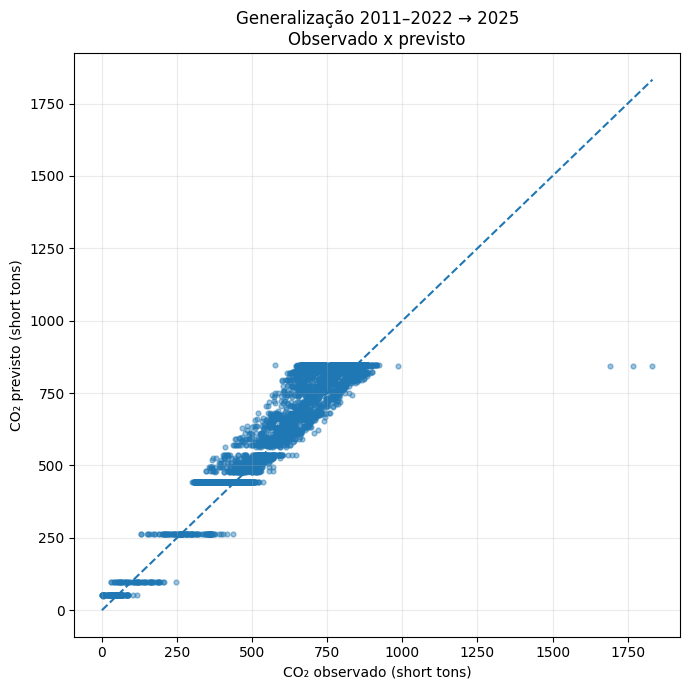

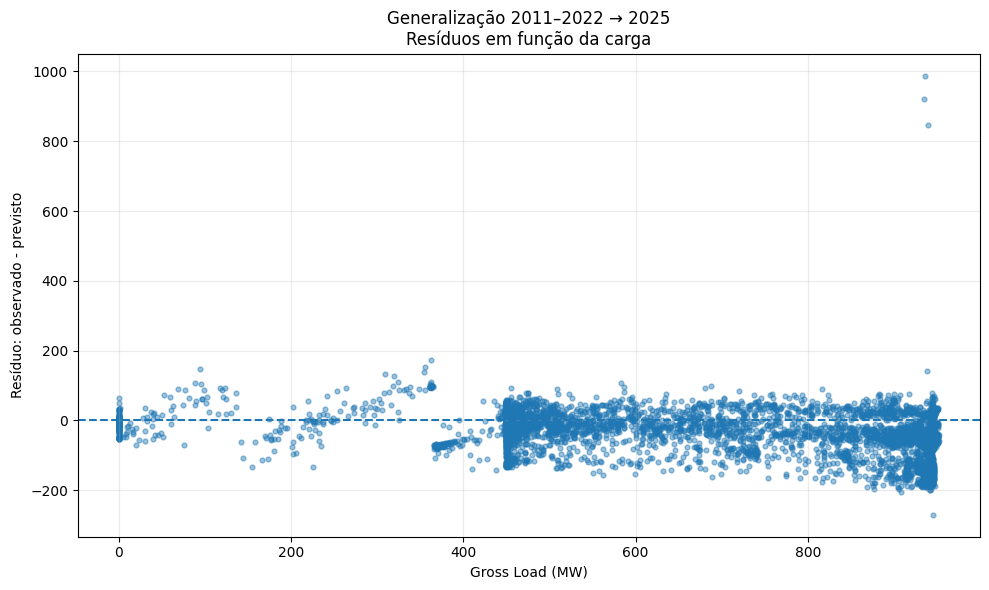

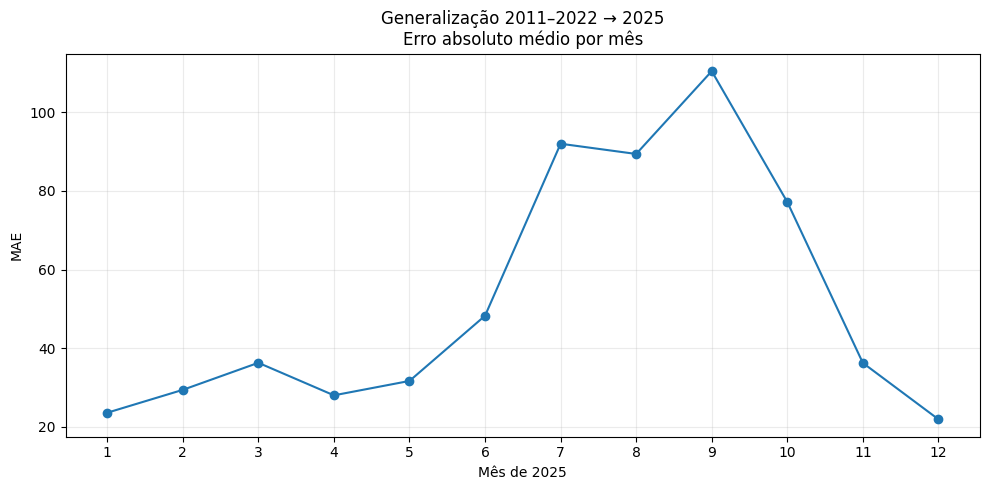


TIPOS DA BASE DE PREVISÕES
timestamp          datetime64[ns]
Gross Load (MW)           float64
CO2_observed              float64
CO2_predicted             float32
residual                  float64
absolute_error            float64
month                       int32
load_range         string[python]
dtype: object

Parquet salvo com sucesso.

SÍNTESE DO EXPERIMENTO

Experimento:

    treinamento = 2011–2022
    2023–2024 = não utilizados
    teste = 2025

Modelo:

    XGBoost
    Cenário A
    feature = Gross Load (MW)

Complexidade selecionada:

    199 árvores

Resultado out-of-time:

    MAE   = 50.2445
    RMSE  = 68.4346
    R²    = 0.8895
    NMAE  = 8.64%
    Bias  = -33.8896

Essas métricas respondem diretamente se a relação aprendida no
período histórico de referência 2011–2022 é transferível para
2025 sem utilizar dados de 2023 ou 2024.


Arquivos gerados:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A04_generalizacao_2011_2022_para_2025.csv
/content/drive/

In [14]:
# ============================================================
# CÉLULA 9: GENERALIZAÇÃO HISTÓRICA
# CENÁRIO A
#
#                 2011–2022 -> 2025
# ============================================================
#
# PERGUNTA
# ------------------------------------------------------------
#
# O conhecimento acumulado no período histórico de referência
# da Iatan Unit 2 é suficiente para generalizar a relação:
#
#       Gross Load (MW) -> CO2 Mass (short tons)
#
# para o ano de 2025?
#
#
# DELIMITAÇÃO TEMPORAL
# ------------------------------------------------------------
#
# HISTÓRICO DE REFERÊNCIA:
#
#       2011–2022
#
# REGIME OPERACIONAL DISTINTO:
#
#       2023–2024
#
# Esses dois anos NÃO entram:
#
#       - no treinamento;
#       - na validação;
#       - no teste.
#
# ANO FUTURO DE TESTE:
#
#       2025
#
#
# CENÁRIO
# ------------------------------------------------------------
#
# Permanece restrito ao Cenário A:
#
#       CO2(t) = f(P(t))
#
# Feature:
#
#       Gross Load (MW)
#
# Nenhuma variável de trajetória operacional é utilizada.
#
#
# PROCEDIMENTO DE VALIDAÇÃO
# ------------------------------------------------------------
#
# 1. Os últimos 20% das observações operacionais válidas de
#    2022 são utilizados como validação temporal.
#
# 2. O restante de 2011–2022 é utilizado para identificar o
#    número de árvores selecionado pelo early stopping.
#
# 3. Após definir o número de árvores, um NOVO modelo é treinado
#    utilizando TODO o período 2011–2022.
#
# 4. Esse modelo final é aplicado a 2025.
#
#
# IMPORTANTE
# ------------------------------------------------------------
#
# 2025 constitui teste out-of-time interanual.
#
# Diferentemente do Notebook 03A.02, nenhuma observação de
# 2025 é utilizada durante o treinamento.
# ============================================================


# ============================================================
# TESTE DE GENERALIZAÇÃO TEMPORAL FORA DA AMOSTRA
# ------------------------------------------------------------
# Temporal out-of-sample generalization test (ou out-of-time
# testing): a relação CO2(t) = f(P(t)) é ajustada com dados de
# 2011-2022 e avaliada em observações posteriores de 2025.
#
# A validação temporal dentro do histórico serve apenas para
# escolher a complexidade por early stopping. O número de
# árvores é então fixado, e o modelo é novamente treinado
# sobre todas as observações históricas válidas: FINAL REFIT.
# O teste de 2025 não deve orientar essa seleção.
#
# Trata-se de teste temporal posterior ao treinamento desta
# etapa, mas 2025 já foi estudado em outros experimentos; por
# isso, não é apropriado denominá-lo teste completamente cego
# em relação a todo o percurso de pesquisa.
# ============================================================
#
# 1. IMPORTAÇÕES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor


# ============================================================
# 2. CONFIGURAÇÕES
# ============================================================

SEED_LOCAL = 42

VALIDATION_FRACTION_2022 = 0.20

FEATURE_A = [
    "Gross Load (MW)"
]

TARGET_A = "CO2 Mass (short tons)"


# ============================================================
# 3. VERIFICAR AMOSTRAS DEFINIDAS NA CÉLULA 8
# ============================================================

assert (
    primary_training_sample["year"].min()
    ==
    2011
)

assert (
    primary_training_sample["year"].max()
    ==
    2022
)

assert not (
    primary_training_sample["year"]
    .isin([2023, 2024])
    .any()
)

assert (
    generalization_target["year"]
    .eq(2025)
    .all()
)


print("=" * 72)
print("GENERALIZAÇÃO HISTÓRICA DO CENÁRIO A")
print("=" * 72)


print(
    "\nHistórico disponível:",
    primary_training_sample["timestamp"].min(),
    "→",
    primary_training_sample["timestamp"].max()
)

print(
    "Observações históricas:",
    f"{len(primary_training_sample):,}"
)

print(
    "\nTeste futuro:",
    generalization_target["timestamp"].min(),
    "→",
    generalization_target["timestamp"].max()
)

print(
    "Observações de teste:",
    f"{len(generalization_target):,}"
)


# ============================================================
# 4. SEPARAR 2022 PARA VALIDAÇÃO TEMPORAL
# ============================================================

data_2022 = (
    primary_training_sample[
        primary_training_sample["year"] == 2022
    ]
    .sort_values("timestamp")
    .copy()
)


n_validation = int(
    np.ceil(
        len(data_2022)
        *
        VALIDATION_FRACTION_2022
    )
)


validation_2022 = (
    data_2022
    .tail(n_validation)
    .copy()
)


validation_start = (
    validation_2022["timestamp"].min()
)


development_train = (
    primary_training_sample[
        primary_training_sample["timestamp"]
        <
        validation_start
    ]
    .copy()
)


# ============================================================
# 5. SANITY CHECK TEMPORAL
# ============================================================

assert (
    development_train["timestamp"].max()
    <
    validation_2022["timestamp"].min()
)

assert (
    validation_2022["timestamp"].max()
    <
    generalization_target["timestamp"].min()
)

assert not (
    development_train["year"]
    .isin([2023, 2024, 2025])
    .any()
)

assert not (
    validation_2022["year"]
    .isin([2023, 2024, 2025])
    .any()
)


print("\n" + "=" * 72)
print("ETAPA DE DESENVOLVIMENTO")
print("=" * 72)


print(
    "\nTreino para early stopping:"
)

print(
    development_train["timestamp"].min(),
    "→",
    development_train["timestamp"].max()
)

print(
    "n =",
    f"{len(development_train):,}"
)


print(
    "\nValidação temporal:"
)

print(
    validation_2022["timestamp"].min(),
    "→",
    validation_2022["timestamp"].max()
)

print(
    "n =",
    f"{len(validation_2022):,}"
)


# ============================================================
# 6. MATRIZES DE DESENVOLVIMENTO
# ============================================================

X_dev = development_train[FEATURE_A]

y_dev = development_train[TARGET_A]


X_val = validation_2022[FEATURE_A]

y_val = validation_2022[TARGET_A]


# ============================================================
# 7. MODELO PARA SELEÇÃO DO NÚMERO DE ÁRVORES
# ============================================================

selection_model = XGBRegressor(

    objective="reg:squarederror",

    n_estimators=3000,

    learning_rate=0.03,

    max_depth=4,

    min_child_weight=5,

    subsample=0.80,

    colsample_bytree=0.80,

    reg_alpha=0.0,

    reg_lambda=1.0,

    eval_metric="rmse",

    early_stopping_rounds=50,

    random_state=SEED_LOCAL,

    n_jobs=-1

)


selection_model.fit(

    X_dev,
    y_dev,

    eval_set=[
        (
            X_val,
            y_val
        )
    ],

    verbose=False

)


best_iteration = (
    int(selection_model.best_iteration)
    +
    1
)


best_validation_score = float(
    selection_model.best_score
)


print("\n" + "=" * 72)
print("SELEÇÃO DA COMPLEXIDADE")
print("=" * 72)


print(
    "\nNúmero de árvores selecionado:",
    best_iteration
)


print(
    "RMSE de validação no ponto ótimo:",
    f"{best_validation_score:.4f}"
)


# ============================================================
# 8. TREINAMENTO FINAL COM TODO O HISTÓRICO 2011–2022
# ============================================================
#
# O número de árvores escolhido na etapa anterior é fixado.
#
# O modelo final utiliza TODAS as observações válidas
# de 2011 a 2022.
# ============================================================

X_history_full = (
    primary_training_sample[FEATURE_A]
)


y_history_full = (
    primary_training_sample[TARGET_A]
)


final_model = XGBRegressor(

    objective="reg:squarederror",

    n_estimators=best_iteration,

    learning_rate=0.03,

    max_depth=4,

    min_child_weight=5,

    subsample=0.80,

    colsample_bytree=0.80,

    reg_alpha=0.0,

    reg_lambda=1.0,

    eval_metric="rmse",

    random_state=SEED_LOCAL,

    n_jobs=-1

)


final_model.fit(

    X_history_full,

    y_history_full,

    verbose=False

)


print(
    "\nModelo final treinado."
)


print(
    "Observações efetivamente utilizadas:",
    f"{len(X_history_full):,}"
)


print(
    "Período efetivamente utilizado:",
    primary_training_sample["year"].min(),
    "→",
    primary_training_sample["year"].max()
)


# ============================================================
# 9. TESTE OUT-OF-TIME EM 2025
# ============================================================

X_test_2025 = (
    generalization_target[FEATURE_A]
)


y_test_2025 = (
    generalization_target[TARGET_A]
)


y_pred_2025 = final_model.predict(
    X_test_2025
)


# ============================================================
# 10. MÉTRICAS PRINCIPAIS
# ============================================================

mae_2025 = mean_absolute_error(
    y_test_2025,
    y_pred_2025
)


rmse_2025 = np.sqrt(
    mean_squared_error(
        y_test_2025,
        y_pred_2025
    )
)


r2_2025 = r2_score(
    y_test_2025,
    y_pred_2025
)


mean_co2_2025 = (
    y_test_2025.mean()
)


nmae_2025 = (
    100
    *
    mae_2025
    /
    mean_co2_2025
)


bias_2025 = np.mean(
    y_test_2025.to_numpy()
    -
    y_pred_2025
)


median_ae_2025 = np.median(
    np.abs(
        y_test_2025.to_numpy()
        -
        y_pred_2025
    )
)


results_generalization = pd.DataFrame(
    [
        {
            "train_period":
                "2011-2022",

            "excluded_regime":
                "2023-2024",

            "test_period":
                "2025",

            "n_train":
                len(X_history_full),

            "n_test":
                len(X_test_2025),

            "selected_trees":
                best_iteration,

            "MAE":
                mae_2025,

            "MedianAE":
                median_ae_2025,

            "RMSE":
                rmse_2025,

            "R2":
                r2_2025,

            "NMAE_pct":
                nmae_2025,

            "Bias_observed_minus_predicted":
                bias_2025
        }
    ]
)


print("\n" + "=" * 72)
print("RESULTADO PRINCIPAL")
print("=" * 72)


display(
    results_generalization
    .round(4)
)


# ============================================================
# 11. BASE DE PREVISÕES
# ============================================================

predictions_2025 = pd.DataFrame({

    "timestamp":
        generalization_target[
            "timestamp"
        ].to_numpy(),

    "Gross Load (MW)":
        generalization_target[
            "Gross Load (MW)"
        ].to_numpy(),

    "CO2_observed":
        y_test_2025.to_numpy(),

    "CO2_predicted":
        y_pred_2025

})


predictions_2025[
    "residual"
] = (
    predictions_2025[
        "CO2_observed"
    ]
    -
    predictions_2025[
        "CO2_predicted"
    ]
)


predictions_2025[
    "absolute_error"
] = (
    predictions_2025[
        "residual"
    ]
    .abs()
)


predictions_2025[
    "month"
] = (
    predictions_2025[
        "timestamp"
    ]
    .dt
    .month
)


# ============================================================
# 12. ERRO MENSAL
# ============================================================

monthly_diagnostic = (
    predictions_2025

    .groupby(
        "month"
    )

    .agg(

        n=(
            "CO2_observed",
            "size"
        ),

        load_mean=(
            "Gross Load (MW)",
            "mean"
        ),

        co2_mean=(
            "CO2_observed",
            "mean"
        ),

        prediction_mean=(
            "CO2_predicted",
            "mean"
        ),

        MAE=(
            "absolute_error",
            "mean"
        ),

        Bias=(
            "residual",
            "mean"
        )

    )

    .reset_index()
)


monthly_diagnostic[
    "NMAE_pct"
] = (
    100
    *
    monthly_diagnostic[
        "MAE"
    ]
    /
    monthly_diagnostic[
        "co2_mean"
    ]
)


print("\n" + "=" * 72)
print("DIAGNÓSTICO MENSAL DE 2025")
print("=" * 72)


display(
    monthly_diagnostic
    .round(3)
)


# ============================================================
# 13. ERRO POR FAIXA DE CARGA
# ============================================================
#
# CORREÇÃO IMPORTANTE
# ------------------------------------------------------------
#
# Na versão anterior, pd.cut() foi armazenado diretamente em
# predictions_2025.
#
# Isso produziu uma coluna Categorical contendo pandas.Interval.
#
# O PyArrow não consegue escrever esse tipo diretamente em
# Parquet.
#
# Agora as faixas são convertidas explicitamente para STRING.
# ============================================================

LOAD_ERROR_BINS = [

    0,
    200,
    400,
    600,
    800,
    1000,
    np.inf

]


load_range_intervals = pd.cut(

    predictions_2025[
        "Gross Load (MW)"
    ],

    bins=LOAD_ERROR_BINS,

    include_lowest=True,

    right=False

)


predictions_2025[
    "load_range"
] = [

    str(interval)
    if pd.notna(interval)
    else None

    for interval
    in load_range_intervals

]


# Garantia explícita de tipo serializável

predictions_2025[
    "load_range"
] = (
    predictions_2025[
        "load_range"
    ]
    .astype("string")
)


load_diagnostic = (

    predictions_2025

    .groupby(
        "load_range",
        dropna=False
    )

    .agg(

        n=(
            "CO2_observed",
            "size"
        ),

        load_mean=(
            "Gross Load (MW)",
            "mean"
        ),

        CO2_mean=(
            "CO2_observed",
            "mean"
        ),

        prediction_mean=(
            "CO2_predicted",
            "mean"
        ),

        MAE=(
            "absolute_error",
            "mean"
        ),

        Bias=(
            "residual",
            "mean"
        )

    )

    .reset_index()

)


print("\n" + "=" * 72)
print("ERRO POR FAIXA DE CARGA")
print("=" * 72)


display(
    load_diagnostic
    .round(3)
)


# ============================================================
# 14. FIGURA 1
# OBSERVADO X PREVISTO
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 7)
)


ax.scatter(

    predictions_2025[
        "CO2_observed"
    ],

    predictions_2025[
        "CO2_predicted"
    ],

    alpha=0.25,

    s=12

)


plot_min = min(

    predictions_2025[
        "CO2_observed"
    ].min(),

    predictions_2025[
        "CO2_predicted"
    ].min()

)


plot_max = max(

    predictions_2025[
        "CO2_observed"
    ].max(),

    predictions_2025[
        "CO2_predicted"
    ].max()

)


ax.plot(

    [
        plot_min,
        plot_max
    ],

    [
        plot_min,
        plot_max
    ],

    linestyle="--"

)


ax.set_xlabel(
    "CO₂ observado (short tons)"
)


ax.set_ylabel(
    "CO₂ previsto (short tons)"
)


ax.set_title(
    "Generalização 2011–2022 → 2025\n"
    "Observado x previsto"
)


ax.grid(
    alpha=0.25
)


plt.tight_layout()


FIG_OBS_PRED = (
    FIGURES
    /
    "03A04_generalizacao_2011_2022_2025_observado_previsto.png"
)


plt.savefig(

    FIG_OBS_PRED,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 15. FIGURA 2
# RESÍDUO X CARGA
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)


ax.scatter(

    predictions_2025[
        "Gross Load (MW)"
    ],

    predictions_2025[
        "residual"
    ],

    alpha=0.25,

    s=12

)


ax.axhline(
    0,
    linestyle="--"
)


ax.set_xlabel(
    "Gross Load (MW)"
)


ax.set_ylabel(
    "Resíduo: observado - previsto"
)


ax.set_title(
    "Generalização 2011–2022 → 2025\n"
    "Resíduos em função da carga"
)


ax.grid(
    alpha=0.25
)


plt.tight_layout()


FIG_RESIDUAL_LOAD = (
    FIGURES
    /
    "03A04_generalizacao_2011_2022_2025_residuo_carga.png"
)


plt.savefig(

    FIG_RESIDUAL_LOAD,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 16. FIGURA 3
# MAE MENSAL
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 5)
)


ax.plot(

    monthly_diagnostic[
        "month"
    ],

    monthly_diagnostic[
        "MAE"
    ],

    marker="o"

)


ax.set_xlabel(
    "Mês de 2025"
)


ax.set_ylabel(
    "MAE"
)


ax.set_title(
    "Generalização 2011–2022 → 2025\n"
    "Erro absoluto médio por mês"
)


ax.set_xticks(
    range(1, 13)
)


ax.grid(
    alpha=0.25
)


plt.tight_layout()


FIG_MONTHLY_MAE = (
    FIGURES
    /
    "03A04_generalizacao_2011_2022_2025_mae_mensal.png"
)


plt.savefig(

    FIG_MONTHLY_MAE,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 17. VERIFICAÇÃO DE TIPOS ANTES DO PARQUET
# ============================================================
#
# Nenhuma coluna deve permanecer como pandas.Interval.
# ============================================================

print("\n" + "=" * 72)
print("TIPOS DA BASE DE PREVISÕES")
print("=" * 72)


print(
    predictions_2025.dtypes
)


assert not any(

    isinstance(
        dtype,
        pd.CategoricalDtype
    )

    for dtype
    in predictions_2025.dtypes

)


# ============================================================
# 18. SALVAR RESULTADOS
# ============================================================

GENERALIZATION_RESULTS_PATH = (
    TABLES
    /
    "03A04_generalizacao_2011_2022_para_2025.csv"
)


MONTHLY_DIAGNOSTIC_PATH = (
    TABLES
    /
    "03A04_generalizacao_2025_diagnostico_mensal.csv"
)


LOAD_DIAGNOSTIC_PATH = (
    TABLES
    /
    "03A04_generalizacao_2025_diagnostico_carga.csv"
)


PREDICTIONS_2025_PATH = (
    MULTIYEAR_DIR
    /
    "03A04_generalizacao_2011_2022_previsoes_2025.parquet"
)


results_generalization.to_csv(

    GENERALIZATION_RESULTS_PATH,

    index=False

)


monthly_diagnostic.to_csv(

    MONTHLY_DIAGNOSTIC_PATH,

    index=False

)


load_diagnostic.to_csv(

    LOAD_DIAGNOSTIC_PATH,

    index=False

)


predictions_2025.to_parquet(

    PREDICTIONS_2025_PATH,

    index=False

)


print(
    "\nParquet salvo com sucesso."
)


# ============================================================
# 19. SÍNTESE DO EXPERIMENTO
# ============================================================

print("\n" + "=" * 72)
print("SÍNTESE DO EXPERIMENTO")
print("=" * 72)


print(
    f"""
Experimento:

    treinamento = 2011–2022
    2023–2024 = não utilizados
    teste = 2025

Modelo:

    XGBoost
    Cenário A
    feature = Gross Load (MW)

Complexidade selecionada:

    {best_iteration} árvores

Resultado out-of-time:

    MAE   = {mae_2025:.4f}
    RMSE  = {rmse_2025:.4f}
    R²    = {r2_2025:.4f}
    NMAE  = {nmae_2025:.2f}%
    Bias  = {bias_2025:.4f}

Essas métricas respondem diretamente se a relação aprendida no
período histórico de referência 2011–2022 é transferível para
2025 sem utilizar dados de 2023 ou 2024.
"""
)


# ============================================================
# 20. CAMINHOS GERADOS
# ============================================================

print(
    "\nArquivos gerados:"
)


for path in [

    GENERALIZATION_RESULTS_PATH,
    MONTHLY_DIAGNOSTIC_PATH,
    LOAD_DIAGNOSTIC_PATH,
    PREDICTIONS_2025_PATH,
    FIG_OBS_PRED,
    FIG_RESIDUAL_LOAD,
    FIG_MONTHLY_MAE

]:

    print(
        path
    )

VALOR INCREMENTAL DO HISTÓRICO 2011–2022

Observações válidas de 2025: 12,498

DIVISÃO TEMPORAL DE 2025

Treino inicial recente:
2025-01-01 16:00:00 → 2025-09-30 23:00:00
n = 9,788

Validação:
2025-10-01 00:00:00 → 2025-10-31 23:00:00
n = 422

Teste pareado:
2025-11-01 00:00:00 → 2025-12-31 23:00:00
n = 2,288

Histórico adicional disponível:
2011-01-01 00:00:00 → 2022-12-28 02:00:00
n = 167,664

MODELO 1: 2025 APENAS

Árvores selecionadas: 114
RMSE de validação: 56.8048

MODELO 2: 2011–2022 + 2025

Árvores selecionadas: 463
RMSE de validação: 75.4125

COMPARAÇÃO PAREADA NO MESMO TESTE


,model,training_data,n_train_final,selected_trees,validation_RMSE,MAE,MedianAE,RMSE,R2,NMAE_pct,Bias
0,A_2025_only,Jan-Oct/2025,10210,114,56.8048,23.8342,20.5687,29.0005,0.9796,4.0497,9.1890
1,A_history_plus_2025,2011-2022 + Jan-Oct/2025,177874,463,75.4125,20.1855,17.5034,25.0765,0.9847,3.4298,-10.4366



GANHO AO ADICIONAR 2011–2022


,MAE_gain_pct,RMSE_gain_pct,NMAE_gain_pct,R2_change,absolute_bias_gain_pct
0,15.3085,13.531,15.3085,0.0052,-13.5779



COMPARAÇÃO HORA A HORA

Percentual das horas em que o histórico melhorou a previsão: 66.08%
Redução média pareada do erro absoluto: 3.6487 short tons


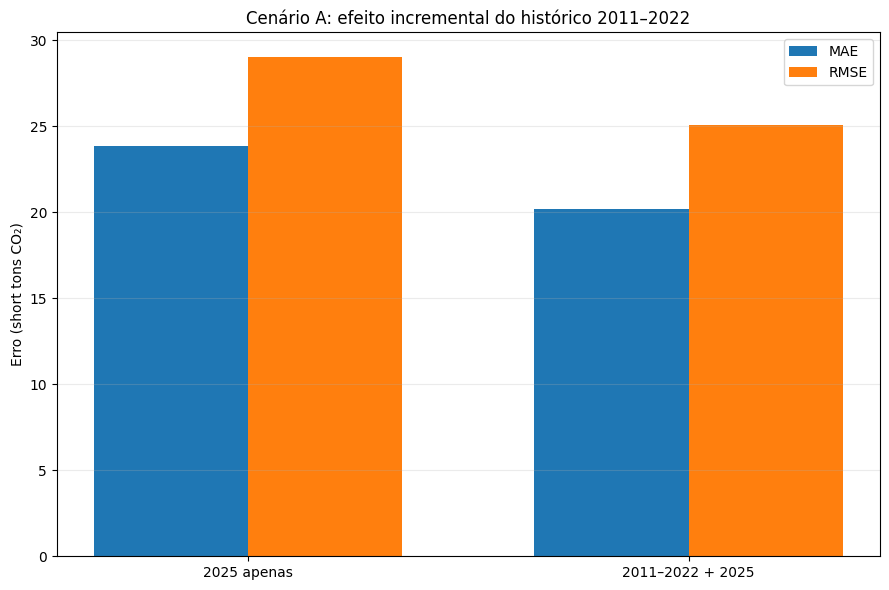

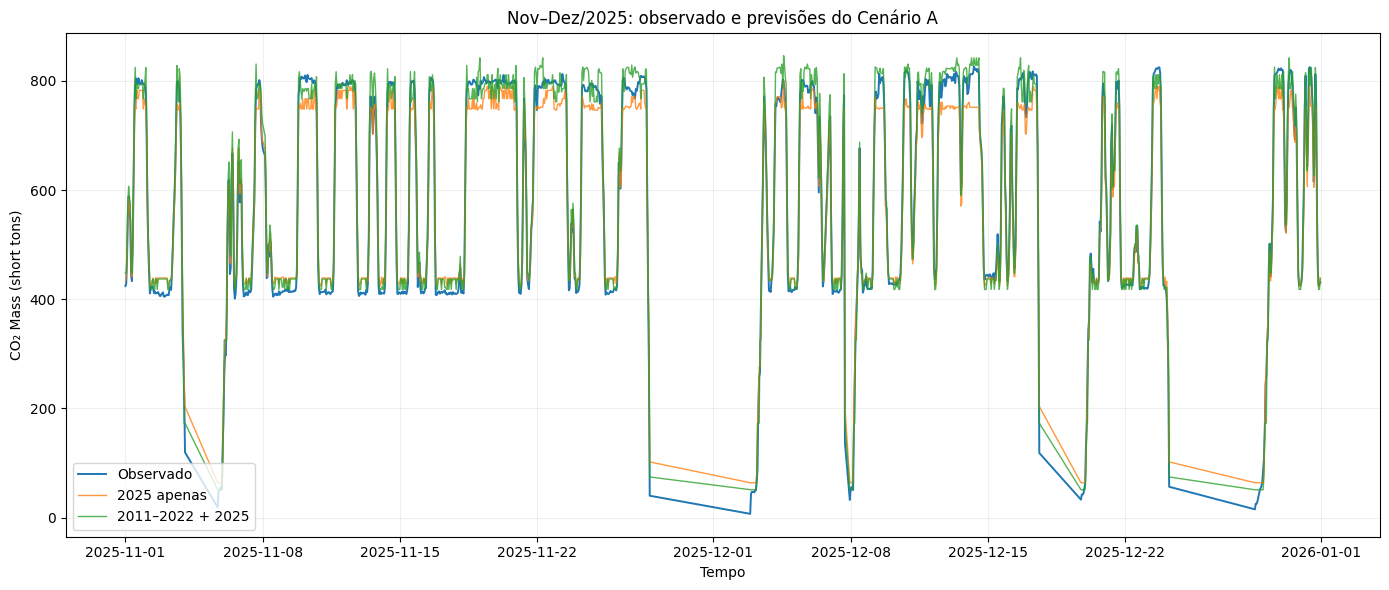


INTERPRETAÇÃO DO EXPERIMENTO

Adicionar o histórico de 2011–2022 MELHOROU a previsão
de novembro e dezembro de 2025.

Redução relativa de MAE:

    15.31%

Isso indica que o histórico contém informação preditiva
complementar mesmo quando dados recentes do próprio regime
de 2025 já estão disponíveis.


SÍNTESE

TESTE COMUM:

    novembro–dezembro/2025

MODELO 1:

    2025 apenas

    MAE  = 23.8342
    RMSE = 29.0005
    R²   = 0.9796
    NMAE = 4.05%
    Bias = 9.1890

MODELO 2:

    2011–2022 + 2025

    MAE  = 20.1855
    RMSE = 25.0765
    R²   = 0.9847
    NMAE = 3.43%
    Bias = -10.4366

GANHO DE MAE AO ADICIONAR HISTÓRICO:

    15.31%

HORAS EM QUE O MODELO COM HISTÓRICO FOI MELHOR:

    66.08%


Arquivos gerados:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A04_comparacao_2025_vs_historico_2025.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A04_ganho_incremental_historico_2011_2022.csv
/content/drive/MyDrive/co2-cems-thermal-modeling

In [15]:
# ============================================================
# CÉLULA 10: VALOR INCREMENTAL DO HISTÓRICO
# CENÁRIO A
#
#     2025 APENAS
#          VS
#     2011–2022 + 2025
# ============================================================
#
# PERGUNTA
# ------------------------------------------------------------
#
# Quando dados recentes do próprio ano de 2025 já estão
# disponíveis, acrescentar o histórico operacional de
# referência de 2011–2022 melhora a previsão futura de CO2?
#
#
# COMPARAÇÃO PAREADA
# ------------------------------------------------------------
#
# MODELO A:
#
#     Treinamento:
#         jan-set/2025
#
#     Validação:
#         out/2025
#
#     Treinamento final:
#         jan-out/2025
#
#     Teste:
#         nov-dez/2025
#
#
# MODELO A + HISTÓRICO:
#
#     Treinamento:
#         2011–2022 + jan-set/2025
#
#     Validação:
#         out/2025
#
#     Treinamento final:
#         2011–2022 + jan-out/2025
#
#     Teste:
#         nov-dez/2025
#
#
# 2023 E 2024
# ------------------------------------------------------------
#
# Permanecem completamente fora do experimento.
#
#
# CONTROLE EXPERIMENTAL
# ------------------------------------------------------------
#
# Nos dois modelos permanecem iguais:
#
#     - feature;
#     - target;
#     - algoritmo;
#     - hiperparâmetros;
#     - validação;
#     - período de teste;
#     - métricas.
#
# A diferença experimental é a disponibilidade adicional
# do histórico 2011–2022.
#
#
# CENÁRIO
# ------------------------------------------------------------
#
#       CO2(t) = f(P(t))
#
# Feature:
#
#       Gross Load (MW)
#
# ============================================================


# ============================================================
# COMPARAÇÃO CONTROLADA E PAREADA DO VALOR DO HISTÓRICO
# ------------------------------------------------------------
# Paired controlled experiment on training-history availability:
# dois modelos recebem a mesma feature, o mesmo alvo, o mesmo
# algoritmo e os mesmos períodos de validação e teste.
# A única diferença planejada é a inclusão das observações
# históricas de 2011-2022 no conjunto de treinamento.
#
# O número final de árvores pode ser diferente entre os
# modelos, pois é selecionado individualmente por early
# stopping com a mesma regra e o mesmo período de validação.
# Após fixar essa complexidade, outubro de 2025 é
# reincorporado ao treinamento de cada modelo: FINAL REFIT.
#
# O ganho é medido nas MESMAS observações futuras por MAE,
# RMSE, NMAE, R² e comparação pareada do erro por hora.
# Esse desenho controla várias fontes de variação, sem
# demonstrar isoladamente uma relação causal generalizável.
# ============================================================
#
# 1. IMPORTAÇÕES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor


# ============================================================
# 2. CONFIGURAÇÕES
# ============================================================

SEED_LOCAL = 42

FEATURE_A = [
    "Gross Load (MW)"
]

TARGET_A = "CO2 Mass (short tons)"


# ============================================================
# 3. BASE VÁLIDA DE 2025
# ============================================================
#
# Utilizamos exatamente os mesmos critérios das etapas
# anteriores:
#
#     Operating Time > 0
#     Gross Load disponível
#     CO2 disponível
#
# Gross Load = 0 permanece.
# ============================================================

data_2025 = (

    generalization_target

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

    .copy()

)


assert (
    data_2025["year"]
    .eq(2025)
    .all()
)


print("=" * 72)

print(
    "VALOR INCREMENTAL DO HISTÓRICO 2011–2022"
)

print("=" * 72)


print(
    "\nObservações válidas de 2025:",
    f"{len(data_2025):,}"
)


# ============================================================
# 4. DEFINIR PERÍODOS DE 2025
# ============================================================

TRAIN_RECENT_END = pd.Timestamp(
    "2025-09-30 23:59:59"
)

VALIDATION_START = pd.Timestamp(
    "2025-10-01 00:00:00"
)

VALIDATION_END = pd.Timestamp(
    "2025-10-31 23:59:59"
)

TEST_START = pd.Timestamp(
    "2025-11-01 00:00:00"
)

TEST_END = pd.Timestamp(
    "2025-12-31 23:59:59"
)


# ============================================================
# 5. TREINO RECENTE
# JAN-SET/2025
# ============================================================

recent_train_initial = (

    data_2025[

        data_2025[
            "timestamp"
        ]
        <=
        TRAIN_RECENT_END

    ]

    .copy()

)


# ============================================================
# 6. VALIDAÇÃO
# OUT/2025
# ============================================================

validation_2025 = (

    data_2025[

        (
            data_2025[
                "timestamp"
            ]
            >=
            VALIDATION_START
        )

        &

        (
            data_2025[
                "timestamp"
            ]
            <=
            VALIDATION_END
        )

    ]

    .copy()

)


# ============================================================
# 7. TESTE
# NOV-DEZ/2025
# ============================================================

test_2025 = (

    data_2025[

        (
            data_2025[
                "timestamp"
            ]
            >=
            TEST_START
        )

        &

        (
            data_2025[
                "timestamp"
            ]
            <=
            TEST_END
        )

    ]

    .copy()

)


# ============================================================
# 8. SANITY CHECK TEMPORAL
# ============================================================

assert not recent_train_initial.empty

assert not validation_2025.empty

assert not test_2025.empty


assert (

    recent_train_initial[
        "timestamp"
    ].max()

    <

    validation_2025[
        "timestamp"
    ].min()

)


assert (

    validation_2025[
        "timestamp"
    ].max()

    <

    test_2025[
        "timestamp"
    ].min()

)


print("\n" + "=" * 72)

print(
    "DIVISÃO TEMPORAL DE 2025"
)

print("=" * 72)


print(
    "\nTreino inicial recente:"
)

print(

    recent_train_initial[
        "timestamp"
    ].min(),

    "→",

    recent_train_initial[
        "timestamp"
    ].max()

)


print(
    "n =",
    f"{len(recent_train_initial):,}"
)


print(
    "\nValidação:"
)

print(

    validation_2025[
        "timestamp"
    ].min(),

    "→",

    validation_2025[
        "timestamp"
    ].max()

)


print(
    "n =",
    f"{len(validation_2025):,}"
)


print(
    "\nTeste pareado:"
)

print(

    test_2025[
        "timestamp"
    ].min(),

    "→",

    test_2025[
        "timestamp"
    ].max()

)


print(
    "n =",
    f"{len(test_2025):,}"
)


# ============================================================
# 9. HISTÓRICO DE REFERÊNCIA
# ============================================================

historical_reference = (

    primary_training_sample

    .sort_values(
        "timestamp"
    )

    .copy()

)


assert (
    historical_reference[
        "year"
    ].min()
    ==
    2011
)


assert (
    historical_reference[
        "year"
    ].max()
    ==
    2022
)


assert not (

    historical_reference[
        "year"
    ]

    .isin(
        [2023, 2024]
    )

    .any()

)


print(
    "\nHistórico adicional disponível:"
)


print(

    historical_reference[
        "timestamp"
    ].min(),

    "→",

    historical_reference[
        "timestamp"
    ].max()

)


print(
    "n =",
    f"{len(historical_reference):,}"
)


# ============================================================
# 10. MATRIZES DE VALIDAÇÃO E TESTE
# ============================================================

X_val = validation_2025[
    FEATURE_A
]

y_val = validation_2025[
    TARGET_A
]


X_test = test_2025[
    FEATURE_A
]

y_test = test_2025[
    TARGET_A
]


# ============================================================
# 11. FUNÇÃO DO XGBOOST
# ============================================================

def build_selection_model():

    return XGBRegressor(

        objective="reg:squarederror",

        n_estimators=3000,

        learning_rate=0.03,

        max_depth=4,

        min_child_weight=5,

        subsample=0.80,

        colsample_bytree=0.80,

        reg_alpha=0.0,

        reg_lambda=1.0,

        eval_metric="rmse",

        early_stopping_rounds=50,

        random_state=SEED_LOCAL,

        n_jobs=-1

    )


def build_final_model(
    n_estimators
):

    return XGBRegressor(

        objective="reg:squarederror",

        n_estimators=n_estimators,

        learning_rate=0.03,

        max_depth=4,

        min_child_weight=5,

        subsample=0.80,

        colsample_bytree=0.80,

        reg_alpha=0.0,

        reg_lambda=1.0,

        eval_metric="rmse",

        random_state=SEED_LOCAL,

        n_jobs=-1

    )


# ============================================================
# 12. FUNÇÃO DE MÉTRICAS
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_pred = np.asarray(
        y_pred,
        dtype=float
    )


    mae = mean_absolute_error(
        y_true,
        y_pred
    )


    rmse = np.sqrt(

        mean_squared_error(
            y_true,
            y_pred
        )

    )


    r2 = r2_score(
        y_true,
        y_pred
    )


    mean_y = np.mean(
        y_true
    )


    nmae = (

        100
        *
        mae
        /
        mean_y

        if mean_y != 0

        else np.nan

    )


    bias = np.mean(

        y_true
        -
        y_pred

    )


    median_ae = np.median(

        np.abs(
            y_true
            -
            y_pred
        )

    )


    return {

        "MAE":
            mae,

        "MedianAE":
            median_ae,

        "RMSE":
            rmse,

        "R2":
            r2,

        "NMAE_pct":
            nmae,

        "Bias":
            bias

    }


# ============================================================
# 13. MODELO 1
# CENÁRIO A COM 2025 APENAS
# ============================================================

print("\n" + "=" * 72)

print(
    "MODELO 1: 2025 APENAS"
)

print("=" * 72)


X_recent_initial = recent_train_initial[
    FEATURE_A
]

y_recent_initial = recent_train_initial[
    TARGET_A
]


model_recent_selection = (
    build_selection_model()
)


model_recent_selection.fit(

    X_recent_initial,

    y_recent_initial,

    eval_set=[

        (
            X_val,
            y_val
        )

    ],

    verbose=False

)


best_trees_recent = (

    int(
        model_recent_selection.best_iteration
    )

    +
    1

)


validation_rmse_recent = float(

    model_recent_selection.best_score

)


print(
    "\nÁrvores selecionadas:",
    best_trees_recent
)


print(
    "RMSE de validação:",
    f"{validation_rmse_recent:.4f}"
)


# ============================================================
# 14. TREINAMENTO FINAL DO MODELO 1
# JAN-OUT/2025
# ============================================================
#
# Depois de utilizar outubro para selecionar a complexidade,
# reincorporamos outubro ao treinamento final.
# ============================================================

recent_train_final = (

    pd.concat(

        [
            recent_train_initial,
            validation_2025
        ],

        ignore_index=True

    )

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


X_recent_final = recent_train_final[
    FEATURE_A
]

y_recent_final = recent_train_final[
    TARGET_A
]


model_recent_final = build_final_model(

    best_trees_recent

)


model_recent_final.fit(

    X_recent_final,

    y_recent_final,

    verbose=False

)


pred_recent = model_recent_final.predict(

    X_test

)


metrics_recent = calculate_metrics(

    y_test,

    pred_recent

)


# ============================================================
# 15. MODELO 2
# HISTÓRICO 2011–2022 + 2025
# ============================================================

print("\n" + "=" * 72)

print(
    "MODELO 2: 2011–2022 + 2025"
)

print("=" * 72)


history_plus_recent_initial = (

    pd.concat(

        [
            historical_reference,
            recent_train_initial
        ],

        ignore_index=True

    )

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


X_history_recent_initial = (

    history_plus_recent_initial[
        FEATURE_A
    ]

)


y_history_recent_initial = (

    history_plus_recent_initial[
        TARGET_A
    ]

)


model_history_selection = (
    build_selection_model()
)


model_history_selection.fit(

    X_history_recent_initial,

    y_history_recent_initial,

    eval_set=[

        (
            X_val,
            y_val
        )

    ],

    verbose=False

)


best_trees_history = (

    int(
        model_history_selection.best_iteration
    )

    +
    1

)


validation_rmse_history = float(

    model_history_selection.best_score

)


print(
    "\nÁrvores selecionadas:",
    best_trees_history
)


print(
    "RMSE de validação:",
    f"{validation_rmse_history:.4f}"
)


# ============================================================
# 16. TREINAMENTO FINAL DO MODELO 2
# 2011–2022 + JAN-OUT/2025
# ============================================================

history_plus_recent_final = (

    pd.concat(

        [
            historical_reference,
            recent_train_final
        ],

        ignore_index=True

    )

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


X_history_recent_final = (

    history_plus_recent_final[
        FEATURE_A
    ]

)


y_history_recent_final = (

    history_plus_recent_final[
        TARGET_A
    ]

)


model_history_final = build_final_model(

    best_trees_history

)


model_history_final.fit(

    X_history_recent_final,

    y_history_recent_final,

    verbose=False

)


pred_history = model_history_final.predict(

    X_test

)


metrics_history = calculate_metrics(

    y_test,

    pred_history

)


# ============================================================
# 17. RESULTADOS PAREADOS
# ============================================================

comparison_results = pd.DataFrame(

    [

        {

            "model":
                "A_2025_only",

            "training_data":
                "Jan-Oct/2025",

            "n_train_final":
                len(
                    recent_train_final
                ),

            "selected_trees":
                best_trees_recent,

            "validation_RMSE":
                validation_rmse_recent,

            **metrics_recent

        },

        {

            "model":
                "A_history_plus_2025",

            "training_data":
                "2011-2022 + Jan-Oct/2025",

            "n_train_final":
                len(
                    history_plus_recent_final
                ),

            "selected_trees":
                best_trees_history,

            "validation_RMSE":
                validation_rmse_history,

            **metrics_history

        }

    ]

)


print("\n" + "=" * 72)

print(
    "COMPARAÇÃO PAREADA NO MESMO TESTE"
)

print("=" * 72)


display(

    comparison_results

    .round(
        4
    )

)


# ============================================================
# 18. GANHO INCREMENTAL DO HISTÓRICO
# ============================================================

mae_gain_pct = (

    100

    *

    (
        metrics_recent[
            "MAE"
        ]

        -

        metrics_history[
            "MAE"
        ]
    )

    /

    metrics_recent[
        "MAE"
    ]

)


rmse_gain_pct = (

    100

    *

    (
        metrics_recent[
            "RMSE"
        ]

        -

        metrics_history[
            "RMSE"
        ]
    )

    /

    metrics_recent[
        "RMSE"
    ]

)


nmae_gain_pct = (

    100

    *

    (
        metrics_recent[
            "NMAE_pct"
        ]

        -

        metrics_history[
            "NMAE_pct"
        ]
    )

    /

    metrics_recent[
        "NMAE_pct"
    ]

)


r2_change = (

    metrics_history[
        "R2"
    ]

    -

    metrics_recent[
        "R2"
    ]

)


bias_abs_recent = abs(

    metrics_recent[
        "Bias"
    ]

)


bias_abs_history = abs(

    metrics_history[
        "Bias"
    ]

)


bias_abs_gain_pct = (

    100

    *

    (
        bias_abs_recent
        -
        bias_abs_history
    )

    /

    bias_abs_recent

    if bias_abs_recent != 0

    else np.nan

)


incremental_gain = pd.DataFrame(

    [
        {

            "MAE_gain_pct":
                mae_gain_pct,

            "RMSE_gain_pct":
                rmse_gain_pct,

            "NMAE_gain_pct":
                nmae_gain_pct,

            "R2_change":
                r2_change,

            "absolute_bias_gain_pct":
                bias_abs_gain_pct

        }
    ]

)


print("\n" + "=" * 72)

print(
    "GANHO AO ADICIONAR 2011–2022"
)

print("=" * 72)


display(

    incremental_gain

    .round(
        4
    )

)


# ============================================================
# 19. COMPARAÇÃO HORA A HORA
# ============================================================
#
# Como os dois modelos foram avaliados exatamente nas mesmas
# horas, podemos verificar qual deles apresentou menor erro
# absoluto em cada observação.
# ============================================================

paired_predictions = pd.DataFrame({

    "timestamp":
        test_2025[
            "timestamp"
        ].to_numpy(),

    "Gross Load (MW)":
        test_2025[
            "Gross Load (MW)"
        ].to_numpy(),

    "CO2_observed":
        y_test.to_numpy(),

    "prediction_2025_only":
        pred_recent,

    "prediction_history_plus_2025":
        pred_history

})


paired_predictions[
    "AE_2025_only"
] = np.abs(

    paired_predictions[
        "CO2_observed"
    ]

    -

    paired_predictions[
        "prediction_2025_only"
    ]

)


paired_predictions[
    "AE_history_plus_2025"
] = np.abs(

    paired_predictions[
        "CO2_observed"
    ]

    -

    paired_predictions[
        "prediction_history_plus_2025"
    ]

)


paired_predictions[
    "history_better"
] = (

    paired_predictions[
        "AE_history_plus_2025"
    ]

    <

    paired_predictions[
        "AE_2025_only"
    ]

)


history_win_pct = (

    100

    *

    paired_predictions[
        "history_better"
    ]

    .mean()

)


mean_paired_ae_difference = (

    paired_predictions[
        "AE_2025_only"
    ]

    -

    paired_predictions[
        "AE_history_plus_2025"
    ]

).mean()


print("\n" + "=" * 72)

print(
    "COMPARAÇÃO HORA A HORA"
)

print("=" * 72)


print(
    "\nPercentual das horas em que o histórico melhorou a previsão:",
    f"{history_win_pct:.2f}%"
)


print(
    "Redução média pareada do erro absoluto:",
    f"{mean_paired_ae_difference:.4f} short tons"
)


# ============================================================
# 20. FIGURA
# MAE E RMSE DOS DOIS MODELOS
# ============================================================

comparison_plot = pd.DataFrame({

    "Modelo": [

        "2025 apenas",
        "2011–2022 + 2025"

    ],

    "MAE": [

        metrics_recent[
            "MAE"
        ],

        metrics_history[
            "MAE"
        ]

    ],

    "RMSE": [

        metrics_recent[
            "RMSE"
        ],

        metrics_history[
            "RMSE"
        ]

    ]

})


x = np.arange(
    len(
        comparison_plot
    )
)


width = 0.35


fig, ax = plt.subplots(

    figsize=(
        9,
        6
    )

)


ax.bar(

    x
    -
    width / 2,

    comparison_plot[
        "MAE"
    ],

    width,

    label="MAE"

)


ax.bar(

    x
    +
    width / 2,

    comparison_plot[
        "RMSE"
    ],

    width,

    label="RMSE"

)


ax.set_xticks(
    x
)


ax.set_xticklabels(

    comparison_plot[
        "Modelo"
    ]

)


ax.set_ylabel(
    "Erro (short tons CO₂)"
)


ax.set_title(

    "Cenário A: efeito incremental do histórico 2011–2022"

)


ax.legend()


ax.grid(

    axis="y",

    alpha=0.25

)


plt.tight_layout()


FIG_INCREMENTAL_ERROR = (

    FIGURES
    /
    "03A04_comparacao_2025_vs_historico_2025_erros.png"

)


plt.savefig(

    FIG_INCREMENTAL_ERROR,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 21. FIGURA
# PREVISÕES NO TESTE
# ============================================================

fig, ax = plt.subplots(

    figsize=(
        14,
        6
    )

)


ax.plot(

    paired_predictions[
        "timestamp"
    ],

    paired_predictions[
        "CO2_observed"
    ],

    label="Observado",

    linewidth=1.4

)


ax.plot(

    paired_predictions[
        "timestamp"
    ],

    paired_predictions[
        "prediction_2025_only"
    ],

    label="2025 apenas",

    linewidth=1.0,

    alpha=0.8

)


ax.plot(

    paired_predictions[
        "timestamp"
    ],

    paired_predictions[
        "prediction_history_plus_2025"
    ],

    label="2011–2022 + 2025",

    linewidth=1.0,

    alpha=0.8

)


ax.set_xlabel(
    "Tempo"
)


ax.set_ylabel(
    "CO₂ Mass (short tons)"
)


ax.set_title(

    "Nov–Dez/2025: observado e previsões do Cenário A"

)


ax.legend()


ax.grid(
    alpha=0.2
)


plt.tight_layout()


FIG_INCREMENTAL_SERIES = (

    FIGURES
    /
    "03A04_comparacao_2025_vs_historico_2025_series.png"

)


plt.savefig(

    FIG_INCREMENTAL_SERIES,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 22. SALVAR RESULTADOS
# ============================================================

COMPARISON_PATH = (

    TABLES
    /
    "03A04_comparacao_2025_vs_historico_2025.csv"

)


GAIN_PATH = (

    TABLES
    /
    "03A04_ganho_incremental_historico_2011_2022.csv"

)


PAIRED_PREDICTIONS_PATH = (

    MULTIYEAR_DIR
    /
    "03A04_previsoes_pareadas_2025_vs_historico_2025.parquet"

)


comparison_results.to_csv(

    COMPARISON_PATH,

    index=False

)


incremental_gain.to_csv(

    GAIN_PATH,

    index=False

)


paired_predictions.to_parquet(

    PAIRED_PREDICTIONS_PATH,

    index=False

)


# ============================================================
# 23. INTERPRETAÇÃO AUTOMÁTICA
# ============================================================

print("\n" + "=" * 72)

print(
    "INTERPRETAÇÃO DO EXPERIMENTO"
)

print("=" * 72)


if mae_gain_pct > 0:

    print(
        f"""
Adicionar o histórico de 2011–2022 MELHOROU a previsão
de novembro e dezembro de 2025.

Redução relativa de MAE:

    {mae_gain_pct:.2f}%

Isso indica que o histórico contém informação preditiva
complementar mesmo quando dados recentes do próprio regime
de 2025 já estão disponíveis.
"""
    )


elif mae_gain_pct < 0:

    print(
        f"""
Adicionar o histórico de 2011–2022 PIOROU a previsão
de novembro e dezembro de 2025.

Variação relativa de MAE:

    {mae_gain_pct:.2f}%

Isso indica que, neste experimento, os dados recentes de
2025 foram mais informativos que a incorporação do histórico
mais antigo.
"""
    )


else:

    print(
        """
Não houve alteração de MAE ao acrescentar o histórico
de 2011–2022.
"""
    )


# ============================================================
# 24. SÍNTESE
# ============================================================

print("\n" + "=" * 72)

print(
    "SÍNTESE"
)

print("=" * 72)


print(
    f"""
TESTE COMUM:

    novembro–dezembro/2025

MODELO 1:

    2025 apenas

    MAE  = {metrics_recent['MAE']:.4f}
    RMSE = {metrics_recent['RMSE']:.4f}
    R²   = {metrics_recent['R2']:.4f}
    NMAE = {metrics_recent['NMAE_pct']:.2f}%
    Bias = {metrics_recent['Bias']:.4f}

MODELO 2:

    2011–2022 + 2025

    MAE  = {metrics_history['MAE']:.4f}
    RMSE = {metrics_history['RMSE']:.4f}
    R²   = {metrics_history['R2']:.4f}
    NMAE = {metrics_history['NMAE_pct']:.2f}%
    Bias = {metrics_history['Bias']:.4f}

GANHO DE MAE AO ADICIONAR HISTÓRICO:

    {mae_gain_pct:.2f}%

HORAS EM QUE O MODELO COM HISTÓRICO FOI MELHOR:

    {history_win_pct:.2f}%
"""
)


# ============================================================
# 25. CAMINHOS GERADOS
# ============================================================

print(
    "\nArquivos gerados:"
)


for path in [

    COMPARISON_PATH,
    GAIN_PATH,
    PAIRED_PREDICTIONS_PATH,
    FIG_INCREMENTAL_ERROR,
    FIG_INCREMENTAL_SERIES

]:

    print(
        path
    )

In [16]:
# ============================================================
# CÉLULA 11: RELATÓRIO DO VALOR PREDITIVO DO HISTÓRICO
# CENÁRIO A
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
#
# Consolidar os resultados obtidos nas etapas anteriores e
# registrar formalmente a conclusão sobre a utilidade do
# histórico operacional de 2011 a 2022 para o Cenário A.
#
#
# ESTA CÉLULA NÃO EXECUTA NOVO EXPERIMENTO.
#
# Ela organiza as evidências produzidas em:
#
#   Célula 8:
#       delimitação da amostra histórica;
#
#   Célula 9:
#       generalização 2011 a 2022 para 2025;
#
#   Célula 10:
#       comparação pareada entre:
#
#           2025 apenas
#
#       e
#
#           2011 a 2022 + 2025.
#
#
# CONCLUSÃO DESTA ETAPA
# ------------------------------------------------------------
#
# O objetivo desta etapa é responder:
#
#   O histórico de 2011 a 2022 acrescenta valor preditivo
#   ao Cenário A?
#
#
# A próxima etapa será tratada em outro notebook e investigará
# apenas a questão imediatamente seguinte:
#
#   Com histórico ampliado, a inclusão de variáveis de
#   trajetória operacional melhora a previsão de CO2 em
#   relação ao uso exclusivo da carga instantânea?
# ============================================================


# ============================================================
# 1. VERIFICAR RESULTADOS NECESSÁRIOS
# ============================================================

required_variables = [

    "results_generalization",
    "comparison_results",
    "incremental_gain",
    "metrics_recent",
    "metrics_history",
    "history_win_pct",
    "mean_paired_ae_difference",
    "best_trees_recent",
    "best_trees_history"

]


missing_variables = [

    variable

    for variable in required_variables

    if variable not in globals()

]


if missing_variables:

    raise RuntimeError(

        "Variáveis necessárias não encontradas: "
        +
        ", ".join(
            missing_variables
        )
        +
        ". Execute as Células 9 e 10 antes desta célula."

    )


# ============================================================
# 2. RECUPERAR RESULTADO DA GENERALIZAÇÃO HISTÓRICA
# ============================================================

historical_generalization = (

    results_generalization

    .iloc[0]

)


historical_mae = float(

    historical_generalization[
        "MAE"
    ]

)


historical_rmse = float(

    historical_generalization[
        "RMSE"
    ]

)


historical_r2 = float(

    historical_generalization[
        "R2"
    ]

)


historical_nmae = float(

    historical_generalization[
        "NMAE_pct"
    ]

)


historical_bias = float(

    historical_generalization[
        "Bias_observed_minus_predicted"
    ]

)


historical_n_train = int(

    historical_generalization[
        "n_train"
    ]

)


historical_n_test = int(

    historical_generalization[
        "n_test"
    ]

)


historical_trees = int(

    historical_generalization[
        "selected_trees"
    ]

)


# ============================================================
# 3. RECUPERAR RESULTADOS DO TESTE INCREMENTAL
# ============================================================

mae_recent = float(

    metrics_recent[
        "MAE"
    ]

)


rmse_recent = float(

    metrics_recent[
        "RMSE"
    ]

)


r2_recent = float(

    metrics_recent[
        "R2"
    ]

)


nmae_recent = float(

    metrics_recent[
        "NMAE_pct"
    ]

)


bias_recent = float(

    metrics_recent[
        "Bias"
    ]

)


mae_history = float(

    metrics_history[
        "MAE"
    ]

)


rmse_history = float(

    metrics_history[
        "RMSE"
    ]

)


r2_history = float(

    metrics_history[
        "R2"
    ]

)


nmae_history = float(

    metrics_history[
        "NMAE_pct"
    ]

)


bias_history = float(

    metrics_history[
        "Bias"
    ]

)


# ============================================================
# 4. CALCULAR GANHOS CONSOLIDADOS
# ============================================================

mae_gain_pct = (

    100

    *

    (
        mae_recent
        -
        mae_history
    )

    /

    mae_recent

)


rmse_gain_pct = (

    100

    *

    (
        rmse_recent
        -
        rmse_history
    )

    /

    rmse_recent

)


nmae_gain_pct = (

    100

    *

    (
        nmae_recent
        -
        nmae_history
    )

    /

    nmae_recent

)


r2_gain = (

    r2_history
    -
    r2_recent

)


absolute_bias_recent = abs(

    bias_recent

)


absolute_bias_history = abs(

    bias_history

)


absolute_bias_change_pct = (

    100

    *

    (
        absolute_bias_history
        -
        absolute_bias_recent
    )

    /

    absolute_bias_recent

)


# ============================================================
# 5. TABELA DE SÍNTESE DAS EVIDÊNCIAS
# ============================================================

evidence_summary = pd.DataFrame(

    [

        {

            "experiment":
                "Historical generalization",

            "training":
                "2011-2022",

            "test":
                "2025 completo",

            "MAE":
                historical_mae,

            "RMSE":
                historical_rmse,

            "R2":
                historical_r2,

            "NMAE_pct":
                historical_nmae,

            "Bias":
                historical_bias

        },

        {

            "experiment":
                "Paired baseline",

            "training":
                "Jan-Oct/2025",

            "test":
                "Nov-Dec/2025",

            "MAE":
                mae_recent,

            "RMSE":
                rmse_recent,

            "R2":
                r2_recent,

            "NMAE_pct":
                nmae_recent,

            "Bias":
                bias_recent

        },

        {

            "experiment":
                "Paired historical model",

            "training":
                "2011-2022 + Jan-Oct/2025",

            "test":
                "Nov-Dec/2025",

            "MAE":
                mae_history,

            "RMSE":
                rmse_history,

            "R2":
                r2_history,

            "NMAE_pct":
                nmae_history,

            "Bias":
                bias_history

        }

    ]

)


print("=" * 72)

print(
    "SÍNTESE DAS EVIDÊNCIAS DO HISTÓRICO"
)

print("=" * 72)


display(

    evidence_summary

    .round(
        4
    )

)


# ============================================================
# 6. TABELA DO GANHO INCREMENTAL
# ============================================================

incremental_summary = pd.DataFrame(

    [

        {

            "metric":
                "MAE",

            "2025_only":
                mae_recent,

            "history_plus_2025":
                mae_history,

            "relative_improvement_pct":
                mae_gain_pct

        },

        {

            "metric":
                "RMSE",

            "2025_only":
                rmse_recent,

            "history_plus_2025":
                rmse_history,

            "relative_improvement_pct":
                rmse_gain_pct

        },

        {

            "metric":
                "NMAE",

            "2025_only":
                nmae_recent,

            "history_plus_2025":
                nmae_history,

            "relative_improvement_pct":
                nmae_gain_pct

        }

    ]

)


print("\n" + "=" * 72)

print(
    "GANHO INCREMENTAL DO HISTÓRICO"
)

print("=" * 72)


display(

    incremental_summary

    .round(
        4
    )

)


# ============================================================
# 7. FUNÇÃO PARA TABELAS MARKDOWN
# ============================================================

def df_to_markdown_simple(
    df,
    columns,
    digits=4
):

    header = (

        "| "
        +
        " | ".join(
            columns
        )
        +
        " |"

    )


    separator = (

        "| "
        +
        " | ".join(
            ["---"] * len(columns)
        )
        +
        " |"

    )


    rows = []


    for _, row in df[
        columns
    ].iterrows():


        values = []


        for column in columns:


            value = row[
                column
            ]


            if isinstance(

                value,

                (
                    float,
                    np.floating
                )

            ):

                value = (
                    f"{value:.{digits}f}"
                )


            values.append(
                str(value)
            )


        rows.append(

            "| "
            +
            " | ".join(
                values
            )
            +
            " |"

        )


    return "\n".join(

        [
            header,
            separator,
            *rows
        ]

    )


# ============================================================
# 8. CONSTRUIR TABELAS DO RELATÓRIO
# ============================================================

generalization_table_md = df_to_markdown_simple(

    evidence_summary,

    [

        "experiment",
        "training",
        "test",
        "MAE",
        "RMSE",
        "R2",
        "NMAE_pct",
        "Bias"

    ]

)


incremental_table_md = df_to_markdown_simple(

    incremental_summary,

    [

        "metric",
        "2025_only",
        "history_plus_2025",
        "relative_improvement_pct"

    ]

)


# ============================================================
# 9. CLASSIFICAÇÃO AUTOMÁTICA DA EVIDÊNCIA
# ============================================================

if (

    mae_gain_pct > 0

    and

    rmse_gain_pct > 0

    and

    history_win_pct > 50

):


    evidence_conclusion = (

        "Os resultados fornecem evidência consistente de que "
        "o histórico de 2011 a 2022 possui valor preditivo "
        "incremental para o Cenário A."

    )


else:


    evidence_conclusion = (

        "Os resultados não fornecem evidência suficientemente "
        "consistente de ganho incremental associado ao histórico "
        "de 2011 a 2022 para o Cenário A."

    )


# ============================================================
# 10. GERAR RELATÓRIO EM MARKDOWN
# ============================================================

report_text = f"""
# Relatório do valor preditivo do histórico operacional

## Notebook 03A.04

### Cenário A

`CO2(t) = f(P(t))`

Este relatório consolida os resultados obtidos após a ampliação da
base histórica da Iatan Unit 2 e registra a conclusão metodológica
sobre a utilidade dos dados de 2011 a 2022 para a previsão de emissões
horárias de CO2 no Cenário A.

Nenhum novo experimento é realizado nesta etapa.

---

## 1. Objetivo

O objetivo desta sequência experimental foi determinar se a ampliação
do histórico disponível acrescenta informação útil ao modelo do
Cenário A.

A análise foi conduzida em três etapas sucessivas:

1. delimitação do período histórico de referência;
2. avaliação da capacidade de generalização do histórico para 2025;
3. avaliação do ganho incremental do histórico quando dados recentes
   de 2025 já estão disponíveis.

A pergunta central desta etapa é:

> O processamento do histórico de 2011 a 2022 acrescenta valor
> preditivo ao Cenário A?

---

## 2. Delimitação da amostra histórica

O período de 2011 a 2022 foi definido como histórico operacional de
referência.

O ano de 2010 foi retirado por representar um período parcial
associado ao commissioning e à entrada em operação comercial da
Iatan Unit 2.

Os anos de 2023 e 2024 foram classificados como período de regime
operacional distinto.

Essa decisão foi tomada antes da comparação preditiva e baseou-se em
indicadores operacionais da própria unidade, incluindo:

- proporção anual de horas em operação;
- ocorrência de carga zero durante horas operacionais;
- carga média;
- distribuição inferior de carga;
- frequência de startups.

Os anos de 2023 e 2024 permanecem preservados para análises
específicas sobre comportamento operacional e process drift, mas não
integram a amostra histórica principal desta etapa.

---

## 3. Generalização do histórico para 2025

O primeiro experimento avaliou se um modelo treinado exclusivamente no
período histórico de referência seria capaz de prever o comportamento
de 2025.

O desenho experimental foi:

**Treinamento: 2011 a 2022**

**Teste out-of-time: 2025**

O modelo final utilizou {historical_n_train:,} observações históricas e
foi avaliado em {historical_n_test:,} observações válidas de 2025.

Foram selecionadas {historical_trees} árvores.

Resultados:

- MAE = {historical_mae:.4f} short tons de CO2;
- RMSE = {historical_rmse:.4f} short tons de CO2;
- R² = {historical_r2:.4f};
- NMAE = {historical_nmae:.2f}%;
- Bias = {historical_bias:.4f} short tons de CO2.

O resultado demonstra que a relação entre carga instantânea e emissão
de CO2 aprendida no período de 2011 a 2022 mantém capacidade relevante
de transferência temporal para 2025.

O R² de {historical_r2:.4f} indica que o modelo histórico preservou
capacidade substancial de explicar a variabilidade das emissões de
2025.

Ao mesmo tempo, o NMAE de {historical_nmae:.2f}% e o bias de
{historical_bias:.4f} mostram que a transferência não é perfeita e
que existe deslocamento da relação carga e emissão entre o histórico
e 2025.

---

## 4. Valor incremental do histórico

Demonstrar que o histórico consegue prever 2025 não é suficiente para
concluir que ele acrescenta informação quando dados recentes já estão
disponíveis.

Por isso, foi executado um segundo experimento, com comparação
pareada.

Os dois modelos utilizaram:

- a mesma variável preditora;
- o mesmo alvo;
- o mesmo algoritmo;
- os mesmos hiperparâmetros;
- o mesmo período de validação;
- exatamente as mesmas 1.144 observações de teste de novembro e
  dezembro de 2025.

A diferença experimental foi a disponibilidade do histórico de
2011 a 2022.

### Modelo 1

**2025 apenas**

Treinamento final:

`Jan-Out/2025`

Número de árvores selecionado:

{best_trees_recent}

### Modelo 2

**Histórico + 2025**

Treinamento final:

`2011-2022 + Jan-Out/2025`

Número de árvores selecionado:

{best_trees_history}

---

## 5. Resultados consolidados

{generalization_table_md}

---

## 6. Ganho incremental do histórico

{incremental_table_md}

Ao acrescentar o histórico de 2011 a 2022, o MAE foi reduzido de
{mae_recent:.4f} para {mae_history:.4f} short tons de CO2.

Isso corresponde a uma redução relativa de:

**{mae_gain_pct:.2f}%**

O RMSE foi reduzido de {rmse_recent:.4f} para
{rmse_history:.4f}, correspondendo a uma melhoria de:

**{rmse_gain_pct:.2f}%**

O NMAE foi reduzido de {nmae_recent:.2f}% para
{nmae_history:.2f}%.

Além da melhoria nas métricas agregadas, o modelo com histórico
apresentou menor erro absoluto em:

**{history_win_pct:.2f}% das horas do teste.**

A redução média pareada do erro absoluto foi de:

**{mean_paired_ae_difference:.4f} short tons de CO2 por hora.**

Portanto, a melhoria não decorre apenas de um conjunto pequeno de
observações com erros extremos.

O modelo enriquecido pelo histórico apresentou menor erro absoluto na
maioria das horas avaliadas.

---

## 7. Coeficiente de determinação

O R² aumentou de:

`{r2_recent:.4f}`

para:

`{r2_history:.4f}`

correspondendo a uma variação absoluta de:

`{r2_gain:+.4f}`

Ambos os modelos já apresentam coeficiente de determinação elevado.

Por isso, a variação absoluta de R² é menor do que as mudanças
observadas no MAE e no RMSE.

Neste experimento, a redução dos erros absolutos e quadráticos é mais
informativa para avaliar o ganho incremental produzido pela inclusão
do histórico.

---

## 8. Comportamento do bias

O modelo treinado apenas com dados recentes apresentou:

`Bias = {bias_recent:.4f}`

O modelo com histórico apresentou:

`Bias = {bias_history:.4f}`

Como o bias foi definido por:

`observado - previsto`

o modelo treinado apenas com 2025 apresenta pequena tendência média de
subestimação.

O modelo enriquecido pelo histórico apresenta pequena tendência média
de superestimação.

Em magnitude absoluta, o bias passou de
{absolute_bias_recent:.4f} para {absolute_bias_history:.4f} short tons.

A redução de MAE e RMSE, portanto, não foi acompanhada por redução da
magnitude absoluta do bias.

Esse comportamento deve ser registrado como característica do modelo
com histórico, mas não invalida a melhoria observada nas métricas de
erro global.

---

## 9. Validação e complexidade dos modelos

Durante a etapa de seleção da complexidade, o modelo treinado apenas
com dados de 2025 apresentou RMSE de validação inferior ao modelo
contendo o histórico.

O período de validação correspondeu a outubro de 2025.

Essa validação foi utilizada para selecionar o número de árvores de
cada modelo antes do ajuste final.

O modelo treinado apenas com 2025 utilizou:

**{best_trees_recent} árvores**

O modelo contendo histórico utilizou:

**{best_trees_history} árvores**

Após essa etapa, outubro foi reincorporado aos respectivos conjuntos
de treinamento.

A comparação final foi realizada sobre o mesmo conjunto futuro de
novembro e dezembro de 2025.

Nesse teste comum, o modelo contendo histórico apresentou menores MAE
e RMSE.

Portanto, a avaliação final do ganho do histórico é baseada no teste
pareado e não no desempenho observado durante a etapa de seleção da
complexidade.

---

## 10. Conclusão do Notebook 03A.04

{evidence_conclusion}

O principal resultado desta etapa foi a redução de:

**{mae_gain_pct:.2f}% no MAE**

quando o histórico de 2011 a 2022 foi incorporado aos dados recentes
de 2025.

Esse ganho foi acompanhado por:

- redução de {rmse_gain_pct:.2f}% no RMSE;
- aumento do R² de {r2_recent:.4f} para {r2_history:.4f};
- redução do NMAE de {nmae_recent:.2f}% para {nmae_history:.2f}%;
- menor erro absoluto em {history_win_pct:.2f}% das horas avaliadas.

Os resultados permitem concluir que o histórico de 2011 a 2022 não é
apenas capaz de produzir previsões transferíveis para 2025.

O histórico também acrescenta informação preditiva quando combinado
com dados recentes do próprio ano de 2025.

Assim, a pergunta central do Notebook 03A.04 pode ser respondida
positivamente:

> O processamento do histórico de 2011 a 2022 acrescenta valor
> preditivo ao Cenário A?

**Sim.**

Esse resultado encerra o objetivo experimental deste notebook.

---

## 11. Relação com os experimentos anteriores

Nos experimentos anteriores, conduzidos com uma base temporal mais
restrita, a inclusão de variáveis de trajetória operacional não
produziu ganho global robusto em relação ao uso exclusivo da carga
instantânea.

Naquele contexto, o Cenário A, baseado apenas na carga instantânea,
permaneceu competitivo ou superior ao Cenário B nas avaliações
globais.

O Notebook 03A.04 introduz uma mudança importante no problema.

A base disponível para treinamento foi ampliada de forma substancial,
incorporando o período histórico de 2011 a 2022.

Essa ampliação acrescenta dezenas de milhares de observações e
aumenta a diversidade de condições operacionais representadas no
treinamento.

Por isso, a conclusão obtida anteriormente sobre as variáveis de
trajetória precisa ser reavaliada sob essa nova disponibilidade de
dados.

O Notebook 03A.04 não responde essa questão.

---

## 12. Próxima etapa

A próxima etapa será conduzida em um novo notebook.

A pergunta central será:

> Com histórico ampliado, a inclusão de variáveis de trajetória
> operacional melhora a previsão de CO2 em relação ao uso exclusivo
> da carga instantânea?

A análise comparará duas formulações:

### Cenário A

`CO2(t) = f(P(t))`

O modelo utiliza apenas a carga instantânea.

### Cenário B

`CO2(t) = f(P(t), trajetória operacional)`

O modelo incorpora, além da carga instantânea, informações que
representam o comportamento operacional recente da unidade.

A comparação deverá utilizar o mesmo protocolo temporal e o mesmo
conjunto futuro de teste para os dois cenários.

O objetivo será determinar se a ampliação da base histórica modifica
a conclusão obtida anteriormente sobre a utilidade das variáveis de
trajetória operacional.

Essa é a única questão experimental aberta ao final do Notebook
03A.04.
## 13. Fundamentação metodológica da avaliação temporal

### 13.1. Modelo supervisionado de regressão

O Cenário A emprega **XGBoost** para regressão supervisionada com
apenas `Gross Load (MW)` como variável preditora e `CO2 Mass
(short tons)` como variável-alvo. O algoritmo pertence à família
de **gradient-boosted regression trees (GBRT)**: um conjunto de
árvores de regressão é ajustado sequencialmente, de modo que as
novas árvores contribuem para reduzir o erro da função objetivo.
Não se trata de uma única árvore de decisão.

### 13.2. Process drift e possível concept drift

**Process drift** é utilizado para descrever alterações observadas
no padrão de operação da Iatan Unit 2, tais como frequência de
partidas, horas de funcionamento e distribuição da carga.

Em problemas preditivos, **concept drift** corresponde à mudança
temporal da distribuição condicional `P(Y | X)`. Para este cenário,
considera-se `P(CO2 | Gross Load)`. Diferenças nas curvas empíricas
entre anos motivam o **diagnóstico de possível concept drift**, mas
não demonstram sua ocorrência: as comparações realizadas são
descritivas e não incluem teste formal de ponto de mudança ou de
detecção estatística de concept drift.

Uma mudança na distribuição da carga ou na intensidade de operação
não implica necessariamente mudança na relação condicional entre
carga e emissões.

### 13.3. Backtesting temporal com origem móvel

A comparação de volumes históricos utiliza **rolling-origin temporal
backtesting with multiple training-window lengths**. A origem de
teste avança pelos anos-alvo de 2021, 2022, 2023, 2024 e 2025.
Para cada ano, são avaliadas janelas históricas alternativas de
1, 2, 3, 5 e 10 anos, com teste no mesmo ano-alvo.

O trimestre final do ano anterior é reservado à validação para
**early stopping**. Trata-se de múltiplas extensões fixadas para
comparação; não de uma única janela de treino automaticamente
expansiva em todas as rodadas.

### 13.4. Generalização temporal fora da amostra

O experimento `2011-2022 -> 2025` constitui um **temporal
out-of-sample generalization test**, também denominado teste
**out-of-time**. O ajuste utiliza um período histórico anterior
ao período de avaliação. O ano de 2025 é posterior ao conjunto
de treinamento dessa etapa, mas já havia sido examinado em
experimentos anteriores; por isso, não é descrito como um teste
completamente cego em toda a pesquisa.

### 13.5. Early stopping e final refit

O **early stopping** identifica a complexidade de cada XGBoost,
expressa pelo número selecionado de árvores, a partir do erro
na validação temporal. Após essa escolha, a complexidade é fixada
e ocorre um **final refit**: treinamento de um novo modelo com as
observações que estavam disponíveis antes do teste, reincorporando
os dados de validação. O teste futuro permanece separado dessa
seleção de complexidade.

### 13.6. Comparação controlada e pareada do histórico

A comparação **2025 recente** versus **2011-2022 + 2025 recente**
constitui um **paired controlled experiment on training-history
availability**. Ambos os modelos utilizam a mesma variável de
entrada, o mesmo alvo, a mesma família de algoritmo, a mesma
regra de seleção de complexidade e as mesmas observações futuras
para avaliação. O número de árvores é escolhido separadamente
para cada modelo, como previsto no protocolo.

A comparação do erro absoluto **hora a hora**, além das métricas
agregadas, caracteriza a análise pareada do valor incremental
dos dados históricos. O efeito é observado nas condições e nos
períodos avaliados e não implica, isoladamente, garantia de
benefício em outras unidades ou em anos futuros.

---

""".strip()


# ============================================================
# 11. SALVAR RELATÓRIO
# ============================================================
#
# O arquivo anterior será sobrescrito.
# ============================================================

HISTORY_VALUE_REPORT_PATH = (

    REPORTS
    /
    "03A04_relatorio_valor_preditivo_historico.md"

)


HISTORY_VALUE_REPORT_PATH.write_text(

    report_text,

    encoding="utf-8"

)


# ============================================================
# 12. SALVAR TABELA CONSOLIDADA
# ============================================================

EVIDENCE_SUMMARY_PATH = (

    TABLES
    /
    "03A04_sintese_evidencias_historico.csv"

)


evidence_summary.to_csv(

    EVIDENCE_SUMMARY_PATH,

    index=False

)


# ============================================================
# 13. EXIBIR RELATÓRIO
# ============================================================

print("\n" + "=" * 72)

print(
    "RELATÓRIO DO VALOR PREDITIVO DO HISTÓRICO"
)

print("=" * 72)


print(
    report_text
)


# ============================================================
# 14. DECISÃO EXPERIMENTAL
# ============================================================

print("\n" + "=" * 72)

print(
    "DECISÃO EXPERIMENTAL"
)

print("=" * 72)


print(
    f"""
ETAPA CONCLUÍDA:

    O histórico 2011 a 2022 agrega informação preditiva ao
    Cenário A.

RESULTADO PRINCIPAL:

    MAE 2025 apenas
        = {mae_recent:.4f}

    MAE 2011 a 2022 + 2025
        = {mae_history:.4f}

    Redução relativa
        = {mae_gain_pct:.2f}%

    Horas com menor erro após inclusão do histórico
        = {history_win_pct:.2f}%

CONCLUSÃO:

    O processamento do histórico de 2011 a 2022 acrescenta
    valor preditivo ao Cenário A.

O Notebook 03A.04 pode ser encerrado neste ponto.

PRÓXIMA ETAPA:

    Novo notebook dedicado à comparação entre Cenário A
    e Cenário B utilizando o histórico ampliado.

PRÓXIMA PERGUNTA:

    Com histórico ampliado, a inclusão de variáveis de
    trajetória operacional melhora a previsão de CO2 em
    relação ao uso exclusivo da carga instantânea?
"""
)


# ============================================================
# 15. CAMINHOS GERADOS
# ============================================================

print(
    "\nArquivos gerados:"
)


for path in [

    HISTORY_VALUE_REPORT_PATH,
    EVIDENCE_SUMMARY_PATH

]:

    print(
        path
    )

SÍNTESE DAS EVIDÊNCIAS DO HISTÓRICO


,experiment,training,test,MAE,RMSE,R2,NMAE_pct,Bias
0,Historical generalization,2011-2022,2025 completo,50.2445,68.4346,0.8895,8.6410,-33.8896
1,Paired baseline,Jan-Oct/2025,Nov-Dec/2025,23.8342,29.0005,0.9796,4.0497,9.1890
2,Paired historical model,2011-2022 + Jan-Oct/2025,Nov-Dec/2025,20.1855,25.0765,0.9847,3.4298,-10.4366



GANHO INCREMENTAL DO HISTÓRICO


,metric,2025_only,history_plus_2025,relative_improvement_pct
0,MAE,23.8342,20.1855,15.3085
1,RMSE,29.0005,25.0765,13.5310
2,NMAE,4.0497,3.4298,15.3085



RELATÓRIO DO VALOR PREDITIVO DO HISTÓRICO
# Relatório do valor preditivo do histórico operacional

## Notebook 03A.04

### Cenário A

`CO2(t) = f(P(t))`

Este relatório consolida os resultados obtidos após a ampliação da
base histórica da Iatan Unit 2 e registra a conclusão metodológica
sobre a utilidade dos dados de 2011 a 2022 para a previsão de emissões
horárias de CO2 no Cenário A.

Nenhum novo experimento é realizado nesta etapa.

---

## 1. Objetivo

O objetivo desta sequência experimental foi determinar se a ampliação
do histórico disponível acrescenta informação útil ao modelo do
Cenário A.

A análise foi conduzida em três etapas sucessivas:

1. delimitação do período histórico de referência;
2. avaliação da capacidade de generalização do histórico para 2025;
3. avaliação do ganho incremental do histórico quando dados recentes
   de 2025 já estão disponíveis.

A pergunta central desta etapa é:

> O processamento do histórico de 2011 a 2022 acrescenta valor
> preditivo ao Cenár

In [17]:
# ============================================================
# CÉLULA 11: RELATÓRIO DO VALOR PREDITIVO DO HISTÓRICO
# CENÁRIO A
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
#
# Consolidar os resultados obtidos nas etapas anteriores e
# registrar formalmente a conclusão sobre a utilidade do
# histórico operacional de 2011 a 2022 para o Cenário A.
#
#
# ESTA CÉLULA NÃO EXECUTA NOVO EXPERIMENTO.
#
# Ela organiza as evidências produzidas em:
#
#   Célula 8:
#       delimitação da amostra histórica;
#
#   Célula 9:
#       generalização 2011 a 2022 para 2025;
#
#   Célula 10:
#       comparação pareada entre:
#
#           2025 apenas
#
#       e
#
#           2011 a 2022 + 2025.
#
#
# CONCLUSÃO DESTA ETAPA
# ------------------------------------------------------------
#
# O objetivo desta etapa é responder:
#
#   O histórico de 2011 a 2022 acrescenta valor preditivo
#   ao Cenário A?
#
#
# A próxima etapa será tratada em outro notebook e investigará
# apenas a questão imediatamente seguinte:
#
#   Com histórico ampliado, a inclusão de variáveis de
#   trajetória operacional melhora a previsão de CO2 em
#   relação ao uso exclusivo da carga instantânea?
# ============================================================


# ============================================================
# 1. VERIFICAR RESULTADOS NECESSÁRIOS
# ============================================================

required_variables = [

    "results_generalization",
    "comparison_results",
    "incremental_gain",
    "metrics_recent",
    "metrics_history",
    "history_win_pct",
    "mean_paired_ae_difference",
    "best_trees_recent",
    "best_trees_history"

]


missing_variables = [

    variable

    for variable in required_variables

    if variable not in globals()

]


if missing_variables:

    raise RuntimeError(

        "Variáveis necessárias não encontradas: "
        +
        ", ".join(
            missing_variables
        )
        +
        ". Execute as Células 9 e 10 antes desta célula."

    )


# ============================================================
# 2. RECUPERAR RESULTADO DA GENERALIZAÇÃO HISTÓRICA
# ============================================================

historical_generalization = (

    results_generalization

    .iloc[0]

)


historical_mae = float(

    historical_generalization[
        "MAE"
    ]

)


historical_rmse = float(

    historical_generalization[
        "RMSE"
    ]

)


historical_r2 = float(

    historical_generalization[
        "R2"
    ]

)


historical_nmae = float(

    historical_generalization[
        "NMAE_pct"
    ]

)


historical_bias = float(

    historical_generalization[
        "Bias_observed_minus_predicted"
    ]

)


historical_n_train = int(

    historical_generalization[
        "n_train"
    ]

)


historical_n_test = int(

    historical_generalization[
        "n_test"
    ]

)


historical_trees = int(

    historical_generalization[
        "selected_trees"
    ]

)


# ============================================================
# 3. RECUPERAR RESULTADOS DO TESTE INCREMENTAL
# ============================================================

mae_recent = float(

    metrics_recent[
        "MAE"
    ]

)


rmse_recent = float(

    metrics_recent[
        "RMSE"
    ]

)


r2_recent = float(

    metrics_recent[
        "R2"
    ]

)


nmae_recent = float(

    metrics_recent[
        "NMAE_pct"
    ]

)


bias_recent = float(

    metrics_recent[
        "Bias"
    ]

)


mae_history = float(

    metrics_history[
        "MAE"
    ]

)


rmse_history = float(

    metrics_history[
        "RMSE"
    ]

)


r2_history = float(

    metrics_history[
        "R2"
    ]

)


nmae_history = float(

    metrics_history[
        "NMAE_pct"
    ]

)


bias_history = float(

    metrics_history[
        "Bias"
    ]

)


# ============================================================
# 4. CALCULAR GANHOS CONSOLIDADOS
# ============================================================

mae_gain_pct = (

    100

    *

    (
        mae_recent
        -
        mae_history
    )

    /

    mae_recent

)


rmse_gain_pct = (

    100

    *

    (
        rmse_recent
        -
        rmse_history
    )

    /

    rmse_recent

)


nmae_gain_pct = (

    100

    *

    (
        nmae_recent
        -
        nmae_history
    )

    /

    nmae_recent

)


r2_gain = (

    r2_history
    -
    r2_recent

)


absolute_bias_recent = abs(

    bias_recent

)


absolute_bias_history = abs(

    bias_history

)


absolute_bias_change_pct = (

    100

    *

    (
        absolute_bias_history
        -
        absolute_bias_recent
    )

    /

    absolute_bias_recent

)


# ============================================================
# 5. TABELA DE SÍNTESE DAS EVIDÊNCIAS
# ============================================================

evidence_summary = pd.DataFrame(

    [

        {

            "experiment":
                "Historical generalization",

            "training":
                "2011-2022",

            "test":
                "2025 completo",

            "MAE":
                historical_mae,

            "RMSE":
                historical_rmse,

            "R2":
                historical_r2,

            "NMAE_pct":
                historical_nmae,

            "Bias":
                historical_bias

        },

        {

            "experiment":
                "Paired baseline",

            "training":
                "Jan-Oct/2025",

            "test":
                "Nov-Dec/2025",

            "MAE":
                mae_recent,

            "RMSE":
                rmse_recent,

            "R2":
                r2_recent,

            "NMAE_pct":
                nmae_recent,

            "Bias":
                bias_recent

        },

        {

            "experiment":
                "Paired historical model",

            "training":
                "2011-2022 + Jan-Oct/2025",

            "test":
                "Nov-Dec/2025",

            "MAE":
                mae_history,

            "RMSE":
                rmse_history,

            "R2":
                r2_history,

            "NMAE_pct":
                nmae_history,

            "Bias":
                bias_history

        }

    ]

)


print("=" * 72)

print(
    "SÍNTESE DAS EVIDÊNCIAS DO HISTÓRICO"
)

print("=" * 72)


display(

    evidence_summary

    .round(
        4
    )

)


# ============================================================
# 6. TABELA DO GANHO INCREMENTAL
# ============================================================

incremental_summary = pd.DataFrame(

    [

        {

            "metric":
                "MAE",

            "2025_only":
                mae_recent,

            "history_plus_2025":
                mae_history,

            "relative_improvement_pct":
                mae_gain_pct

        },

        {

            "metric":
                "RMSE",

            "2025_only":
                rmse_recent,

            "history_plus_2025":
                rmse_history,

            "relative_improvement_pct":
                rmse_gain_pct

        },

        {

            "metric":
                "NMAE",

            "2025_only":
                nmae_recent,

            "history_plus_2025":
                nmae_history,

            "relative_improvement_pct":
                nmae_gain_pct

        }

    ]

)


print("\n" + "=" * 72)

print(
    "GANHO INCREMENTAL DO HISTÓRICO"
)

print("=" * 72)


display(

    incremental_summary

    .round(
        4
    )

)


# ============================================================
# 7. FUNÇÃO PARA TABELAS MARKDOWN
# ============================================================

def df_to_markdown_simple(
    df,
    columns,
    digits=4
):

    header = (

        "| "
        +
        " | ".join(
            columns
        )
        +
        " |"

    )


    separator = (

        "| "
        +
        " | ".join(
            ["---"] * len(columns)
        )
        +
        " |"

    )


    rows = []


    for _, row in df[
        columns
    ].iterrows():


        values = []


        for column in columns:


            value = row[
                column
            ]


            if isinstance(

                value,

                (
                    float,
                    np.floating
                )

            ):

                value = (
                    f"{value:.{digits}f}"
                )


            values.append(
                str(value)
            )


        rows.append(

            "| "
            +
            " | ".join(
                values
            )
            +
            " |"

        )


    return "\n".join(

        [
            header,
            separator,
            *rows
        ]

    )


# ============================================================
# 8. CONSTRUIR TABELAS DO RELATÓRIO
# ============================================================

generalization_table_md = df_to_markdown_simple(

    evidence_summary,

    [

        "experiment",
        "training",
        "test",
        "MAE",
        "RMSE",
        "R2",
        "NMAE_pct",
        "Bias"

    ]

)


incremental_table_md = df_to_markdown_simple(

    incremental_summary,

    [

        "metric",
        "2025_only",
        "history_plus_2025",
        "relative_improvement_pct"

    ]

)


# ============================================================
# 9. CLASSIFICAÇÃO AUTOMÁTICA DA EVIDÊNCIA
# ============================================================

if (

    mae_gain_pct > 0

    and

    rmse_gain_pct > 0

    and

    history_win_pct > 50

):


    evidence_conclusion = (

        "Os resultados fornecem evidência consistente de que "
        "o histórico de 2011 a 2022 possui valor preditivo "
        "incremental para o Cenário A."

    )


else:


    evidence_conclusion = (

        "Os resultados não fornecem evidência suficientemente "
        "consistente de ganho incremental associado ao histórico "
        "de 2011 a 2022 para o Cenário A."

    )


# ============================================================
# 10. GERAR RELATÓRIO EM MARKDOWN
# ============================================================

report_text = f"""
# Relatório do valor preditivo do histórico operacional

## Notebook 03A.04

### Cenário A

`CO2(t) = f(P(t))`

Este relatório consolida os resultados obtidos após a ampliação da
base histórica da Iatan Unit 2 e registra a conclusão metodológica
sobre a utilidade dos dados de 2011 a 2022 para a previsão de emissões
horárias de CO2 no Cenário A.

Nenhum novo experimento é realizado nesta etapa.

---

## 1. Objetivo

O objetivo desta sequência experimental foi determinar se a ampliação
do histórico disponível acrescenta informação útil ao modelo do
Cenário A.

A análise foi conduzida em três etapas sucessivas:

1. delimitação do período histórico de referência;
2. avaliação da capacidade de generalização do histórico para 2025;
3. avaliação do ganho incremental do histórico quando dados recentes
   de 2025 já estão disponíveis.

A pergunta central desta etapa é:

> O processamento do histórico de 2011 a 2022 acrescenta valor
> preditivo ao Cenário A?

---

## 2. Delimitação da amostra histórica

O período de 2011 a 2022 foi definido como histórico operacional de
referência.

O ano de 2010 foi retirado por representar um período parcial
associado ao commissioning e à entrada em operação comercial da
Iatan Unit 2.

Os anos de 2023 e 2024 foram classificados como período de regime
operacional distinto.

Essa decisão foi tomada antes da comparação preditiva e baseou-se em
indicadores operacionais da própria unidade, incluindo:

- proporção anual de horas em operação;
- ocorrência de carga zero durante horas operacionais;
- carga média;
- distribuição inferior de carga;
- frequência de startups.

Os anos de 2023 e 2024 permanecem preservados para análises
específicas sobre comportamento operacional e process drift, mas não
integram a amostra histórica principal desta etapa.

---

## 3. Generalização do histórico para 2025

O primeiro experimento avaliou se um modelo treinado exclusivamente no
período histórico de referência seria capaz de prever o comportamento
de 2025.

O desenho experimental foi:

**Treinamento: 2011 a 2022**

**Teste out-of-time: 2025**

O modelo final utilizou {historical_n_train:,} observações históricas e
foi avaliado em {historical_n_test:,} observações válidas de 2025.

Foram selecionadas {historical_trees} árvores.

Resultados:

- MAE = {historical_mae:.4f} short tons de CO2;
- RMSE = {historical_rmse:.4f} short tons de CO2;
- R² = {historical_r2:.4f};
- NMAE = {historical_nmae:.2f}%;
- Bias = {historical_bias:.4f} short tons de CO2.

O resultado demonstra que a relação entre carga instantânea e emissão
de CO2 aprendida no período de 2011 a 2022 mantém capacidade relevante
de transferência temporal para 2025.

O R² de {historical_r2:.4f} indica que o modelo histórico preservou
capacidade substancial de explicar a variabilidade das emissões de
2025.

Ao mesmo tempo, o NMAE de {historical_nmae:.2f}% e o bias de
{historical_bias:.4f} mostram que a transferência não é perfeita e
que existe deslocamento da relação carga e emissão entre o histórico
e 2025.

---

## 4. Valor incremental do histórico

Demonstrar que o histórico consegue prever 2025 não é suficiente para
concluir que ele acrescenta informação quando dados recentes já estão
disponíveis.

Por isso, foi executado um segundo experimento, com comparação
pareada.

Os dois modelos utilizaram:

- a mesma variável preditora;
- o mesmo alvo;
- o mesmo algoritmo;
- os mesmos hiperparâmetros;
- o mesmo período de validação;
- exatamente as mesmas 1.144 observações de teste de novembro e
  dezembro de 2025.

A diferença experimental foi a disponibilidade do histórico de
2011 a 2022.

### Modelo 1

**2025 apenas**

Treinamento final:

`Jan-Out/2025`

Número de árvores selecionado:

{best_trees_recent}

### Modelo 2

**Histórico + 2025**

Treinamento final:

`2011-2022 + Jan-Out/2025`

Número de árvores selecionado:

{best_trees_history}

---

## 5. Resultados consolidados

{generalization_table_md}

---

## 6. Ganho incremental do histórico

{incremental_table_md}

Ao acrescentar o histórico de 2011 a 2022, o MAE foi reduzido de
{mae_recent:.4f} para {mae_history:.4f} short tons de CO2.

Isso corresponde a uma redução relativa de:

**{mae_gain_pct:.2f}%**

O RMSE foi reduzido de {rmse_recent:.4f} para
{rmse_history:.4f}, correspondendo a uma melhoria de:

**{rmse_gain_pct:.2f}%**

O NMAE foi reduzido de {nmae_recent:.2f}% para
{nmae_history:.2f}%.

Além da melhoria nas métricas agregadas, o modelo com histórico
apresentou menor erro absoluto em:

**{history_win_pct:.2f}% das horas do teste.**

A redução média pareada do erro absoluto foi de:

**{mean_paired_ae_difference:.4f} short tons de CO2 por hora.**

Portanto, a melhoria não decorre apenas de um conjunto pequeno de
observações com erros extremos.

O modelo enriquecido pelo histórico apresentou menor erro absoluto na
maioria das horas avaliadas.

---

## 7. Coeficiente de determinação

O R² aumentou de:

`{r2_recent:.4f}`

para:

`{r2_history:.4f}`

correspondendo a uma variação absoluta de:

`{r2_gain:+.4f}`

Ambos os modelos já apresentam coeficiente de determinação elevado.

Por isso, a variação absoluta de R² é menor do que as mudanças
observadas no MAE e no RMSE.

Neste experimento, a redução dos erros absolutos e quadráticos é mais
informativa para avaliar o ganho incremental produzido pela inclusão
do histórico.

---

## 8. Comportamento do bias

O modelo treinado apenas com dados recentes apresentou:

`Bias = {bias_recent:.4f}`

O modelo com histórico apresentou:

`Bias = {bias_history:.4f}`

Como o bias foi definido por:

`observado - previsto`

o modelo treinado apenas com 2025 apresenta pequena tendência média de
subestimação.

O modelo enriquecido pelo histórico apresenta pequena tendência média
de superestimação.

Em magnitude absoluta, o bias passou de
{absolute_bias_recent:.4f} para {absolute_bias_history:.4f} short tons.

A redução de MAE e RMSE, portanto, não foi acompanhada por redução da
magnitude absoluta do bias.

Esse comportamento deve ser registrado como característica do modelo
com histórico, mas não invalida a melhoria observada nas métricas de
erro global.

---

## 9. Validação e complexidade dos modelos

Durante a etapa de seleção da complexidade, o modelo treinado apenas
com dados de 2025 apresentou RMSE de validação inferior ao modelo
contendo o histórico.

O período de validação correspondeu a outubro de 2025.

Essa validação foi utilizada para selecionar o número de árvores de
cada modelo antes do ajuste final.

O modelo treinado apenas com 2025 utilizou:

**{best_trees_recent} árvores**

O modelo contendo histórico utilizou:

**{best_trees_history} árvores**

Após essa etapa, outubro foi reincorporado aos respectivos conjuntos
de treinamento.

A comparação final foi realizada sobre o mesmo conjunto futuro de
novembro e dezembro de 2025.

Nesse teste comum, o modelo contendo histórico apresentou menores MAE
e RMSE.

Portanto, a avaliação final do ganho do histórico é baseada no teste
pareado e não no desempenho observado durante a etapa de seleção da
complexidade.

---

## 10. Conclusão do Notebook 03A.04

{evidence_conclusion}

O principal resultado desta etapa foi a redução de:

**{mae_gain_pct:.2f}% no MAE**

quando o histórico de 2011 a 2022 foi incorporado aos dados recentes
de 2025.

Esse ganho foi acompanhado por:

- redução de {rmse_gain_pct:.2f}% no RMSE;
- aumento do R² de {r2_recent:.4f} para {r2_history:.4f};
- redução do NMAE de {nmae_recent:.2f}% para {nmae_history:.2f}%;
- menor erro absoluto em {history_win_pct:.2f}% das horas avaliadas.

Os resultados permitem concluir que o histórico de 2011 a 2022 não é
apenas capaz de produzir previsões transferíveis para 2025.

O histórico também acrescenta informação preditiva quando combinado
com dados recentes do próprio ano de 2025.

Assim, a pergunta central do Notebook 03A.04 pode ser respondida
positivamente:

> O processamento do histórico de 2011 a 2022 acrescenta valor
> preditivo ao Cenário A?

**Sim.**

Esse resultado encerra o objetivo experimental deste notebook.

---

## 11. Relação com os experimentos anteriores

Nos experimentos anteriores, conduzidos com uma base temporal mais
restrita, a inclusão de variáveis de trajetória operacional não
produziu ganho global robusto em relação ao uso exclusivo da carga
instantânea.

Naquele contexto, o Cenário A, baseado apenas na carga instantânea,
permaneceu competitivo ou superior ao Cenário B nas avaliações
globais.

O Notebook 03A.04 introduz uma mudança importante no problema.

A base disponível para treinamento foi ampliada de forma substancial,
incorporando o período histórico de 2011 a 2022.

Essa ampliação acrescenta dezenas de milhares de observações e
aumenta a diversidade de condições operacionais representadas no
treinamento.

Por isso, a conclusão obtida anteriormente sobre as variáveis de
trajetória precisa ser reavaliada sob essa nova disponibilidade de
dados.

O Notebook 03A.04 não responde essa questão.

---

## 12. Próxima etapa

A próxima etapa será conduzida em um novo notebook.

A pergunta central será:

> Com histórico ampliado, a inclusão de variáveis de trajetória
> operacional melhora a previsão de CO2 em relação ao uso exclusivo
> da carga instantânea?

A análise comparará duas formulações:

### Cenário A

`CO2(t) = f(P(t))`

O modelo utiliza apenas a carga instantânea.

### Cenário B

`CO2(t) = f(P(t), trajetória operacional)`

O modelo incorpora, além da carga instantânea, informações que
representam o comportamento operacional recente da unidade.

A comparação deverá utilizar o mesmo protocolo temporal e o mesmo
conjunto futuro de teste para os dois cenários.

O objetivo será determinar se a ampliação da base histórica modifica
a conclusão obtida anteriormente sobre a utilidade das variáveis de
trajetória operacional.

Essa é a única questão experimental aberta ao final do Notebook
03A.04.
## 13. Fundamentação metodológica da avaliação temporal

### 13.1. Modelo supervisionado de regressão

O Cenário A emprega **XGBoost** para regressão supervisionada com
apenas `Gross Load (MW)` como variável preditora e `CO2 Mass
(short tons)` como variável-alvo. O algoritmo pertence à família
de **gradient-boosted regression trees (GBRT)**: um conjunto de
árvores de regressão é ajustado sequencialmente, de modo que as
novas árvores contribuem para reduzir o erro da função objetivo.
Não se trata de uma única árvore de decisão.

### 13.2. Process drift e possível concept drift

**Process drift** é utilizado para descrever alterações observadas
no padrão de operação da Iatan Unit 2, tais como frequência de
partidas, horas de funcionamento e distribuição da carga.

Em problemas preditivos, **concept drift** corresponde à mudança
temporal da distribuição condicional `P(Y | X)`. Para este cenário,
considera-se `P(CO2 | Gross Load)`. Diferenças nas curvas empíricas
entre anos motivam o **diagnóstico de possível concept drift**, mas
não demonstram sua ocorrência: as comparações realizadas são
descritivas e não incluem teste formal de ponto de mudança ou de
detecção estatística de concept drift.

Uma mudança na distribuição da carga ou na intensidade de operação
não implica necessariamente mudança na relação condicional entre
carga e emissões.

### 13.3. Backtesting temporal com origem móvel

A comparação de volumes históricos utiliza **rolling-origin temporal
backtesting with multiple training-window lengths**. A origem de
teste avança pelos anos-alvo de 2021, 2022, 2023, 2024 e 2025.
Para cada ano, são avaliadas janelas históricas alternativas de
1, 2, 3, 5 e 10 anos, com teste no mesmo ano-alvo.

O trimestre final do ano anterior é reservado à validação para
**early stopping**. Trata-se de múltiplas extensões fixadas para
comparação; não de uma única janela de treino automaticamente
expansiva em todas as rodadas.

### 13.4. Generalização temporal fora da amostra

O experimento `2011-2022 -> 2025` constitui um **temporal
out-of-sample generalization test**, também denominado teste
**out-of-time**. O ajuste utiliza um período histórico anterior
ao período de avaliação. O ano de 2025 é posterior ao conjunto
de treinamento dessa etapa, mas já havia sido examinado em
experimentos anteriores; por isso, não é descrito como um teste
completamente cego em toda a pesquisa.

### 13.5. Early stopping e final refit

O **early stopping** identifica a complexidade de cada XGBoost,
expressa pelo número selecionado de árvores, a partir do erro
na validação temporal. Após essa escolha, a complexidade é fixada
e ocorre um **final refit**: treinamento de um novo modelo com as
observações que estavam disponíveis antes do teste, reincorporando
os dados de validação. O teste futuro permanece separado dessa
seleção de complexidade.

### 13.6. Comparação controlada e pareada do histórico

A comparação **2025 recente** versus **2011-2022 + 2025 recente**
constitui um **paired controlled experiment on training-history
availability**. Ambos os modelos utilizam a mesma variável de
entrada, o mesmo alvo, a mesma família de algoritmo, a mesma
regra de seleção de complexidade e as mesmas observações futuras
para avaliação. O número de árvores é escolhido separadamente
para cada modelo, como previsto no protocolo.

A comparação do erro absoluto **hora a hora**, além das métricas
agregadas, caracteriza a análise pareada do valor incremental
dos dados históricos. O efeito é observado nas condições e nos
períodos avaliados e não implica, isoladamente, garantia de
benefício em outras unidades ou em anos futuros.

---

""".strip()


# ============================================================
# 11. SALVAR RELATÓRIO
# ============================================================
#
# O arquivo anterior será sobrescrito.
# ============================================================

HISTORY_VALUE_REPORT_PATH = (

    REPORTS
    /
    "03A04_relatorio_valor_preditivo_historico.md"

)


HISTORY_VALUE_REPORT_PATH.write_text(

    report_text,

    encoding="utf-8"

)


# ============================================================
# 12. SALVAR TABELA CONSOLIDADA
# ============================================================

EVIDENCE_SUMMARY_PATH = (

    TABLES
    /
    "03A04_sintese_evidencias_historico.csv"

)


evidence_summary.to_csv(

    EVIDENCE_SUMMARY_PATH,

    index=False

)


# ============================================================
# 13. EXIBIR RELATÓRIO
# ============================================================

print("\n" + "=" * 72)

print(
    "RELATÓRIO DO VALOR PREDITIVO DO HISTÓRICO"
)

print("=" * 72)


print(
    report_text
)


# ============================================================
# 14. DECISÃO EXPERIMENTAL
# ============================================================

print("\n" + "=" * 72)

print(
    "DECISÃO EXPERIMENTAL"
)

print("=" * 72)


print(
    f"""
ETAPA CONCLUÍDA:

    O histórico 2011 a 2022 agrega informação preditiva ao
    Cenário A.

RESULTADO PRINCIPAL:

    MAE 2025 apenas
        = {mae_recent:.4f}

    MAE 2011 a 2022 + 2025
        = {mae_history:.4f}

    Redução relativa
        = {mae_gain_pct:.2f}%

    Horas com menor erro após inclusão do histórico
        = {history_win_pct:.2f}%

CONCLUSÃO:

    O processamento do histórico de 2011 a 2022 acrescenta
    valor preditivo ao Cenário A.

O Notebook 03A.04 pode ser encerrado neste ponto.

PRÓXIMA ETAPA:

    Novo notebook dedicado à comparação entre Cenário A
    e Cenário B utilizando o histórico ampliado.

PRÓXIMA PERGUNTA:

    Com histórico ampliado, a inclusão de variáveis de
    trajetória operacional melhora a previsão de CO2 em
    relação ao uso exclusivo da carga instantânea?
"""
)


# ============================================================
# 15. CAMINHOS GERADOS
# ============================================================

print(
    "\nArquivos gerados:"
)


for path in [

    HISTORY_VALUE_REPORT_PATH,
    EVIDENCE_SUMMARY_PATH

]:

    print(
        path
    )

SÍNTESE DAS EVIDÊNCIAS DO HISTÓRICO


,experiment,training,test,MAE,RMSE,R2,NMAE_pct,Bias
0,Historical generalization,2011-2022,2025 completo,50.2445,68.4346,0.8895,8.6410,-33.8896
1,Paired baseline,Jan-Oct/2025,Nov-Dec/2025,23.8342,29.0005,0.9796,4.0497,9.1890
2,Paired historical model,2011-2022 + Jan-Oct/2025,Nov-Dec/2025,20.1855,25.0765,0.9847,3.4298,-10.4366



GANHO INCREMENTAL DO HISTÓRICO


,metric,2025_only,history_plus_2025,relative_improvement_pct
0,MAE,23.8342,20.1855,15.3085
1,RMSE,29.0005,25.0765,13.5310
2,NMAE,4.0497,3.4298,15.3085



RELATÓRIO DO VALOR PREDITIVO DO HISTÓRICO
# Relatório do valor preditivo do histórico operacional

## Notebook 03A.04

### Cenário A

`CO2(t) = f(P(t))`

Este relatório consolida os resultados obtidos após a ampliação da
base histórica da Iatan Unit 2 e registra a conclusão metodológica
sobre a utilidade dos dados de 2011 a 2022 para a previsão de emissões
horárias de CO2 no Cenário A.

Nenhum novo experimento é realizado nesta etapa.

---

## 1. Objetivo

O objetivo desta sequência experimental foi determinar se a ampliação
do histórico disponível acrescenta informação útil ao modelo do
Cenário A.

A análise foi conduzida em três etapas sucessivas:

1. delimitação do período histórico de referência;
2. avaliação da capacidade de generalização do histórico para 2025;
3. avaliação do ganho incremental do histórico quando dados recentes
   de 2025 já estão disponíveis.

A pergunta central desta etapa é:

> O processamento do histórico de 2011 a 2022 acrescenta valor
> preditivo ao Cenár